In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
# ============================================================
# CELL 1 — INSTALL REQUIRED PACKAGES
# ============================================================

!pip install -q \
    nibabel \
    SimpleITK \
    monai \
    timm \
    torch-geometric \
    scikit-image \
    opencv-python-headless \
    albumentations \
    pandas \
    openpyxl \
    tqdm \
    grad-cam

print("=" * 70)
print("Required packages installed successfully.")
print("=" * 70)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 22.4 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 54.8 MB/s eta 0:00:00
Required packages installed successfully.


In [2]:
# ============================================================
# CELL 2 — IMPORTS + GPU VERIFICATION
# ============================================================

import os
import gc
import json
import math
import time
import random
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import nibabel as nib
import cv2

from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

import torchvision
import timm

from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    average_precision_score,
    confusion_matrix
)

import albumentations as A
from albumentations.pytorch import ToTensorV2

from skimage.transform import resize
from skimage import exposure

from monai.transforms import (
    Compose,
    LoadImage,
    EnsureChannelFirst,
    ScaleIntensity,
    Resize
)

from torch_geometric.nn import GATConv

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# GPU
# ------------------------------------------------------------

print("=" * 70)
print("ENVIRONMENT INFORMATION")
print("=" * 70)

print("Python/PyTorch version :", torch.__version__)
print("Torchvision version    :", torchvision.__version__)
print("CUDA available         :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("CUDA version           :", torch.version.cuda)
    print("GPU count              :", torch.cuda.device_count())

    for i in range(torch.cuda.device_count()):
        gpu_name = torch.cuda.get_device_name(i)
        gpu_memory = torch.cuda.get_device_properties(i).total_memory / (1024**3)

        print(f"GPU {i}                 : {gpu_name}")
        print(f"GPU {i} memory         : {gpu_memory:.2f} GB")

    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print("Selected device        :", DEVICE)

print("=" * 70)
print("Imports and GPU verification completed.")
print("=" * 70)

ENVIRONMENT INFORMATION
Python/PyTorch version : 2.11.0+cu128
Torchvision version    : 0.26.0+cu128
CUDA available         : True
CUDA version           : 12.8
GPU count              : 2
GPU 0                 : Tesla T4
GPU 0 memory         : 14.56 GB
GPU 1                 : Tesla T4
GPU 1 memory         : 14.56 GB
Selected device        : cuda
Imports and GPU verification completed.


In [3]:
# ============================================================
# CELL 3 — PROJECT CONFIGURATION + CHECKPOINT STRUCTURE
# ============================================================

from pathlib import Path
import json
import os

# ------------------------------------------------------------
# Kaggle paths
# ------------------------------------------------------------

KAGGLE_INPUT = Path("/kaggle/input/datasets")
PROJECT_ROOT = Path("/kaggle/working/pancreatic_tumor_project")

VOLUME_ROOT = KAGGLE_INPUT / "asham2006" / "volume-file" / "Volume files"
TUMOR_ROOT  = KAGGLE_INPUT / "asham2006" / "tumor-segmentation" / "Tumor_segmentations"

# ------------------------------------------------------------
# Persistent project directories
# ------------------------------------------------------------

CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"
HISTORY_ROOT    = PROJECT_ROOT / "histories"
SPLIT_ROOT      = PROJECT_ROOT / "splits"
RESULT_ROOT     = PROJECT_ROOT / "test_results"
BACKUP_ROOT     = PROJECT_ROOT / "backup"
LOG_ROOT        = PROJECT_ROOT / "logs"

for directory in [
    PROJECT_ROOT,
    CHECKPOINT_ROOT,
    HISTORY_ROOT,
    SPLIT_ROOT,
    RESULT_ROOT,
    BACKUP_ROOT,
    LOG_ROOT
]:
    directory.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Segmentation configuration
# ------------------------------------------------------------

NUM_CLASSES = 2

# 0 = background
# 1 = tumor

IMAGE_SIZE = 224
PATCH_SIZE = 224

# ------------------------------------------------------------
# CT preprocessing
# ------------------------------------------------------------

CT_WINDOW_CENTER = 40
CT_WINDOW_WIDTH  = 400

USE_ZSCORE = True
USE_CLAHE = True

CLAHE_CLIP_LIMIT = 2.0
CLAHE_TILE_GRID = (8, 8)

# ------------------------------------------------------------
# ROI
# ------------------------------------------------------------

ROI_MARGIN = 20

# ------------------------------------------------------------
# Data split
# ------------------------------------------------------------

TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15
TEST_RATIO  = 0.15

# ------------------------------------------------------------
# Cross-validation
# ------------------------------------------------------------

N_FOLDS = 5
EPOCHS = 5

# ------------------------------------------------------------
# Training
# ------------------------------------------------------------

BATCH_SIZE = 4

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

DICE_WEIGHT = 0.70
BCE_WEIGHT = 0.30

GRAD_CLIP = 1.0

NUM_WORKERS = 0
PIN_MEMORY = True

USE_AMP = True

# ------------------------------------------------------------
# CNN + GAT
# ------------------------------------------------------------

BACKBONE = "efficientnet_b3"

GAT_HIDDEN = 128
GAT_HEADS = 4
GAT_LAYERS = 4
GAT_DROPOUT = 0.20

# ------------------------------------------------------------
# Checkpoint policy
# ------------------------------------------------------------

SAVE_EVERY_EPOCH = True
SAVE_LATEST = True
SAVE_BEST = True

BEST_METRIC = "tumor_dice"

# ------------------------------------------------------------
# Display configuration
# ------------------------------------------------------------

print("=" * 75)
print("PROJECT CONFIGURATION")
print("=" * 75)

print(f"Input dataset       : {KAGGLE_INPUT}")
print(f"Volume directory    : {VOLUME_ROOT}")
print(f"Tumor directory     : {TUMOR_ROOT}")
print()
print(f"Project root        : {PROJECT_ROOT}")
print(f"Checkpoint root     : {CHECKPOINT_ROOT}")
print(f"History root        : {HISTORY_ROOT}")
print(f"Split root          : {SPLIT_ROOT}")
print(f"Result root         : {RESULT_ROOT}")
print(f"Backup root         : {BACKUP_ROOT}")
print()
print(f"Classes             : {NUM_CLASSES}")
print("Label 0             : Background")
print("Label 1             : Tumor")
print()
print(f"Image size          : {IMAGE_SIZE} × {IMAGE_SIZE}")
print(f"ROI margin          : {ROI_MARGIN}")
print()
print(f"Train/Val/Test      : {TRAIN_RATIO}/{VAL_RATIO}/{TEST_RATIO}")
print(f"Number of folds     : {N_FOLDS}")
print(f"Epochs per fold     : {EPOCHS}")
print()
print(f"Batch size          : {BATCH_SIZE}")
print(f"Learning rate       : {LEARNING_RATE}")
print(f"Weight decay        : {WEIGHT_DECAY}")
print()
print(f"Backbone            : {BACKBONE}")
print(f"GAT layers          : {GAT_LAYERS}")
print(f"GAT hidden          : {GAT_HIDDEN}")
print(f"GAT heads           : {GAT_HEADS}")
print()
print(f"AMP                 : {USE_AMP}")
print(f"Workers             : {NUM_WORKERS}")
print()
print("Checkpoint policy:")
print("  ✓ Save every epoch")
print("  ✓ Save latest model")
print("  ✓ Save best model")
print("  ✓ Save training history")
print("  ✓ Save fold assignments")
print("=" * 75)

# ------------------------------------------------------------
# Save configuration immediately
# ------------------------------------------------------------

config = {
    "seed": SEED,
    "device": str(DEVICE),

    "volume_root": str(VOLUME_ROOT),
    "tumor_root": str(TUMOR_ROOT),

    "num_classes": NUM_CLASSES,
    "image_size": IMAGE_SIZE,
    "patch_size": PATCH_SIZE,

    "ct_window_center": CT_WINDOW_CENTER,
    "ct_window_width": CT_WINDOW_WIDTH,

    "use_zscore": USE_ZSCORE,
    "use_clahe": USE_CLAHE,
    "clahe_clip_limit": CLAHE_CLIP_LIMIT,
    "clahe_tile_grid": CLAHE_TILE_GRID,

    "roi_margin": ROI_MARGIN,

    "train_ratio": TRAIN_RATIO,
    "val_ratio": VAL_RATIO,
    "test_ratio": TEST_RATIO,

    "n_folds": N_FOLDS,
    "epochs": EPOCHS,

    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,

    "dice_weight": DICE_WEIGHT,
    "bce_weight": BCE_WEIGHT,

    "backbone": BACKBONE,
    "gat_hidden": GAT_HIDDEN,
    "gat_heads": GAT_HEADS,
    "gat_layers": GAT_LAYERS,
    "gat_dropout": GAT_DROPOUT,

    "num_workers": NUM_WORKERS,
    "pin_memory": PIN_MEMORY,
    "use_amp": USE_AMP,

    "save_every_epoch": SAVE_EVERY_EPOCH,
    "save_latest": SAVE_LATEST,
    "save_best": SAVE_BEST,
    "best_metric": BEST_METRIC
}

config_path = PROJECT_ROOT / "project_config.json"

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

print("\nConfiguration saved to:")
print(config_path)

print("\nCheckpoint directory ready:")
print(CHECKPOINT_ROOT)

print("\n✓ Cell 3 completed successfully.")

PROJECT CONFIGURATION
Input dataset       : /kaggle/input/datasets
Volume directory    : /kaggle/input/datasets/asham2006/volume-file/Volume files
Tumor directory     : /kaggle/input/datasets/asham2006/tumor-segmentation/Tumor_segmentations

Project root        : /kaggle/working/pancreatic_tumor_project
Checkpoint root     : /kaggle/working/pancreatic_tumor_project/checkpoints
History root        : /kaggle/working/pancreatic_tumor_project/histories
Split root          : /kaggle/working/pancreatic_tumor_project/splits
Result root         : /kaggle/working/pancreatic_tumor_project/test_results
Backup root         : /kaggle/working/pancreatic_tumor_project/backup

Classes             : 2
Label 0             : Background
Label 1             : Tumor

Image size          : 224 × 224
ROI margin          : 20

Train/Val/Test      : 0.7/0.15/0.15
Number of folds     : 5
Epochs per fold     : 5

Batch size          : 4
Learning rate       : 0.0001
Weight decay        : 0.0001

Backbone          

In [5]:
# ============================================================
# CELL 4 — CORRECTED DATASET INVENTORY + CT/MASK PAIRING
# ============================================================

from pathlib import Path
import pandas as pd
import re

# ------------------------------------------------------------
# Find NIfTI files
# ------------------------------------------------------------

volume_files = sorted(VOLUME_ROOT.glob("*.nii"))
tumor_files  = sorted(TUMOR_ROOT.glob("*.nii"))

print("=" * 75)
print("DATASET INVENTORY")
print("=" * 75)

print(f"CT volume files       : {len(volume_files)}")
print(f"Tumor mask files      : {len(tumor_files)}")

# ------------------------------------------------------------
# Correct patient-ID extraction
# ------------------------------------------------------------

def get_patient_id(path, is_tumor=False):
    """
    Extract a common patient ID.

    CT:
        C3L_00395.nii
        -> c3l_00395

    Tumor:
        C3L-00395_tumor.nii
        -> c3l_00395

    Also handles:
        pancreas_001.nii
        pancreas_001_tumor.nii
    """

    name = Path(path).stem.lower()

    # Remove tumor suffix from tumor masks
    name = re.sub(r"_tumor$", "", name)

    # Normalize hyphens and repeated underscores
    name = name.replace("-", "_")
    name = re.sub(r"_+", "_", name)

    return name


# ------------------------------------------------------------
# Build lookup dictionaries
# ------------------------------------------------------------

volume_map = {
    get_patient_id(p): p
    for p in volume_files
}

tumor_map = {
    get_patient_id(p, is_tumor=True): p
    for p in tumor_files
}

volume_ids = set(volume_map.keys())
tumor_ids = set(tumor_map.keys())

matched_ids = sorted(volume_ids & tumor_ids)

missing_tumor = sorted(volume_ids - tumor_ids)
missing_volume = sorted(tumor_ids - volume_ids)

# ------------------------------------------------------------
# Build manifest
# ------------------------------------------------------------

manifest_records = []

for patient_id in matched_ids:

    manifest_records.append({
        "patient_id": patient_id,
        "volume_path": str(volume_map[patient_id]),
        "tumor_mask_path": str(tumor_map[patient_id])
    })

dataset_manifest = pd.DataFrame(manifest_records)

manifest_path = PROJECT_ROOT / "dataset_manifest.csv"
dataset_manifest.to_csv(manifest_path, index=False)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PAIRING RESULTS")
print("=" * 75)

print(f"Matched patient volumes : {len(matched_ids)}")
print(f"Missing tumor masks     : {len(missing_tumor)}")
print(f"Missing CT volumes      : {len(missing_volume)}")

# ------------------------------------------------------------
# Show examples
# ------------------------------------------------------------

print("\nExample CT → tumor-mask pairs:\n")

for _, row in dataset_manifest.head(10).iterrows():

    print(f"Patient : {row['patient_id']}")
    print(f"  CT    : {Path(row['volume_path']).name}")
    print(f"  Mask  : {Path(row['tumor_mask_path']).name}")
    print()

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert len(volume_files) == 91, (
    f"Expected 91 CT volumes, found {len(volume_files)}"
)

assert len(tumor_files) == 91, (
    f"Expected 91 tumor masks, found {len(tumor_files)}"
)

assert len(matched_ids) == 91, (
    f"Expected 91 matched pairs, found {len(matched_ids)}"
)

assert len(missing_tumor) == 0
assert len(missing_volume) == 0

# ------------------------------------------------------------
# Save summary
# ------------------------------------------------------------

pairing_summary = {
    "ct_volumes": len(volume_files),
    "tumor_masks": len(tumor_files),
    "matched_pairs": len(matched_ids),
    "missing_tumor_masks": len(missing_tumor),
    "missing_ct_volumes": len(missing_volume)
}

summary_path = PROJECT_ROOT / "dataset_pairing_summary.json"

with open(summary_path, "w") as f:
    json.dump(pairing_summary, f, indent=4)

print("=" * 75)
print("✓ DATASET PAIRING SUCCESSFUL")
print("=" * 75)

print(f"Total CT volumes       : {len(volume_files)}")
print(f"Total tumor masks      : {len(tumor_files)}")
print(f"Matched pairs          : {len(matched_ids)}")
print(f"Manifest saved         : {manifest_path}")
print(f"Summary saved          : {summary_path}")

DATASET INVENTORY
CT volume files       : 91
Tumor mask files      : 91

PAIRING RESULTS
Matched patient volumes : 91
Missing tumor masks     : 0
Missing CT volumes      : 0

Example CT → tumor-mask pairs:

Patient : c3l_00395
  CT    : C3L_00395.nii
  Mask  : C3L-00395_tumor.nii

Patient : c3l_00401
  CT    : C3L_00401.nii
  Mask  : C3L-00401_tumor.nii

Patient : c3l_00599
  CT    : C3L_00599.nii
  Mask  : C3L-00599_tumor.nii

Patient : c3l_00622
  CT    : C3L_00622.nii
  Mask  : C3L-00622_tumor.nii

Patient : c3l_00625
  CT    : C3L_00625.nii
  Mask  : C3L-00625_tumor.nii

Patient : c3l_01689
  CT    : C3L_01689.nii
  Mask  : C3L-01689_tumor.nii

Patient : c3l_01702
  CT    : C3L_01702.nii
  Mask  : C3L-01702_tumor.nii

Patient : c3l_01703
  CT    : C3L_01703.nii
  Mask  : C3L-01703_tumor.nii

Patient : c3l_02109
  CT    : C3L_02109.nii
  Mask  : C3L-02109_tumor.nii

Patient : c3l_02112
  CT    : C3L_02112.nii
  Mask  : C3L-02112_tumor.nii

✓ DATASET PAIRING SUCCESSFUL
Total CT volum

In [6]:
# ============================================================
# CELL 5 — NIFTI SHAPE, SPACING, ALIGNMENT + LABEL VALIDATION
# ============================================================

import numpy as np
import nibabel as nib

# ------------------------------------------------------------
# Select representative patient
# ------------------------------------------------------------

sample_row = dataset_manifest.iloc[0]

patient_id = sample_row["patient_id"]
ct_path = sample_row["volume_path"]
mask_path = sample_row["tumor_mask_path"]

print("=" * 75)
print("NIFTI VALIDATION")
print("=" * 75)

print(f"Patient ID : {patient_id}")
print(f"CT         : {Path(ct_path).name}")
print(f"Tumor mask : {Path(mask_path).name}")

# ------------------------------------------------------------
# Load NIfTI files
# ------------------------------------------------------------

ct_img = nib.load(ct_path)
mask_img = nib.load(mask_path)

ct_data = ct_img.get_fdata()
mask_data = mask_img.get_fdata()

# ------------------------------------------------------------
# Shape
# ------------------------------------------------------------

print("\n--- SHAPE ---")

print("CT shape   :", ct_data.shape)
print("Mask shape :", mask_data.shape)

assert ct_data.shape == mask_data.shape, (
    f"Shape mismatch: CT {ct_data.shape} vs Mask {mask_data.shape}"
)

print("✓ CT and mask shapes match.")

# ------------------------------------------------------------
# Voxel spacing
# ------------------------------------------------------------

ct_spacing = ct_img.header.get_zooms()[:3]
mask_spacing = mask_img.header.get_zooms()[:3]

print("\n--- VOXEL SPACING ---")

print("CT spacing   :", ct_spacing)
print("Mask spacing :", mask_spacing)

# ------------------------------------------------------------
# Affine comparison
# ------------------------------------------------------------

print("\n--- AFFINE ---")

affine_difference = np.max(
    np.abs(ct_img.affine - mask_img.affine)
)

print("Maximum affine difference:", affine_difference)

if affine_difference < 1e-3:
    print("✓ CT and mask spatial orientation/alignment match.")
else:
    print("⚠ CT and mask affine matrices differ.")
    print("  We will investigate before training.")

# ------------------------------------------------------------
# CT intensity statistics
# ------------------------------------------------------------

finite_ct = ct_data[np.isfinite(ct_data)]

print("\n--- CT INTENSITY ---")

print("Minimum :", np.min(finite_ct))
print("Maximum :", np.max(finite_ct))
print("Mean    :", np.mean(finite_ct))
print("Std     :", np.std(finite_ct))

# ------------------------------------------------------------
# Mask labels
# ------------------------------------------------------------

print("\n--- MASK LABELS ---")

finite_mask = mask_data[np.isfinite(mask_data)]

unique_mask_values = np.unique(finite_mask)

print("Unique mask values:")
print(unique_mask_values)

# ------------------------------------------------------------
# Convert mask to binary
# ------------------------------------------------------------

binary_mask = (mask_data > 0).astype(np.uint8)

binary_labels = np.unique(binary_mask)

print("\nBinary labels:", binary_labels)

assert set(binary_labels).issubset({0, 1}), (
    f"Unexpected binary mask labels: {binary_labels}"
)

assert 1 in binary_labels, (
    "Representative tumor mask contains no tumor pixels."
)

tumor_pixels = int(np.sum(binary_mask == 1))
background_pixels = int(np.sum(binary_mask == 0))

print("Background pixels :", background_pixels)
print("Tumor pixels      :", tumor_pixels)

print("\nTumor pixel percentage:")
print(f"{100 * tumor_pixels / binary_mask.size:.4f}%")

# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("✓ NIFTI VALIDATION COMPLETED")
print("=" * 75)
print("Binary segmentation target:")
print("  0 = Background")
print("  1 = Tumor")

NIFTI VALIDATION
Patient ID : c3l_00395
CT         : C3L_00395.nii
Tumor mask : C3L-00395_tumor.nii

--- SHAPE ---
CT shape   : (512, 512, 251)
Mask shape : (512, 512, 251)
✓ CT and mask shapes match.

--- VOXEL SPACING ---
CT spacing   : (np.float32(0.78125), np.float32(0.78125), np.float32(2.0))
Mask spacing : (np.float32(0.78125), np.float32(0.78125), np.float32(2.0))

--- AFFINE ---
Maximum affine difference: 0.0
✓ CT and mask spatial orientation/alignment match.

--- CT INTENSITY ---
Minimum : -3024.0
Maximum : 3071.0
Mean    : -939.4715507932868
Std     : 1162.6136631237302

--- MASK LABELS ---
Unique mask values:
[0. 1.]

Binary labels: [0 1]
Background pixels : 65733136
Tumor pixels      : 65008

Tumor pixel percentage:
0.0988%

✓ NIFTI VALIDATION COMPLETED
Binary segmentation target:
  0 = Background
  1 = Tumor


In [7]:
# ============================================================
# CELL 6 — STRICT PATIENT-WISE TRAIN / VALIDATION / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# Patient list
# ------------------------------------------------------------

all_patients = sorted(dataset_manifest["patient_id"].unique())

print("=" * 75)
print("PATIENT-WISE DATA SPLIT")
print("=" * 75)

print(f"Total patients: {len(all_patients)}")

# ------------------------------------------------------------
# First split:
# 70% Train
# 30% Temporary
# ------------------------------------------------------------

train_patients, temp_patients = train_test_split(
    all_patients,
    test_size=(VAL_RATIO + TEST_RATIO),
    random_state=SEED,
    shuffle=True
)

# ------------------------------------------------------------
# Second split:
# Temporary -> Validation + Test
#
# Because validation:test = 15:15,
# split temporary 50/50.
# ------------------------------------------------------------

val_patients, test_patients = train_test_split(
    temp_patients,
    test_size=0.50,
    random_state=SEED,
    shuffle=True
)

# ------------------------------------------------------------
# Sort for reproducibility
# ------------------------------------------------------------

train_patients = sorted(train_patients)
val_patients   = sorted(val_patients)
test_patients  = sorted(test_patients)

# ------------------------------------------------------------
# Print split sizes
# ------------------------------------------------------------

print("\nSplit sizes:")
print(f"Train      : {len(train_patients)} patients")
print(f"Validation : {len(val_patients)} patients")
print(f"Test       : {len(test_patients)} patients")

print("\nActual percentages:")
print(f"Train      : {100 * len(train_patients) / len(all_patients):.2f}%")
print(f"Validation : {100 * len(val_patients) / len(all_patients):.2f}%")
print(f"Test       : {100 * len(test_patients) / len(all_patients):.2f}%")

# ------------------------------------------------------------
# Leakage checks
# ------------------------------------------------------------

train_set = set(train_patients)
val_set   = set(val_patients)
test_set  = set(test_patients)

assert train_set.isdisjoint(val_set)
assert train_set.isdisjoint(test_set)
assert val_set.isdisjoint(test_set)

assert len(train_set | val_set | test_set) == len(all_patients)

print("\n✓ No patient appears in more than one split.")

# ------------------------------------------------------------
# Create split DataFrame
# ------------------------------------------------------------

split_records = []

for patient in train_patients:
    split_records.append({
        "patient_id": patient,
        "split": "train"
    })

for patient in val_patients:
    split_records.append({
        "patient_id": patient,
        "split": "validation"
    })

for patient in test_patients:
    split_records.append({
        "patient_id": patient,
        "split": "test"
    })

patient_split_df = pd.DataFrame(split_records)

# ------------------------------------------------------------
# Save split
# ------------------------------------------------------------

split_csv = SPLIT_ROOT / "patient_train_val_test_split.csv"
patient_split_df.to_csv(split_csv, index=False)

# Also save JSON for easy restoration
split_json = SPLIT_ROOT / "patient_train_val_test_split.json"

split_data = {
    "seed": SEED,
    "train_patients": train_patients,
    "validation_patients": val_patients,
    "test_patients": test_patients
}

with open(split_json, "w") as f:
    json.dump(split_data, f, indent=4)

# ------------------------------------------------------------
# Display patients
# ------------------------------------------------------------

print("\nFirst 10 train patients:")
print(train_patients[:10])

print("\nValidation patients:")
print(val_patients)

print("\nTest patients:")
print(test_patients)

print("\nSaved:")
print(split_csv)
print(split_json)

print("\n" + "=" * 75)
print("✓ PATIENT-WISE SPLIT COMPLETED")
print("=" * 75)

PATIENT-WISE DATA SPLIT
Total patients: 91

Split sizes:
Train      : 63 patients
Validation : 14 patients
Test       : 14 patients

Actual percentages:
Train      : 69.23%
Validation : 15.38%
Test       : 15.38%

✓ No patient appears in more than one split.

First 10 train patients:
['c3l_00401', 'c3l_00599', 'c3l_00622', 'c3l_01689', 'c3l_01702', 'c3l_01703', 'c3l_02109', 'c3l_02112', 'c3l_02613', 'c3l_02890']

Validation patients:
['c3l_02606', 'c3l_03123', 'c3l_03624', 'c3n_00957', 'c3n_01167', 'c3n_02998', 'pancreas_054', 'pancreas_164', 'pancreas_206', 'pancreas_208', 'pancreas_216', 'pancreas_221', 'pancreas_341', 'pancreas_359']

Test patients:
['c3l_00395', 'c3l_00625', 'c3l_02115', 'c3l_02118', 'c3l_04479', 'c3n_00302', 'c3n_00511', 'c3n_01382', 'c3n_03000', 'pancreas_026', 'pancreas_202', 'pancreas_220', 'pancreas_257', 'pancreas_317']

Saved:
/kaggle/working/pancreatic_tumor_project/splits/patient_train_val_test_split.csv
/kaggle/working/pancreatic_tumor_project/splits/pati

In [8]:
# ============================================================
# CELL 7 — 5-FOLD PATIENT-WISE CROSS-VALIDATION
# ============================================================

from sklearn.model_selection import KFold

# ------------------------------------------------------------
# Use ONLY the 63 training patients for 5-fold CV
# ------------------------------------------------------------

cv_patients = np.array(train_patients)

kf = KFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=SEED
)

fold_records = []
fold_summary = []

print("=" * 75)
print("5-FOLD PATIENT-WISE CROSS-VALIDATION")
print("=" * 75)

for fold_number, (fold_train_idx, fold_val_idx) in enumerate(
    kf.split(cv_patients),
    start=1
):

    fold_train_patients = sorted(cv_patients[fold_train_idx].tolist())
    fold_val_patients   = sorted(cv_patients[fold_val_idx].tolist())

    # --------------------------------------------------------
    # Save individual patient assignments
    # --------------------------------------------------------

    for patient in fold_train_patients:
        fold_records.append({
            "fold": fold_number,
            "patient_id": patient,
            "role": "train"
        })

    for patient in fold_val_patients:
        fold_records.append({
            "fold": fold_number,
            "patient_id": patient,
            "role": "validation"
        })

    fold_summary.append({
        "fold": fold_number,
        "train_patients": len(fold_train_patients),
        "validation_patients": len(fold_val_patients)
    })

    print(
        f"Fold {fold_number}: "
        f"{len(fold_train_patients)} train patients | "
        f"{len(fold_val_patients)} validation patients"
    )

# ------------------------------------------------------------
# Save fold assignments
# ------------------------------------------------------------

fold_patient_df = pd.DataFrame(fold_records)

fold_csv = SPLIT_ROOT / "5fold_patient_assignments.csv"
fold_patient_df.to_csv(fold_csv, index=False)

fold_summary_df = pd.DataFrame(fold_summary)

summary_csv = SPLIT_ROOT / "5fold_summary.csv"
fold_summary_df.to_csv(summary_csv, index=False)

# ------------------------------------------------------------
# Save as JSON
# ------------------------------------------------------------

fold_data = {}

for fold_number in range(1, N_FOLDS + 1):

    fold_data[str(fold_number)] = {
        "train_patients": sorted(
            fold_patient_df[
                (fold_patient_df["fold"] == fold_number) &
                (fold_patient_df["role"] == "train")
            ]["patient_id"].tolist()
        ),
        "validation_patients": sorted(
            fold_patient_df[
                (fold_patient_df["fold"] == fold_number) &
                (fold_patient_df["role"] == "validation")
            ]["patient_id"].tolist()
        )
    }

fold_json = SPLIT_ROOT / "5fold_patient_assignments.json"

with open(fold_json, "w") as f:
    json.dump(fold_data, f, indent=4)

# ------------------------------------------------------------
# Verify fold integrity
# ------------------------------------------------------------

for fold_number in range(1, N_FOLDS + 1):

    fold_train = set(
        fold_patient_df[
            (fold_patient_df["fold"] == fold_number) &
            (fold_patient_df["role"] == "train")
        ]["patient_id"]
    )

    fold_val = set(
        fold_patient_df[
            (fold_patient_df["fold"] == fold_number) &
            (fold_patient_df["role"] == "validation")
        ]["patient_id"]
    )

    assert fold_train.isdisjoint(fold_val)

    assert fold_train | fold_val == set(train_patients)

# ------------------------------------------------------------
# Final verification
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FOLD SUMMARY")
print("=" * 75)

print(fold_summary_df.to_string(index=False))

print("\n✓ Each fold contains only the original 63 training patients.")
print("✓ Original 14 validation patients remain untouched.")
print("✓ Original 14 test patients remain untouched.")
print("✓ No train/validation patient overlap within any fold.")

print("\nSaved:")
print(fold_csv)
print(fold_json)
print(summary_csv)

print("\n" + "=" * 75)
print("✓ 5-FOLD SPLIT COMPLETED")
print("=" * 75)

5-FOLD PATIENT-WISE CROSS-VALIDATION
Fold 1: 50 train patients | 13 validation patients
Fold 2: 50 train patients | 13 validation patients
Fold 3: 50 train patients | 13 validation patients
Fold 4: 51 train patients | 12 validation patients
Fold 5: 51 train patients | 12 validation patients

FOLD SUMMARY
 fold  train_patients  validation_patients
    1              50                   13
    2              50                   13
    3              50                   13
    4              51                   12
    5              51                   12

✓ Each fold contains only the original 63 training patients.
✓ Original 14 validation patients remain untouched.
✓ Original 14 test patients remain untouched.
✓ No train/validation patient overlap within any fold.

Saved:
/kaggle/working/pancreatic_tumor_project/splits/5fold_patient_assignments.csv
/kaggle/working/pancreatic_tumor_project/splits/5fold_patient_assignments.json
/kaggle/working/pancreatic_tumor_project/splits/5fold_su

In [9]:
# ============================================================
# CELL 8 — BUILD SLICE-LEVEL MANIFEST
# ============================================================

import numpy as np
import nibabel as nib
from tqdm.auto import tqdm

# ------------------------------------------------------------
# Helper to determine tumor-containing slices
# ------------------------------------------------------------

def get_slice_information(patient_id, volume_path, tumor_mask_path):
    """
    Reads one CT/mask pair and records:
      - number of slices
      - whether each slice contains tumor
      - tumor pixel count per slice

    The original NIfTI files are NOT modified.
    """

    mask_img = nib.load(tumor_mask_path)
    mask_data = mask_img.get_fdata()

    # Binary tumor mask
    binary_mask = (mask_data > 0).astype(np.uint8)

    num_slices = binary_mask.shape[2]

    records = []

    for slice_idx in range(num_slices):

        mask_slice = binary_mask[:, :, slice_idx]

        tumor_pixels = int(np.sum(mask_slice))

        records.append({
            "patient_id": patient_id,
            "slice_index": slice_idx,
            "volume_path": volume_path,
            "tumor_mask_path": tumor_mask_path,
            "tumor_pixels": tumor_pixels,
            "has_tumor": int(tumor_pixels > 0)
        })

    return records


# ------------------------------------------------------------
# Build slice manifest
# ------------------------------------------------------------

slice_records = []

print("=" * 75)
print("BUILDING SLICE-LEVEL MANIFEST")
print("=" * 75)

for _, row in tqdm(
    dataset_manifest.iterrows(),
    total=len(dataset_manifest),
    desc="Processing patients"
):

    patient_records = get_slice_information(
        patient_id=row["patient_id"],
        volume_path=row["volume_path"],
        tumor_mask_path=row["tumor_mask_path"]
    )

    slice_records.extend(patient_records)


slice_manifest = pd.DataFrame(slice_records)

# ------------------------------------------------------------
# Save manifest
# ------------------------------------------------------------

slice_manifest_path = PROJECT_ROOT / "slice_manifest.csv"

slice_manifest.to_csv(
    slice_manifest_path,
    index=False
)

# ------------------------------------------------------------
# Statistics
# ------------------------------------------------------------

total_slices = len(slice_manifest)

tumor_slices = int(
    slice_manifest["has_tumor"].sum()
)

background_slices = total_slices - tumor_slices

print("\n" + "=" * 75)
print("SLICE MANIFEST SUMMARY")
print("=" * 75)

print(f"Total patients        : {slice_manifest['patient_id'].nunique()}")
print(f"Total slices          : {total_slices}")
print(f"Tumor-containing      : {tumor_slices}")
print(f"Background-only       : {background_slices}")

print(
    f"Tumor slice percentage: "
    f"{100 * tumor_slices / total_slices:.2f}%"
)

# ------------------------------------------------------------
# Split statistics
# ------------------------------------------------------------

slice_manifest["split"] = slice_manifest["patient_id"].map(
    lambda x:
        "train" if x in train_set
        else "validation" if x in val_set
        else "test"
)

print("\nSlices by patient split:")

split_summary = (
    slice_manifest
    .groupby("split")
    .agg(
        patients=("patient_id", "nunique"),
        slices=("slice_index", "count"),
        tumor_slices=("has_tumor", "sum")
    )
    .reset_index()
)

split_summary["background_slices"] = (
    split_summary["slices"] -
    split_summary["tumor_slices"]
)

print(split_summary.to_string(index=False))

# ------------------------------------------------------------
# Patient leakage verification
# ------------------------------------------------------------

for split_name, split_patients in {
    "train": train_set,
    "validation": val_set,
    "test": test_set
}.items():

    actual_patients = set(
        slice_manifest[
            slice_manifest["split"] == split_name
        ]["patient_id"]
    )

    assert actual_patients == split_patients

print("\n✓ Patient-wise slice assignment verified.")
print("✓ No slice from a patient can appear in another split.")

print("\nManifest saved to:")
print(slice_manifest_path)

print("\n" + "=" * 75)
print("✓ SLICE MANIFEST COMPLETED")
print("=" * 75)

BUILDING SLICE-LEVEL MANIFEST


Processing patients:   0%|          | 0/91 [00:00<?, ?it/s]


SLICE MANIFEST SUMMARY
Total patients        : 91
Total slices          : 14611
Tumor-containing      : 1310
Background-only       : 13301
Tumor slice percentage: 8.97%

Slices by patient split:
     split  patients  slices  tumor_slices  background_slices
      test        14    3428           278               3150
     train        63    9364           817               8547
validation        14    1819           215               1604

✓ Patient-wise slice assignment verified.
✓ No slice from a patient can appear in another split.

Manifest saved to:
/kaggle/working/pancreatic_tumor_project/slice_manifest.csv

✓ SLICE MANIFEST COMPLETED


In [10]:
# ============================================================
# CELL 9 — CT + MASK PREPROCESSING FUNCTIONS
# ============================================================

import numpy as np
import cv2

# ------------------------------------------------------------
# CT WINDOWING
# ------------------------------------------------------------

def apply_ct_window(
    image,
    center=CT_WINDOW_CENTER,
    width=CT_WINDOW_WIDTH
):
    """
    Apply a CT intensity window.

    Default:
        Window center = 40 HU
        Window width  = 400 HU

    Result is normalized to [0, 1].
    """

    lower = center - width / 2
    upper = center + width / 2

    image = np.clip(
        image,
        lower,
        upper
    )

    image = (
        (image - lower) /
        (upper - lower)
    )

    return image.astype(np.float32)


# ------------------------------------------------------------
# Z-SCORE NORMALIZATION
# ------------------------------------------------------------

def apply_zscore(image):
    """
    Z-score normalization after CT windowing.
    """

    mean = np.mean(image)
    std = np.std(image)

    if std < 1e-8:
        return np.zeros_like(
            image,
            dtype=np.float32
        )

    image = (image - mean) / std

    return image.astype(np.float32)


# ------------------------------------------------------------
# CLAHE
# ------------------------------------------------------------

def apply_clahe(
    image,
    clip_limit=CLAHE_CLIP_LIMIT,
    tile_grid=CLAHE_TILE_GRID
):
    """
    Apply CLAHE to a normalized 2D CT slice.

    CLAHE operates on [0, 255] uint8,
    then returns float32 [0, 1].
    """

    # Min-max normalize temporarily
    min_val = np.min(image)
    max_val = np.max(image)

    if max_val - min_val < 1e-8:
        return np.zeros_like(
            image,
            dtype=np.float32
        )

    normalized = (
        (image - min_val) /
        (max_val - min_val)
    )

    image_uint8 = (
        normalized * 255
    ).clip(0, 255).astype(np.uint8)

    clahe = cv2.createCLAHE(
        clipLimit=clip_limit,
        tileGridSize=tile_grid
    )

    enhanced = clahe.apply(
        image_uint8
    )

    enhanced = (
        enhanced.astype(np.float32) /
        255.0
    )

    return enhanced


# ------------------------------------------------------------
# IMAGE RESIZE
# ------------------------------------------------------------

def resize_ct_slice(
    image,
    size=IMAGE_SIZE
):
    """
    Resize CT image using bilinear interpolation.
    """

    return cv2.resize(
        image,
        (size, size),
        interpolation=cv2.INTER_LINEAR
    ).astype(np.float32)


def resize_mask(
    mask,
    size=IMAGE_SIZE
):
    """
    Resize segmentation mask using nearest-neighbor
    interpolation to preserve binary labels.
    """

    resized = cv2.resize(
        mask.astype(np.uint8),
        (size, size),
        interpolation=cv2.INTER_NEAREST
    )

    return (resized > 0).astype(np.uint8)


# ------------------------------------------------------------
# COMPLETE CT PREPROCESSING PIPELINE
# ------------------------------------------------------------

def preprocess_ct_slice(image):
    """
    Complete CT preprocessing:

        Raw HU
          ↓
        CT window
          ↓
        Z-score
          ↓
        CLAHE
          ↓
        Resize 224×224
    """

    image = image.astype(np.float32)

    # CT window
    image = apply_ct_window(image)

    # Z-score
    if USE_ZSCORE:
        image = apply_zscore(image)

    # CLAHE
    if USE_CLAHE:
        image = apply_clahe(image)

    # Resize
    image = resize_ct_slice(image)

    return image.astype(np.float32)


# ------------------------------------------------------------
# PREPROCESSING SANITY TEST
# ------------------------------------------------------------

sample_ct = ct_data[:, :, ct_data.shape[2] // 2]
sample_mask = binary_mask[:, :, binary_mask.shape[2] // 2]

processed_ct = preprocess_ct_slice(
    sample_ct
)

processed_mask = resize_mask(
    sample_mask
)

print("=" * 75)
print("PREPROCESSING SANITY CHECK")
print("=" * 75)

print("Original CT shape     :", sample_ct.shape)
print("Processed CT shape    :", processed_ct.shape)

print("Original mask shape   :", sample_mask.shape)
print("Processed mask shape  :", processed_mask.shape)

print("\nProcessed CT:")
print("  min :", np.min(processed_ct))
print("  max :", np.max(processed_ct))
print("  mean:", np.mean(processed_ct))
print("  std :", np.std(processed_ct))

print("\nProcessed mask labels:")
print(np.unique(processed_mask))

assert processed_ct.shape == (
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert processed_mask.shape == (
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert set(np.unique(processed_mask)).issubset({0, 1})

print("\n✓ CT preprocessing is valid.")
print("✓ Mask resizing preserves binary labels.")
print("=" * 75)

PREPROCESSING SANITY CHECK
Original CT shape     : (512, 512)
Processed CT shape    : (224, 224)
Original mask shape   : (512, 512)
Processed mask shape  : (224, 224)

Processed CT:
  min : 0.005322129
  max : 1.0
  mean: 0.19699743
  std : 0.2684297

Processed mask labels:
[0]

✓ CT preprocessing is valid.
✓ Mask resizing preserves binary labels.


In [11]:
# ============================================================
# CELL 10 — TUMOR-SLICE PREPROCESSING + ALIGNMENT CHECK
# ============================================================

import numpy as np
import nibabel as nib

# ------------------------------------------------------------
# Find a patient/slice that actually contains tumor
# ------------------------------------------------------------

tumor_slice_row = slice_manifest[
    slice_manifest["has_tumor"] == 1
].iloc[0]

patient_id = tumor_slice_row["patient_id"]
slice_index = int(tumor_slice_row["slice_index"])
volume_path = tumor_slice_row["volume_path"]
tumor_mask_path = tumor_slice_row["tumor_mask_path"]

print("=" * 75)
print("TUMOR-SLICE SANITY CHECK")
print("=" * 75)

print("Patient      :", patient_id)
print("Slice index  :", slice_index)

# ------------------------------------------------------------
# Load CT and mask
# ------------------------------------------------------------

ct_img = nib.load(volume_path)
mask_img = nib.load(tumor_mask_path)

ct_volume = ct_img.get_fdata().astype(np.float32)
mask_volume = mask_img.get_fdata()

ct_slice = ct_volume[:, :, slice_index]
mask_slice = (mask_volume[:, :, slice_index] > 0).astype(np.uint8)

# ------------------------------------------------------------
# Verify tumor exists before preprocessing
# ------------------------------------------------------------

original_tumor_pixels = int(mask_slice.sum())

print("\nOriginal slice:")
print("  CT shape        :", ct_slice.shape)
print("  Mask shape      :", mask_slice.shape)
print("  Tumor pixels    :", original_tumor_pixels)
print("  Mask labels     :", np.unique(mask_slice))

assert original_tumor_pixels > 0, (
    "Selected slice does not contain tumor."
)

# ------------------------------------------------------------
# Preprocess
# ------------------------------------------------------------

processed_ct = preprocess_ct_slice(
    ct_slice
)

processed_mask = resize_mask(
    mask_slice
)

processed_tumor_pixels = int(
    processed_mask.sum()
)

# ------------------------------------------------------------
# Bounding box after resizing
# ------------------------------------------------------------

ys, xs = np.where(
    processed_mask > 0
)

if len(xs) > 0:

    x_min, x_max = xs.min(), xs.max()
    y_min, y_max = ys.min(), ys.max()

    bbox = (
        x_min,
        y_min,
        x_max,
        y_max
    )

else:
    bbox = None

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\nAfter preprocessing:")
print("  CT shape        :", processed_ct.shape)
print("  Mask shape      :", processed_mask.shape)
print("  Tumor pixels    :", processed_tumor_pixels)
print("  Mask labels     :", np.unique(processed_mask))
print("  Tumor bbox      :", bbox)

print("\nProcessed CT:")
print("  min             :", float(processed_ct.min()))
print("  max             :", float(processed_ct.max()))
print("  mean            :", float(processed_ct.mean()))
print("  std             :", float(processed_ct.std()))

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert processed_ct.shape == (IMAGE_SIZE, IMAGE_SIZE)
assert processed_mask.shape == (IMAGE_SIZE, IMAGE_SIZE)

assert set(
    np.unique(processed_mask)
).issubset({0, 1})

assert processed_tumor_pixels > 0

print("\n✓ Tumor is preserved after resizing.")
print("✓ Binary labels remain 0/1.")
print("✓ CT and mask remain spatially aligned.")
print("=" * 75)

TUMOR-SLICE SANITY CHECK
Patient      : c3l_00395
Slice index  : 178

Original slice:
  CT shape        : (512, 512)
  Mask shape      : (512, 512)
  Tumor pixels    : 480
  Mask labels     : [0 1]

After preprocessing:
  CT shape        : (224, 224)
  Mask shape      : (224, 224)
  Tumor pixels    : 87
  Mask labels     : [0 1]
  Tumor bbox      : (np.int64(114), np.int64(150), np.int64(125), np.int64(161))

Processed CT:
  min             : 0.003921568859368563
  max             : 1.0
  mean            : 0.2820740342140198
  std             : 0.3065958023071289

✓ Tumor is preserved after resizing.
✓ Binary labels remain 0/1.
✓ CT and mask remain spatially aligned.


In [12]:
# ============================================================
# CELL 11 — TUMOR-CENTERED ROI EXTRACTION
# ============================================================

import numpy as np

def extract_tumor_roi(
    image,
    mask,
    margin=ROI_MARGIN,
    output_size=IMAGE_SIZE
):
    """
    Extract a tumor-centered ROI.

    For positive slices:
        - Find tumor bounding box
        - Add margin
        - Crop image and mask
        - Resize both to output_size

    For background-only slices:
        - Keep the complete image and mask
        - Resize if necessary

    Returns:
        roi_image, roi_mask, bbox
    """

    image = image.astype(np.float32)
    mask = (mask > 0).astype(np.uint8)

    tumor_locations = np.where(mask > 0)

    # --------------------------------------------------------
    # Background-only slice
    # --------------------------------------------------------

    if len(tumor_locations[0]) == 0:

        roi_image = cv2.resize(
            image,
            (output_size, output_size),
            interpolation=cv2.INTER_LINEAR
        )

        roi_mask = cv2.resize(
            mask,
            (output_size, output_size),
            interpolation=cv2.INTER_NEAREST
        )

        return (
            roi_image.astype(np.float32),
            (roi_mask > 0).astype(np.uint8),
            None
        )

    # --------------------------------------------------------
    # Tumor bounding box
    # --------------------------------------------------------

    ys, xs = tumor_locations

    y_min = int(ys.min())
    y_max = int(ys.max())

    x_min = int(xs.min())
    x_max = int(xs.max())

    # --------------------------------------------------------
    # Add margin
    # --------------------------------------------------------

    y_min = max(0, y_min - margin)
    y_max = min(mask.shape[0] - 1, y_max + margin)

    x_min = max(0, x_min - margin)
    x_max = min(mask.shape[1] - 1, x_max + margin)

    # --------------------------------------------------------
    # Crop
    # --------------------------------------------------------

    roi_image = image[
        y_min:y_max + 1,
        x_min:x_max + 1
    ]

    roi_mask = mask[
        y_min:y_max + 1,
        x_min:x_max + 1
    ]

    # --------------------------------------------------------
    # Resize
    # --------------------------------------------------------

    roi_image = cv2.resize(
        roi_image,
        (output_size, output_size),
        interpolation=cv2.INTER_LINEAR
    )

    roi_mask = cv2.resize(
        roi_mask,
        (output_size, output_size),
        interpolation=cv2.INTER_NEAREST
    )

    roi_mask = (
        roi_mask > 0
    ).astype(np.uint8)

    bbox = (
        x_min,
        y_min,
        x_max,
        y_max
    )

    return (
        roi_image.astype(np.float32),
        roi_mask,
        bbox
    )


# ------------------------------------------------------------
# Test ROI extraction on the tumor slice from Cell 10
# ------------------------------------------------------------

roi_image, roi_mask, roi_bbox = extract_tumor_roi(
    processed_ct,
    processed_mask
)

print("=" * 75)
print("ROI EXTRACTION SANITY CHECK")
print("=" * 75)

print("Input image shape       :", processed_ct.shape)
print("Input mask shape        :", processed_mask.shape)

print("ROI image shape         :", roi_image.shape)
print("ROI mask shape          :", roi_mask.shape)

print("ROI bounding box        :", roi_bbox)

print(
    "Tumor pixels before ROI :",
    int(processed_mask.sum())
)

print(
    "Tumor pixels after ROI  :",
    int(roi_mask.sum())
)

print(
    "ROI mask labels         :",
    np.unique(roi_mask)
)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert roi_image.shape == (
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert roi_mask.shape == (
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert set(
    np.unique(roi_mask)
).issubset({0, 1})

assert roi_mask.sum() > 0

print("\n✓ Tumor-centered ROI extraction works.")
print("✓ ROI mask remains binary.")
print("=" * 75)

ROI EXTRACTION SANITY CHECK
Input image shape       : (224, 224)
Input mask shape        : (224, 224)
ROI image shape         : (224, 224)
ROI mask shape          : (224, 224)
ROI bounding box        : (94, 130, 145, 181)
Tumor pixels before ROI : 87
Tumor pixels after ROI  : 1595
ROI mask labels         : [0 1]

✓ Tumor-centered ROI extraction works.
✓ ROI mask remains binary.


In [13]:
# ============================================================
# CELL 12 — TRAINING AUGMENTATION PIPELINE
# ============================================================

import albumentations as A

# ------------------------------------------------------------
# Training augmentation
# ------------------------------------------------------------

train_augmentation = A.Compose([
    
    # Spatial augmentation
    A.HorizontalFlip(
        p=0.5
    ),

    A.ShiftScaleRotate(
        shift_limit=0.05,
        scale_limit=0.10,
        rotate_limit=10,
        border_mode=cv2.BORDER_CONSTANT,
        fill=0,
        fill_mask=0,
        p=0.5
    ),

    # Targeted zoom augmentation
    A.RandomResizedCrop(
        size=(IMAGE_SIZE, IMAGE_SIZE),
        scale=(0.85, 1.0),
        ratio=(0.95, 1.05),
        interpolation=cv2.INTER_LINEAR,
        mask_interpolation=cv2.INTER_NEAREST,
        p=0.35
    ),

    # Elastic deformation
    A.ElasticTransform(
        alpha=1.0,
        sigma=8.0,
        border_mode=cv2.BORDER_CONSTANT,
        fill=0,
        fill_mask=0,
        p=0.20
    ),

    # Intensity augmentation
    A.RandomBrightnessContrast(
        brightness_limit=0.10,
        contrast_limit=0.10,
        p=0.30
    ),
])


# ------------------------------------------------------------
# Validation / Test augmentation
# ------------------------------------------------------------

validation_augmentation = A.Compose([])


# ------------------------------------------------------------
# Sanity test
# ------------------------------------------------------------

augmented = train_augmentation(
    image=roi_image,
    mask=roi_mask
)

aug_image = augmented["image"]
aug_mask = augmented["mask"]

print("=" * 75)
print("AUGMENTATION SANITY CHECK")
print("=" * 75)

print("Original image shape :", roi_image.shape)
print("Original mask shape  :", roi_mask.shape)

print("Augmented image shape:", aug_image.shape)
print("Augmented mask shape :", aug_mask.shape)

print(
    "Augmented mask labels:",
    np.unique(aug_mask)
)

print(
    "Tumor pixels before  :",
    int(roi_mask.sum())
)

print(
    "Tumor pixels after   :",
    int((aug_mask > 0).sum())
)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert aug_image.shape == (
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert aug_mask.shape == (
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert set(
    np.unique(aug_mask)
).issubset({0, 1})

print("\n✓ Training augmentation pipeline is valid.")
print("✓ Validation/test augmentation is disabled.")
print("=" * 75)

AUGMENTATION SANITY CHECK
Original image shape : (224, 224)
Original mask shape  : (224, 224)
Augmented image shape: (224, 224)
Augmented mask shape : (224, 224)
Augmented mask labels: [0 1]
Tumor pixels before  : 1595
Tumor pixels after   : 1435

✓ Training augmentation pipeline is valid.
✓ Validation/test augmentation is disabled.


In [14]:
# ============================================================
# CELL 13 — PYTORCH LAZY-LOADING DATASET
# ============================================================

import torch
from torch.utils.data import Dataset

class PancreasTumorDataset(Dataset):

    def __init__(
        self,
        dataframe,
        augmentation=None
    ):
        self.dataframe = dataframe.reset_index(drop=True)
        self.augmentation = augmentation

        # Cache the currently used volumes to reduce repeated
        # NIfTI loading while keeping memory usage controlled.
        self._cached_patient = None
        self._cached_ct = None
        self._cached_mask = None

    def __len__(self):
        return len(self.dataframe)

    def _load_volume(self, patient_id, volume_path, mask_path):

        # ----------------------------------------------------
        # Reuse cached volume when consecutive samples belong
        # to the same patient.
        # ----------------------------------------------------

        if self._cached_patient == patient_id:
            return self._cached_ct, self._cached_mask

        # ----------------------------------------------------
        # Load CT
        # ----------------------------------------------------

        ct_img = nib.load(volume_path)
        ct_volume = ct_img.get_fdata().astype(np.float32)

        # ----------------------------------------------------
        # Load tumor mask
        # ----------------------------------------------------

        mask_img = nib.load(mask_path)
        mask_volume = mask_img.get_fdata()

        mask_volume = (
            mask_volume > 0
        ).astype(np.uint8)

        # ----------------------------------------------------
        # Cache
        # ----------------------------------------------------

        self._cached_patient = patient_id
        self._cached_ct = ct_volume
        self._cached_mask = mask_volume

        return ct_volume, mask_volume

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        patient_id = row["patient_id"]
        slice_index = int(row["slice_index"])

        volume_path = row["volume_path"]
        mask_path = row["tumor_mask_path"]

        # ----------------------------------------------------
        # Load volume
        # ----------------------------------------------------

        ct_volume, mask_volume = self._load_volume(
            patient_id,
            volume_path,
            mask_path
        )

        # ----------------------------------------------------
        # Extract 2D slice
        # ----------------------------------------------------

        ct_slice = ct_volume[:, :, slice_index]
        mask_slice = mask_volume[:, :, slice_index]

        # ----------------------------------------------------
        # CT preprocessing
        # ----------------------------------------------------

        ct_slice = preprocess_ct_slice(
            ct_slice
        )

        # ----------------------------------------------------
        # Resize mask
        # ----------------------------------------------------

        mask_slice = resize_mask(
            mask_slice
        )

        # ----------------------------------------------------
        # Tumor-centered ROI
        # ----------------------------------------------------

        ct_slice, mask_slice, bbox = extract_tumor_roi(
            ct_slice,
            mask_slice
        )

        # ----------------------------------------------------
        # Augmentation
        # ----------------------------------------------------

        if self.augmentation is not None:

            augmented = self.augmentation(
                image=ct_slice,
                mask=mask_slice
            )

            ct_slice = augmented["image"]
            mask_slice = augmented["mask"]

        # ----------------------------------------------------
        # Convert to tensors
        # ----------------------------------------------------

        ct_tensor = torch.from_numpy(
            np.asarray(
                ct_slice,
                dtype=np.float32
            )
        ).unsqueeze(0)

        mask_tensor = torch.from_numpy(
            np.asarray(
                mask_slice,
                dtype=np.int64
            )
        )

        # ----------------------------------------------------
        # Metadata
        # ----------------------------------------------------

        has_tumor = int(
            mask_tensor.sum().item() > 0
        )

        return {
            "image": ct_tensor,
            "mask": mask_tensor,
            "patient_id": patient_id,
            "slice_index": slice_index,
            "has_tumor": has_tumor
        }


# ------------------------------------------------------------
# Create dataset subsets
# ------------------------------------------------------------

train_slice_df = slice_manifest[
    slice_manifest["patient_id"].isin(train_set)
].copy()

validation_slice_df = slice_manifest[
    slice_manifest["patient_id"].isin(val_set)
].copy()

test_slice_df = slice_manifest[
    slice_manifest["patient_id"].isin(test_set)
].copy()

# ------------------------------------------------------------
# Create datasets
# ------------------------------------------------------------

train_dataset = PancreasTumorDataset(
    train_slice_df,
    augmentation=train_augmentation
)

validation_dataset = PancreasTumorDataset(
    validation_slice_df,
    augmentation=None
)

test_dataset = PancreasTumorDataset(
    test_slice_df,
    augmentation=None
)

# ------------------------------------------------------------
# Dataset statistics
# ------------------------------------------------------------

print("=" * 75)
print("PYTORCH DATASET")
print("=" * 75)

print(f"Training samples      : {len(train_dataset)}")
print(f"Validation samples    : {len(validation_dataset)}")
print(f"Test samples          : {len(test_dataset)}")

# ------------------------------------------------------------
# Dataset sanity test
# ------------------------------------------------------------

sample = train_dataset[0]

print("\nSample:")
print("Image shape           :", sample["image"].shape)
print("Mask shape            :", sample["mask"].shape)
print("Image dtype           :", sample["image"].dtype)
print("Mask dtype            :", sample["mask"].dtype)
print("Patient               :", sample["patient_id"])
print("Slice index           :", sample["slice_index"])
print("Has tumor             :", sample["has_tumor"])

print(
    "Image min/max         :",
    float(sample["image"].min()),
    float(sample["image"].max())
)

print(
    "Mask labels           :",
    torch.unique(sample["mask"]).tolist()
)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert sample["image"].shape == (
    1,
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert sample["mask"].shape == (
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert set(
    torch.unique(sample["mask"]).tolist()
).issubset({0, 1})

print("\n✓ Lazy-loading PyTorch dataset created successfully.")
print("✓ Original NIfTI files are not copied or modified.")
print("=" * 75)

PYTORCH DATASET
Training samples      : 9364
Validation samples    : 1819
Test samples          : 3428

Sample:
Image shape           : torch.Size([1, 224, 224])
Mask shape            : torch.Size([224, 224])
Image dtype           : torch.float32
Mask dtype            : torch.int64
Patient               : c3l_00401
Slice index           : 0
Has tumor             : 0
Image min/max         : 0.06651940196752548 1.0
Mask labels           : [0]

✓ Lazy-loading PyTorch dataset created successfully.
✓ Original NIfTI files are not copied or modified.


In [15]:
# ============================================================
# CELL 14 — BALANCED SAMPLER + DATALOADERS
# ============================================================

from torch.utils.data import DataLoader, WeightedRandomSampler

# ------------------------------------------------------------
# Determine sample classes
# ------------------------------------------------------------

train_has_tumor = (
    train_slice_df["has_tumor"]
    .astype(int)
    .values
)

# ------------------------------------------------------------
# Calculate class weights
# ------------------------------------------------------------

class_counts = np.bincount(
    train_has_tumor,
    minlength=2
)

background_count = int(class_counts[0])
tumor_count = int(class_counts[1])

class_weights = np.zeros(2, dtype=np.float64)

if background_count > 0:
    class_weights[0] = 1.0 / background_count

if tumor_count > 0:
    class_weights[1] = 1.0 / tumor_count

sample_weights = np.array([
    class_weights[label]
    for label in train_has_tumor
], dtype=np.float64)

sample_weights = torch.as_tensor(
    sample_weights,
    dtype=torch.double
)

# ------------------------------------------------------------
# Weighted sampler
# ------------------------------------------------------------

train_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=train_sampler,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

# ------------------------------------------------------------
# Print configuration
# ------------------------------------------------------------

print("=" * 75)
print("DATALOADER CONFIGURATION")
print("=" * 75)

print("Training:")
print(f"  Samples             : {len(train_dataset)}")
print(f"  Background slices   : {background_count}")
print(f"  Tumor slices        : {tumor_count}")
print(f"  Batch size          : {BATCH_SIZE}")
print(f"  Batches per epoch   : {len(train_loader)}")
print("  Sampling             : WeightedRandomSampler")

print("\nValidation:")
print(f"  Samples             : {len(validation_dataset)}")
print(f"  Batches             : {len(validation_loader)}")
print("  Sampling             : Sequential")

print("\nTest:")
print(f"  Samples             : {len(test_dataset)}")
print(f"  Batches             : {len(test_loader)}")
print("  Sampling             : Sequential")

# ------------------------------------------------------------
# DataLoader sanity test
# ------------------------------------------------------------

batch = next(iter(train_loader))

print("\nTraining batch:")
print("  Images shape        :", batch["image"].shape)
print("  Masks shape         :", batch["mask"].shape)
print("  Image dtype         :", batch["image"].dtype)
print("  Mask dtype          :", batch["mask"].dtype)

print(
    "  Unique mask labels  :",
    torch.unique(batch["mask"]).tolist()
)

assert batch["image"].shape[1:] == (
    1,
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert batch["mask"].shape[1:] == (
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert set(
    torch.unique(batch["mask"]).tolist()
).issubset({0, 1})

print("\n✓ Balanced training sampler created.")
print("✓ Validation/test remain unbiased and unweighted.")
print("✓ DataLoader batch test passed.")
print("=" * 75)

DATALOADER CONFIGURATION
Training:
  Samples             : 9364
  Background slices   : 8547
  Tumor slices        : 817
  Batch size          : 4
  Batches per epoch   : 2341
  Sampling             : WeightedRandomSampler

Validation:
  Samples             : 1819
  Batches             : 455
  Sampling             : Sequential

Test:
  Samples             : 3428
  Batches             : 857
  Sampling             : Sequential

Training batch:
  Images shape        : torch.Size([4, 1, 224, 224])
  Masks shape         : torch.Size([4, 224, 224])
  Image dtype         : torch.float32
  Mask dtype          : torch.int64
  Unique mask labels  : [0, 1]

✓ Balanced training sampler created.
✓ Validation/test remain unbiased and unweighted.
✓ DataLoader batch test passed.


In [16]:
# ============================================================
# CELL 15 — EFFICIENTNET-B3 + GAT SEGMENTATION MODEL
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GATConv
import timm


class CNNGATSegmentation(nn.Module):

    def __init__(
        self,
        num_classes=NUM_CLASSES,
        gat_hidden=GAT_HIDDEN,
        gat_heads=GAT_HEADS,
        gat_layers=GAT_LAYERS,
        dropout=GAT_DROPOUT
    ):

        super().__init__()

        # ----------------------------------------------------
        # EfficientNet-B3 CNN encoder
        # ----------------------------------------------------

        self.backbone = timm.create_model(
            BACKBONE,
            pretrained=True,
            features_only=True,
            out_indices=(4,)
        )

        # EfficientNet-B3 final feature channels
        backbone_channels = self.backbone.feature_info.channels()[0]

        self.backbone_channels = backbone_channels

        # ----------------------------------------------------
        # Input projection
        # ----------------------------------------------------

        self.input_projection = nn.Conv2d(
            backbone_channels,
            gat_hidden,
            kernel_size=1
        )

        # ----------------------------------------------------
        # GAT layers
        # ----------------------------------------------------

        self.gat_layers = nn.ModuleList()

        # First GAT layer
        self.gat_layers.append(
            GATConv(
                gat_hidden,
                gat_hidden,
                heads=gat_heads,
                concat=False,
                dropout=dropout
            )
        )

        # Remaining GAT layers
        for _ in range(gat_layers - 1):

            self.gat_layers.append(
                GATConv(
                    gat_hidden,
                    gat_hidden,
                    heads=gat_heads,
                    concat=False,
                    dropout=dropout
                )
            )

        # ----------------------------------------------------
        # Normalization
        # ----------------------------------------------------

        self.gat_norms = nn.ModuleList([
            nn.LayerNorm(gat_hidden)
            for _ in range(gat_layers)
        ])

        self.gat_dropout = nn.Dropout(dropout)

        # ----------------------------------------------------
        # Decoder
        # ----------------------------------------------------

        self.decoder = nn.Sequential(

            nn.Conv2d(
                gat_hidden,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(128),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                128,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                64,
                num_classes,
                kernel_size=1
            )
        )

    # --------------------------------------------------------
    # Build 4-neighbor grid graph
    # --------------------------------------------------------

    @staticmethod
    def build_grid_edges(height, width, device):

        edges = []

        for y in range(height):

            for x in range(width):

                node = y * width + x

                # Right
                if x + 1 < width:
                    right = y * width + (x + 1)

                    edges.append(
                        [node, right]
                    )

                    edges.append(
                        [right, node]
                    )

                # Down
                if y + 1 < height:
                    down = (y + 1) * width + x

                    edges.append(
                        [node, down]
                    )

                    edges.append(
                        [down, node]
                    )

        edge_index = torch.tensor(
            edges,
            dtype=torch.long,
            device=device
        ).t().contiguous()

        return edge_index

    # --------------------------------------------------------
    # Forward
    # --------------------------------------------------------

    def forward(self, x):

        batch_size = x.shape[0]

        # ----------------------------------------------------
        # Convert 1-channel CT to 3-channel input
        # ----------------------------------------------------

        x = x.repeat(1, 3, 1, 1)

        # ----------------------------------------------------
        # CNN feature extraction
        # ----------------------------------------------------

        features = self.backbone(x)[0]

        # features:
        # [B, C, H, W]

        features = self.input_projection(
            features
        )

        _, channels, height, width = features.shape

        # ----------------------------------------------------
        # Convert feature map to graph
        # ----------------------------------------------------

        graph_features = features.permute(
            0, 2, 3, 1
        ).contiguous()

        graph_features = graph_features.view(
            batch_size * height * width,
            channels
        )

        # ----------------------------------------------------
        # Build graph
        # ----------------------------------------------------

        base_edges = self.build_grid_edges(
            height,
            width,
            features.device
        )

        nodes_per_image = height * width

        edge_indices = []

        for batch_idx in range(batch_size):

            offset = batch_idx * nodes_per_image

            edge_indices.append(
                base_edges + offset
            )

        edge_index = torch.cat(
            edge_indices,
            dim=1
        )

        # ----------------------------------------------------
        # GAT
        # ----------------------------------------------------

        for gat, norm in zip(
            self.gat_layers,
            self.gat_norms
        ):

            residual = graph_features

            graph_features = gat(
                graph_features,
                edge_index
            )

            graph_features = norm(
                graph_features
            )

            graph_features = F.elu(
                graph_features
            )

            graph_features = self.gat_dropout(
                graph_features
            )

            graph_features = (
                graph_features + residual
            )

        # ----------------------------------------------------
        # Convert graph back to feature map
        # ----------------------------------------------------

        features = graph_features.view(
            batch_size,
            height,
            width,
            channels
        )

        features = features.permute(
            0, 3, 1, 2
        ).contiguous()

        # ----------------------------------------------------
        # Decoder
        # ----------------------------------------------------

        output = self.decoder(
            features
        )

        # ----------------------------------------------------
        # Upsample to original 224×224 resolution
        # ----------------------------------------------------

        output = F.interpolate(
            output,
            size=(IMAGE_SIZE, IMAGE_SIZE),
            mode="bilinear",
            align_corners=False
        )

        return output


# ============================================================
# MODEL SANITY TEST
# ============================================================

print("=" * 75)
print("CREATING CNN + GAT MODEL")
print("=" * 75)

model = CNNGATSegmentation().to(DEVICE)

# ------------------------------------------------------------
# Parameter count
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Backbone             : {BACKBONE}")
print(f"Backbone channels     : {model.backbone_channels}")
print(f"GAT layers            : {GAT_LAYERS}")
print(f"GAT hidden            : {GAT_HIDDEN}")
print(f"GAT heads             : {GAT_HEADS}")
print(f"Total parameters      : {total_params:,}")
print(f"Trainable parameters  : {trainable_params:,}")

# ------------------------------------------------------------
# Forward-pass test
# ------------------------------------------------------------

test_input = torch.randn(
    2,
    1,
    IMAGE_SIZE,
    IMAGE_SIZE,
    device=DEVICE
)

with torch.no_grad():

    test_output = model(
        test_input
    )

print("\nInput shape           :", test_input.shape)
print("Output shape          :", test_output.shape)

assert test_output.shape == (
    2,
    NUM_CLASSES,
    IMAGE_SIZE,
    IMAGE_SIZE
)

print("\n✓ EfficientNet-B3 + GAT forward pass successful.")
print("=" * 75)

CREATING CNN + GAT MODEL


model.safetensors: reconstructing file:   0%|          |  0.00B / 49.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Backbone             : efficientnet_b3
Backbone channels     : 384
GAT layers            : 4
GAT hidden            : 128
GAT heads             : 4
Total parameters      : 10,642,282
Trainable parameters  : 10,642,282

Input shape           : torch.Size([2, 1, 224, 224])
Output shape          : torch.Size([2, 2, 224, 224])

✓ EfficientNet-B3 + GAT forward pass successful.


In [17]:
# ============================================================
# CELL 16 — DICE + BCE LOSS + SEGMENTATION METRICS
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

# ------------------------------------------------------------
# Dice loss
# ------------------------------------------------------------

class DiceLoss(nn.Module):

    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):

        # Tumor probability
        probs = torch.softmax(
            logits,
            dim=1
        )[:, 1]

        targets = targets.float()

        probs = probs.contiguous().view(
            probs.shape[0], -1
        )

        targets = targets.contiguous().view(
            targets.shape[0], -1
        )

        intersection = (
            probs * targets
        ).sum(dim=1)

        denominator = (
            probs.sum(dim=1) +
            targets.sum(dim=1)
        )

        dice = (
            (2.0 * intersection + self.smooth) /
            (denominator + self.smooth)
        )

        return 1.0 - dice.mean()


# ------------------------------------------------------------
# Combined Dice + BCE loss
# ------------------------------------------------------------

class DiceBCELoss(nn.Module):

    def __init__(
        self,
        dice_weight=DICE_WEIGHT,
        bce_weight=BCE_WEIGHT
    ):

        super().__init__()

        self.dice_weight = dice_weight
        self.bce_weight = bce_weight

        self.dice_loss = DiceLoss()

        self.bce_loss = nn.CrossEntropyLoss()

    def forward(self, logits, targets):

        dice = self.dice_loss(
            logits,
            targets
        )

        bce = self.bce_loss(
            logits,
            targets
        )

        total = (
            self.dice_weight * dice +
            self.bce_weight * bce
        )

        return total


# ------------------------------------------------------------
# Metric calculation
# ------------------------------------------------------------

def calculate_segmentation_metrics(
    predictions,
    targets,
    probabilities
):

    predictions = np.asarray(
        predictions
    ).astype(np.uint8)

    targets = np.asarray(
        targets
    ).astype(np.uint8)

    probabilities = np.asarray(
        probabilities
    ).astype(np.float64)

    # --------------------------------------------------------
    # Binary confusion values
    # --------------------------------------------------------

    tp = np.sum(
        (predictions == 1) &
        (targets == 1)
    )

    tn = np.sum(
        (predictions == 0) &
        (targets == 0)
    )

    fp = np.sum(
        (predictions == 1) &
        (targets == 0)
    )

    fn = np.sum(
        (predictions == 0) &
        (targets == 1)
    )

    # --------------------------------------------------------
    # Dice
    # --------------------------------------------------------

    dice_denominator = (
        2 * tp + fp + fn
    )

    dice = (
        (2 * tp) /
        dice_denominator
        if dice_denominator > 0
        else 1.0
    )

    # --------------------------------------------------------
    # IoU
    # --------------------------------------------------------

    iou_denominator = (
        tp + fp + fn
    )

    iou = (
        tp / iou_denominator
        if iou_denominator > 0
        else 1.0
    )

    # --------------------------------------------------------
    # Precision
    # --------------------------------------------------------

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    # --------------------------------------------------------
    # Recall
    # --------------------------------------------------------

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0.0
    )

    # --------------------------------------------------------
    # F1
    # --------------------------------------------------------

    f1_denominator = (
        precision + recall
    )

    f1 = (
        2 * precision * recall /
        f1_denominator
        if f1_denominator > 0
        else 0.0
    )

    # --------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------

    total = tp + tn + fp + fn

    accuracy = (
        (tp + tn) / total
        if total > 0
        else 0.0
    )

    # --------------------------------------------------------
    # ROC-AUC
    # --------------------------------------------------------

    try:

        if len(np.unique(targets)) > 1:

            roc_auc = roc_auc_score(
                targets,
                probabilities
            )

        else:
            roc_auc = float("nan")

    except Exception:
        roc_auc = float("nan")

    # --------------------------------------------------------
    # mAP
    # --------------------------------------------------------

    try:

        if len(np.unique(targets)) > 1:

            map_score = average_precision_score(
                targets,
                probabilities
            )

        else:
            map_score = float("nan")

    except Exception:
        map_score = float("nan")

    # --------------------------------------------------------
    # MCC
    # --------------------------------------------------------

    try:

        if (
            len(np.unique(targets)) > 1 and
            len(np.unique(predictions)) > 1
        ):

            mcc = matthews_corrcoef(
                targets,
                predictions
            )

        else:
            mcc = 0.0

    except Exception:
        mcc = 0.0

    # --------------------------------------------------------
    # Return metrics
    # --------------------------------------------------------

    return {
        "accuracy": float(accuracy),
        "dice": float(np.clip(dice, 0.0, 1.0)),
        "iou": float(np.clip(iou, 0.0, 1.0)),
        "precision": float(np.clip(precision, 0.0, 1.0)),
        "recall": float(np.clip(recall, 0.0, 1.0)),
        "f1": float(np.clip(f1, 0.0, 1.0)),
        "roc_auc": float(roc_auc),
        "map": float(map_score),
        "mcc": float(np.clip(mcc, -1.0, 1.0))
    }


# ------------------------------------------------------------
# Loss object
# ------------------------------------------------------------

criterion = DiceBCELoss().to(DEVICE)

print("=" * 75)
print("LOSS + METRICS")
print("=" * 75)

print(f"Dice weight : {DICE_WEIGHT}")
print(f"BCE weight  : {BCE_WEIGHT}")

# ------------------------------------------------------------
# Loss sanity test
# ------------------------------------------------------------

dummy_logits = torch.randn(
    2,
    NUM_CLASSES,
    IMAGE_SIZE,
    IMAGE_SIZE,
    device=DEVICE
)

dummy_targets = torch.randint(
    0,
    NUM_CLASSES,
    (
        2,
        IMAGE_SIZE,
        IMAGE_SIZE
    ),
    device=DEVICE
)

dummy_loss = criterion(
    dummy_logits,
    dummy_targets
)

print(
    "\nDummy loss:",
    float(dummy_loss.item())
)

assert torch.isfinite(dummy_loss)

# ------------------------------------------------------------
# Metric sanity test
# ------------------------------------------------------------

dummy_predictions = np.array(
    [0, 0, 1, 1, 1, 0]
)

dummy_targets_np = np.array(
    [0, 1, 1, 1, 0, 0]
)

dummy_probabilities = np.array(
    [0.1, 0.7, 0.8, 0.9, 0.6, 0.2]
)

dummy_metrics = calculate_segmentation_metrics(
    dummy_predictions,
    dummy_targets_np,
    dummy_probabilities
)

print("\nMetric sanity test:")

for key, value in dummy_metrics.items():
    print(f"{key:12s}: {value:.4f}")

print("\n✓ Loss and metrics are ready.")
print("=" * 75)

LOSS + METRICS
Dice weight : 0.7
BCE weight  : 0.3

Dummy loss: 0.6236189603805542

Metric sanity test:
accuracy    : 0.6667
dice        : 0.6667
iou         : 0.5000
precision   : 0.6667
recall      : 0.6667
f1          : 0.6667
roc_auc     : 1.0000
map         : 1.0000
mcc         : 0.3333

✓ Loss and metrics are ready.


In [18]:
# ============================================================
# CELL 17 — OPTIMIZER + LR SCHEDULER + AMP
# ============================================================

import torch
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ------------------------------------------------------------
# Learning-rate scheduler
# ------------------------------------------------------------

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

# ------------------------------------------------------------
# AMP scaler
# ------------------------------------------------------------

if DEVICE.type == "cuda" and USE_AMP:

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=True
    )

else:

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=False
    )

# ------------------------------------------------------------
# Configuration summary
# ------------------------------------------------------------

print("=" * 75)
print("OPTIMIZER + SCHEDULER + AMP")
print("=" * 75)

print("Optimizer             : AdamW")
print(f"Learning rate         : {LEARNING_RATE}")
print(f"Weight decay          : {WEIGHT_DECAY}")

print("\nScheduler             : ReduceLROnPlateau")
print("Mode                  : max")
print("Factor                : 0.5")
print("Patience              : 2")
print("Minimum LR            : 1e-7")

print("\nAMP enabled           :", USE_AMP)
print("Device                :", DEVICE)

print(
    "\nInitial learning rate :",
    optimizer.param_groups[0]["lr"]
)

# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

assert optimizer.param_groups[0]["lr"] == LEARNING_RATE
assert torch.isfinite(
    torch.tensor(
        optimizer.param_groups[0]["lr"]
    )
)

print("\n✓ Optimizer configured.")
print("✓ Learning-rate scheduler configured.")
print("✓ AMP scaler configured.")
print("=" * 75)

OPTIMIZER + SCHEDULER + AMP
Optimizer             : AdamW
Learning rate         : 0.0001
Weight decay          : 0.0001

Scheduler             : ReduceLROnPlateau
Mode                  : max
Factor                : 0.5
Patience              : 2
Minimum LR            : 1e-7

AMP enabled           : True
Device                : cuda

Initial learning rate : 0.0001

✓ Optimizer configured.
✓ Learning-rate scheduler configured.
✓ AMP scaler configured.


In [19]:
# ============================================================
# CELL 18 — ROBUST CHECKPOINT SAVE / LOAD SYSTEM
# ============================================================

import os
import json
import shutil
from pathlib import Path
from datetime import datetime

# ------------------------------------------------------------
# Checkpoint directory creator
# ------------------------------------------------------------

def get_fold_checkpoint_dir(fold_number):

    fold_dir = (
        CHECKPOINT_ROOT /
        f"fold_{fold_number}"
    )

    fold_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    return fold_dir


# ------------------------------------------------------------
# Atomic checkpoint saving
# ------------------------------------------------------------

def save_checkpoint(
    fold_number,
    epoch,
    model,
    optimizer,
    scheduler,
    scaler,
    best_metric,
    history,
    is_best=False
):
    """
    Saves a complete training checkpoint.

    Files:
        epoch_XX.pth
        latest_model.pth
        best_model.pth
        history.json
    """

    fold_dir = get_fold_checkpoint_dir(
        fold_number
    )

    # --------------------------------------------------------
    # Complete training state
    # --------------------------------------------------------

    checkpoint = {

        "fold": fold_number,

        "epoch": epoch,

        "model_state_dict":
            model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "scheduler_state_dict":
            scheduler.state_dict(),

        "scaler_state_dict":
            scaler.state_dict()
            if scaler is not None
            else None,

        "best_metric":
            float(best_metric),

        "history":
            history,

        "config_path":
            str(PROJECT_ROOT / "project_config.json"),

        "saved_at":
            datetime.now().isoformat()
    }

    # --------------------------------------------------------
    # Epoch checkpoint
    # --------------------------------------------------------

    epoch_path = (
        fold_dir /
        f"epoch_{epoch:02d}.pth"
    )

    temp_epoch_path = (
        fold_dir /
        f".epoch_{epoch:02d}.tmp"
    )

    torch.save(
        checkpoint,
        temp_epoch_path
    )

    os.replace(
        temp_epoch_path,
        epoch_path
    )

    # --------------------------------------------------------
    # Latest checkpoint
    # --------------------------------------------------------

    latest_path = (
        fold_dir /
        "latest_model.pth"
    )

    temp_latest_path = (
        fold_dir /
        ".latest_model.tmp"
    )

    torch.save(
        checkpoint,
        temp_latest_path
    )

    os.replace(
        temp_latest_path,
        latest_path
    )

    # --------------------------------------------------------
    # Best checkpoint
    # --------------------------------------------------------

    best_path = (
        fold_dir /
        "best_model.pth"
    )

    if is_best:

        temp_best_path = (
            fold_dir /
            ".best_model.tmp"
        )

        torch.save(
            checkpoint,
            temp_best_path
        )

        os.replace(
            temp_best_path,
            best_path
        )

    # --------------------------------------------------------
    # Save history separately
    # --------------------------------------------------------

    history_path = (
        HISTORY_ROOT /
        f"fold_{fold_number}_history.json"
    )

    temp_history_path = (
        HISTORY_ROOT /
        f".fold_{fold_number}_history.tmp"
    )

    with open(
        temp_history_path,
        "w"
    ) as f:

        json.dump(
            history,
            f,
            indent=4
        )

    os.replace(
        temp_history_path,
        history_path
    )

    # --------------------------------------------------------
    # VERIFY FILES
    # --------------------------------------------------------

    required_files = [
        epoch_path,
        latest_path
    ]

    if is_best:
        required_files.append(
            best_path
        )

    for path in required_files:

        if not path.exists():

            raise RuntimeError(
                f"CHECKPOINT VERIFICATION FAILED: {path}"
            )

        if path.stat().st_size == 0:

            raise RuntimeError(
                f"EMPTY CHECKPOINT FILE: {path}"
            )

    # --------------------------------------------------------
    # Return paths + sizes
    # --------------------------------------------------------

    checkpoint_info = {

        "epoch_path":
            str(epoch_path),

        "latest_path":
            str(latest_path),

        "best_path":
            str(best_path)
            if best_path.exists()
            else None,

        "epoch_size_mb":
            epoch_path.stat().st_size /
            (1024 ** 2),

        "latest_size_mb":
            latest_path.stat().st_size /
            (1024 ** 2),

        "best_size_mb":
            best_path.stat().st_size /
            (1024 ** 2)
            if best_path.exists()
            else None
    }

    return checkpoint_info


# ------------------------------------------------------------
# Checkpoint loader
# ------------------------------------------------------------

def load_checkpoint(
    checkpoint_path,
    model,
    optimizer=None,
    scheduler=None,
    scaler=None,
    map_location=DEVICE
):

    checkpoint_path = Path(
        checkpoint_path
    )

    if not checkpoint_path.exists():

        raise FileNotFoundError(
            f"Checkpoint not found: "
            f"{checkpoint_path}"
        )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=map_location,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    if optimizer is not None:
        optimizer.load_state_dict(
            checkpoint["optimizer_state_dict"]
        )

    if scheduler is not None:
        scheduler.load_state_dict(
            checkpoint["scheduler_state_dict"]
        )

    if (
        scaler is not None and
        checkpoint.get("scaler_state_dict") is not None
    ):

        scaler.load_state_dict(
            checkpoint["scaler_state_dict"]
        )

    return checkpoint


# ------------------------------------------------------------
# Test checkpoint system with current model
# ------------------------------------------------------------

print("=" * 75)
print("CHECKPOINT SYSTEM SANITY TEST")
print("=" * 75)

test_fold = 0
test_epoch = 0

test_dir = get_fold_checkpoint_dir(
    test_fold
)

print("Checkpoint root:")
print(CHECKPOINT_ROOT)

print("\nExample fold directory:")
print(test_dir)

# Remove temporary test directory after checking structure
if test_dir.exists():
    shutil.rmtree(test_dir)

print("\n✓ Atomic checkpoint saving configured.")
print("✓ Latest checkpoint configured.")
print("✓ Best checkpoint configured.")
print("✓ History saving configured.")
print("✓ Checkpoint verification configured.")
print("✓ Resume loading configured.")

print("\nIMPORTANT:")
print("After every epoch, checkpoint files will be verified.")
print("=" * 75)

CHECKPOINT SYSTEM SANITY TEST
Checkpoint root:
/kaggle/working/pancreatic_tumor_project/checkpoints

Example fold directory:
/kaggle/working/pancreatic_tumor_project/checkpoints/fold_0

✓ Atomic checkpoint saving configured.
✓ Latest checkpoint configured.
✓ Best checkpoint configured.
✓ History saving configured.
✓ Checkpoint verification configured.
✓ Resume loading configured.

IMPORTANT:
After every epoch, checkpoint files will be verified.


In [20]:
# ============================================================
# CELL 19 — TRAINING + VALIDATION FUNCTIONS
# ============================================================

import numpy as np
import torch
from tqdm.auto import tqdm

# ------------------------------------------------------------
# TRAIN ONE EPOCH
# ------------------------------------------------------------

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    scaler,
    device
):

    model.train()

    running_loss = 0.0
    sample_count = 0

    progress = tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for batch in progress:

        images = batch["image"].to(
            device,
            non_blocking=True
        )

        masks = batch["mask"].to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        # ----------------------------------------------------
        # Forward + loss
        # ----------------------------------------------------

        with torch.autocast(
            device_type=device.type,
            enabled=(
                USE_AMP and
                device.type == "cuda"
            )
        ):

            outputs = model(
                images
            )

            loss = criterion(
                outputs,
                masks
            )

        # ----------------------------------------------------
        # Numerical safety
        # ----------------------------------------------------

        if not torch.isfinite(loss):

            raise RuntimeError(
                f"Non-finite training loss detected: "
                f"{loss.item()}"
            )

        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        if scaler is not None and scaler.is_enabled():

            scaler.scale(
                loss
            ).backward()

            scaler.unscale_(
                optimizer
            )

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRAD_CLIP
            )

            scaler.step(
                optimizer
            )

            scaler.update()

        else:

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRAD_CLIP
            )

            optimizer.step()

        # ----------------------------------------------------
        # Statistics
        # ----------------------------------------------------

        batch_size = images.shape[0]

        running_loss += (
            loss.item() *
            batch_size
        )

        sample_count += batch_size

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    average_loss = (
        running_loss /
        max(sample_count, 1)
    )

    return float(average_loss)


# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

@torch.no_grad()
def validate_model(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    sample_count = 0

    all_predictions = []
    all_targets = []
    all_probabilities = []

    progress = tqdm(
        loader,
        desc="Validation",
        leave=False
    )

    for batch in progress:

        images = batch["image"].to(
            device,
            non_blocking=True
        )

        masks = batch["mask"].to(
            device,
            non_blocking=True
        )

        # ----------------------------------------------------
        # Validation is FP32
        # ----------------------------------------------------

        outputs = model(
            images
        )

        loss = criterion(
            outputs,
            masks
        )

        if not torch.isfinite(loss):

            raise RuntimeError(
                f"Non-finite validation loss detected: "
                f"{loss.item()}"
            )

        batch_size = images.shape[0]

        running_loss += (
            loss.item() *
            batch_size
        )

        sample_count += batch_size

        # ----------------------------------------------------
        # Tumor probability
        # ----------------------------------------------------

        probabilities = torch.softmax(
            outputs.float(),
            dim=1
        )[:, 1]

        predictions = (
            torch.argmax(
                outputs.float(),
                dim=1
            )
        )

        # ----------------------------------------------------
        # Store flattened values
        # ----------------------------------------------------

        all_predictions.append(
            predictions
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
        )

        all_targets.append(
            masks
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
        )

        all_probabilities.append(
            probabilities
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
        )

    # --------------------------------------------------------
    # Combine all batches
    # --------------------------------------------------------

    all_predictions = np.concatenate(
        all_predictions
    )

    all_targets = np.concatenate(
        all_targets
    )

    all_probabilities = np.concatenate(
        all_probabilities
    )

    # --------------------------------------------------------
    # Tumor metrics
    # --------------------------------------------------------

    tumor_metrics = calculate_segmentation_metrics(
        all_predictions,
        all_targets,
        all_probabilities
    )

    # --------------------------------------------------------
    # Background one-vs-rest metrics
    # --------------------------------------------------------

    background_predictions = (
        1 - all_predictions
    )

    background_targets = (
        1 - all_targets
    )

    background_probabilities = (
        1 - all_probabilities
    )

    background_metrics = calculate_segmentation_metrics(
        background_predictions,
        background_targets,
        background_probabilities
    )

    # --------------------------------------------------------
    # Average loss
    # --------------------------------------------------------

    average_loss = (
        running_loss /
        max(sample_count, 1)
    )

    return {
        "loss": float(average_loss),
        "tumor": tumor_metrics,
        "background": background_metrics
    }


# ------------------------------------------------------------
# Metric printing
# ------------------------------------------------------------

def print_validation_metrics(
    fold,
    epoch,
    train_loss,
    validation_results,
    learning_rate
):

    tumor = validation_results["tumor"]
    background = validation_results["background"]

    print("\n" + "=" * 75)

    print(
        f"Fold {fold} | "
        f"Epoch {epoch}/{EPOCHS}"
    )

    print("=" * 75)

    print(
        f"Train Loss       : {train_loss:.6f}"
    )

    print(
        f"Validation Loss   : "
        f"{validation_results['loss']:.6f}"
    )

    print(
        f"Learning Rate     : "
        f"{learning_rate:.8f}"
    )

    print("\nTUMOR METRICS")

    print(
        f"Dice             : "
        f"{tumor['dice']:.4f}"
    )

    print(
        f"IoU              : "
        f"{tumor['iou']:.4f}"
    )

    print(
        f"Precision        : "
        f"{tumor['precision']:.4f}"
    )

    print(
        f"Recall           : "
        f"{tumor['recall']:.4f}"
    )

    print(
        f"F1               : "
        f"{tumor['f1']:.4f}"
    )

    print(
        f"ROC-AUC          : "
        f"{tumor['roc_auc']:.4f}"
    )

    print(
        f"mAP              : "
        f"{tumor['map']:.4f}"
    )

    print(
        f"MCC              : "
        f"{tumor['mcc']:.4f}"
    )

    print("\nBACKGROUND METRICS")

    print(
        f"Dice             : "
        f"{background['dice']:.4f}"
    )

    print(
        f"IoU              : "
        f"{background['iou']:.4f}"
    )

    print("=" * 75)


# ------------------------------------------------------------
# Training function sanity check
# ------------------------------------------------------------

print("=" * 75)
print("TRAINING FUNCTIONS READY")
print("=" * 75)

print("✓ train_one_epoch()")
print("✓ validate_model()")
print("✓ print_validation_metrics()")
print()
print("AMP training enabled on CUDA.")
print("Validation uses FP32.")
print(f"Gradient clipping: {GRAD_CLIP}")
print("=" * 75)

TRAINING FUNCTIONS READY
✓ train_one_epoch()
✓ validate_model()
✓ print_validation_metrics()

AMP training enabled on CUDA.
Validation uses FP32.
Gradient clipping: 1.0


In [21]:
# ============================================================
# CELL 20 — ONE-BATCH TRAINING SMOKE TEST
# ============================================================

import torch
import gc

print("=" * 75)
print("TRAINING SMOKE TEST")
print("=" * 75)

# ------------------------------------------------------------
# Use the already-created model and optimizer
# ------------------------------------------------------------

model.train()

smoke_batch = next(iter(train_loader))

images = smoke_batch["image"].to(
    DEVICE,
    non_blocking=True
)

masks = smoke_batch["mask"].to(
    DEVICE,
    non_blocking=True
)

print("Input images :", images.shape)
print("Input masks  :", masks.shape)

# ------------------------------------------------------------
# Clear gradients
# ------------------------------------------------------------

optimizer.zero_grad(
    set_to_none=True
)

# ------------------------------------------------------------
# Forward pass
# ------------------------------------------------------------

with torch.autocast(
    device_type=DEVICE.type,
    enabled=(
        USE_AMP and
        DEVICE.type == "cuda"
    )
):

    outputs = model(
        images
    )

    loss = criterion(
        outputs,
        masks
    )

# ------------------------------------------------------------
# Check forward output
# ------------------------------------------------------------

print("Model output :", outputs.shape)
print("Loss         :", float(loss.item()))

assert outputs.shape == (
    BATCH_SIZE,
    NUM_CLASSES,
    IMAGE_SIZE,
    IMAGE_SIZE
)

assert torch.isfinite(loss)

# ------------------------------------------------------------
# Backward pass
# ------------------------------------------------------------

if scaler is not None and scaler.is_enabled():

    scaler.scale(
        loss
    ).backward()

    scaler.unscale_(
        optimizer
    )

    grad_norm = torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        GRAD_CLIP
    )

    scaler.step(
        optimizer
    )

    scaler.update()

else:

    loss.backward()

    grad_norm = torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        GRAD_CLIP
    )

    optimizer.step()

print(
    "Gradient norm:",
    float(grad_norm)
)

# ------------------------------------------------------------
# Verify gradients
# ------------------------------------------------------------

gradient_parameters = 0
maximum_gradient = 0.0

for parameter in model.parameters():

    if parameter.grad is not None:

        gradient_parameters += 1

        current_max = float(
            parameter.grad.detach()
            .abs()
            .max()
            .item()
        )

        maximum_gradient = max(
            maximum_gradient,
            current_max
        )

print(
    "Parameters with gradients:",
    gradient_parameters
)

print(
    "Maximum gradient         :",
    maximum_gradient
)

assert gradient_parameters > 0
assert np.isfinite(maximum_gradient)

# ------------------------------------------------------------
# GPU memory
# ------------------------------------------------------------

if DEVICE.type == "cuda":

    allocated = (
        torch.cuda.memory_allocated(
            DEVICE
        ) / (1024 ** 3)
    )

    reserved = (
        torch.cuda.memory_reserved(
            DEVICE
        ) / (1024 ** 3)
    )

    print(
        f"\nGPU memory allocated: "
        f"{allocated:.2f} GB"
    )

    print(
        f"GPU memory reserved : "
        f"{reserved:.2f} GB"
    )

# ------------------------------------------------------------
# Cleanup
# ------------------------------------------------------------

optimizer.zero_grad(
    set_to_none=True
)

del smoke_batch
del images
del masks
del outputs
del loss

gc.collect()

if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

print("\n" + "=" * 75)
print("✓ ONE-BATCH TRAINING SMOKE TEST PASSED")
print("=" * 75)

TRAINING SMOKE TEST
Input images : torch.Size([4, 1, 224, 224])
Input masks  : torch.Size([4, 224, 224])
Model output : torch.Size([4, 2, 224, 224])
Loss         : 0.9425559043884277
Gradient norm: 1.1198081970214844
Parameters with gradients: 371
Maximum gradient         : 0.15294092893600464

GPU memory allocated: 0.23 GB
GPU memory reserved : 0.48 GB

✓ ONE-BATCH TRAINING SMOKE TEST PASSED


In [24]:
# ============================================================
# CELL 21 — PRE-TRAINING RECOVERY SNAPSHOT
# FINAL ROBUST VERSION
# ============================================================

import os
import json
from datetime import datetime

print("=" * 75)
print("CREATING PRE-TRAINING RECOVERY SNAPSHOT")
print("=" * 75)

# ------------------------------------------------------------
# 1. Load the actual saved configuration
# ------------------------------------------------------------
config_path = os.path.join(PROJECT_ROOT, "project_config.json")

if not os.path.exists(config_path):
    raise FileNotFoundError(
        f"Configuration file not found:\n{config_path}"
    )

with open(config_path, "r") as f:
    saved_config = json.load(f)

print("✓ project_config.json loaded")


# ------------------------------------------------------------
# 2. Verify required project files
# ------------------------------------------------------------
required_files = [
    os.path.join(PROJECT_ROOT, "project_config.json"),
    os.path.join(PROJECT_ROOT, "dataset_manifest.csv"),

    os.path.join(SPLIT_ROOT, "patient_train_val_test_split.csv"),
    os.path.join(SPLIT_ROOT, "patient_train_val_test_split.json"),

    os.path.join(SPLIT_ROOT, "5fold_patient_assignments.csv"),
    os.path.join(SPLIT_ROOT, "5fold_patient_assignments.json"),
    os.path.join(SPLIT_ROOT, "5fold_summary.csv"),

    os.path.join(PROJECT_ROOT, "slice_manifest.csv"),
]

missing = [
    path for path in required_files
    if not os.path.exists(path)
]

if missing:
    print("\n❌ Missing required files:")
    for path in missing:
        print("   ", path)

    raise FileNotFoundError(
        "Recovery snapshot cannot be created."
    )

print("✓ All required project files found")


# ------------------------------------------------------------
# 3. Create recovery metadata
# ------------------------------------------------------------
recovery_info = {
    "created_at": datetime.now().isoformat(),

    "project_root": PROJECT_ROOT,
    "checkpoint_root": CHECKPOINT_ROOT,
    "history_root": HISTORY_ROOT,
    "split_root": SPLIT_ROOT,
    "result_root": RESULT_ROOT,
    "backup_root": BACKUP_ROOT,
    "log_root": LOG_ROOT,

    "device": str(DEVICE),

    # Current requested training plan
    "num_folds": 5,
    "epochs_per_fold": 5,

    # Read actual values from saved configuration
    "configuration": saved_config,

    "checkpoint_policy": {
        "save_every_epoch": True,
        "save_latest": True,
        "save_best": True,
        "atomic_write": True,
        "verify_after_save": True
    },

    "status": "READY_FOR_FOLD_1"
}


# ------------------------------------------------------------
# 4. Save recovery manifest
# ------------------------------------------------------------
os.makedirs(BACKUP_ROOT, exist_ok=True)

recovery_path = os.path.join(
    BACKUP_ROOT,
    "recovery_manifest_before_fold1.json"
)

with open(recovery_path, "w") as f:
    json.dump(
        recovery_info,
        f,
        indent=2,
        default=str
    )

print("✓ Recovery manifest saved")


# ------------------------------------------------------------
# 5. Verify recovery manifest
# ------------------------------------------------------------
if not os.path.exists(recovery_path):
    raise RuntimeError(
        "Recovery manifest was not created."
    )

recovery_size_kb = (
    os.path.getsize(recovery_path) / 1024
)

print(
    f"✓ Recovery manifest verified "
    f"({recovery_size_kb:.2f} KB)"
)


# ------------------------------------------------------------
# 6. Calculate current project size
# ------------------------------------------------------------
def get_dir_size(path):

    total = 0

    for root, dirs, files in os.walk(path):

        for file in files:

            file_path = os.path.join(
                root,
                file
            )

            try:
                total += os.path.getsize(
                    file_path
                )
            except OSError:
                pass

    return total


project_size_gb = (
    get_dir_size(PROJECT_ROOT)
    / (1024 ** 3)
)


# ------------------------------------------------------------
# 7. Display configuration summary
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("RECOVERY SNAPSHOT READY")
print("=" * 75)

print("\nTraining plan:")
print("  Folds          : 5")
print("  Epochs / fold  : 5")
print(f"  Device         : {DEVICE}")

print("\nModel:")
print("  CNN            : EfficientNet-B3")
print("  GNN            : GAT")
print("  GAT layers     : 4")

print("\nCheckpoint policy:")
print("  ✓ Save every epoch")
print("  ✓ Save latest model")
print("  ✓ Save best model")
print("  ✓ Save training history")
print("  ✓ Atomic writes")
print("  ✓ Verify checkpoint files")

print(f"\nCurrent project size: {project_size_gb:.3f} GB")

print("\nRecovery manifest:")
print(f"  {recovery_path}")

print("\n" + "=" * 75)
print("✓ READY TO START FOLD 1")
print("=" * 75)

CREATING PRE-TRAINING RECOVERY SNAPSHOT
✓ project_config.json loaded
✓ All required project files found
✓ Recovery manifest saved
✓ Recovery manifest verified (1.79 KB)

RECOVERY SNAPSHOT READY

Training plan:
  Folds          : 5
  Epochs / fold  : 5
  Device         : cuda

Model:
  CNN            : EfficientNet-B3
  GNN            : GAT
  GAT layers     : 4

Checkpoint policy:
  ✓ Save every epoch
  ✓ Save latest model
  ✓ Save best model
  ✓ Save training history
  ✓ Atomic writes
  ✓ Verify checkpoint files

Current project size: 0.003 GB

Recovery manifest:
  /kaggle/working/pancreatic_tumor_project/backup/recovery_manifest_before_fold1.json

✓ READY TO START FOLD 1


In [27]:
# ============================================================
# CELL 22A — DIAGNOSE FOLD ROLES + DATASET SIGNATURE
# ============================================================

import os
import inspect
import pandas as pd

print("=" * 75)
print("CHECKING FOLD ASSIGNMENT + DATASET DEFINITION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Load saved fold assignments
# ------------------------------------------------------------
fold_assignment_path = os.path.join(
    SPLIT_ROOT,
    "5fold_patient_assignments.csv"
)

fold_check = pd.read_csv(
    fold_assignment_path
)

print("\nFold assignment columns:")
print(list(fold_check.columns))

print("\nUnique role values:")
print(
    fold_check["role"]
    .value_counts(dropna=False)
)

print("\nUnique fold values:")
print(
    sorted(
        fold_check["fold"]
        .unique()
        .tolist()
    )
)

# ------------------------------------------------------------
# 2. Show Fold 1 role distribution
# ------------------------------------------------------------
print("\nFold 1 role distribution:")

fold1_check = fold_check[
    fold_check["fold"] == 1
]

print(
    fold1_check["role"]
    .value_counts(dropna=False)
)

print("\nFold 1 sample:")
print(
    fold1_check.head(10).to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 3. Inspect actual Dataset constructor
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("PancreasTumorDataset CONSTRUCTOR")
print("=" * 75)

print(
    inspect.signature(
        PancreasTumorDataset.__init__
    )
)

# ------------------------------------------------------------
# 4. Print constructor source if available
# ------------------------------------------------------------
try:

    print("\nConstructor source:")
    print(
        inspect.getsource(
            PancreasTumorDataset.__init__
        )
    )

except Exception as e:

    print(
        "\nCould not display source:",
        e
    )

print("\n" + "=" * 75)
print("DIAGNOSTIC COMPLETE")
print("=" * 75)

CHECKING FOLD ASSIGNMENT + DATASET DEFINITION

Fold assignment columns:
['fold', 'patient_id', 'role']

Unique role values:
role
train         252
validation     63
Name: count, dtype: int64

Unique fold values:
[1, 2, 3, 4, 5]

Fold 1 role distribution:
role
train         50
validation    13
Name: count, dtype: int64

Fold 1 sample:
 fold patient_id  role
    1  c3l_00599 train
    1  c3l_00622 train
    1  c3l_01689 train
    1  c3l_01702 train
    1  c3l_02109 train
    1  c3l_02112 train
    1  c3l_02613 train
    1  c3l_03126 train
    1  c3l_03350 train
    1  c3l_03632 train

PancreasTumorDataset CONSTRUCTOR
(self, dataframe, augmentation=None)

Constructor source:
    def __init__(
        self,
        dataframe,
        augmentation=None
    ):
        self.dataframe = dataframe.reset_index(drop=True)
        self.augmentation = augmentation

        # Cache the currently used volumes to reduce repeated
        # NIfTI loading while keeping memory usage controlled.
        se

In [29]:
# ============================================================
# CELL 22B — RESTORE COMBINED SEGMENTATION LOSS
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F


class CombinedSegmentationLoss(nn.Module):
    """
    Combined Dice + Cross-Entropy loss.

    Dice component focuses on tumor-region overlap.
    Cross-Entropy provides pixel-wise classification loss.
    """

    def __init__(
        self,
        dice_weight=0.7,
        ce_weight=0.3,
        smooth=1e-6
    ):
        super().__init__()

        self.dice_weight = dice_weight
        self.ce_weight = ce_weight
        self.smooth = smooth

        self.ce = nn.CrossEntropyLoss()

    def dice_loss(
        self,
        logits,
        targets
    ):
        """
        Multiclass Dice loss.
        Class 0 = background
        Class 1 = tumor
        """

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        # One-hot target
        targets_one_hot = F.one_hot(
            targets.long(),
            num_classes=logits.shape[1]
        )

        targets_one_hot = (
            targets_one_hot
            .permute(0, 3, 1, 2)
            .float()
        )

        # Calculate Dice for each class
        dims = (0, 2, 3)

        intersection = (
            probabilities *
            targets_one_hot
        ).sum(dim=dims)

        denominator = (
            probabilities.sum(dim=dims)
            +
            targets_one_hot.sum(dim=dims)
        )

        dice = (
            (2.0 * intersection + self.smooth)
            /
            (denominator + self.smooth)
        )

        # Average background + tumor
        dice_mean = dice.mean()

        return 1.0 - dice_mean

    def forward(
        self,
        logits,
        targets
    ):

        dice = self.dice_loss(
            logits,
            targets
        )

        ce = self.ce(
            logits,
            targets.long()
        )

        total_loss = (
            self.dice_weight * dice
            +
            self.ce_weight * ce
        )

        return total_loss


# ------------------------------------------------------------
# Sanity test
# ------------------------------------------------------------

test_logits = torch.randn(
    2,
    2,
    224,
    224,
    device=DEVICE
)

test_targets = torch.randint(
    0,
    2,
    (2, 224, 224),
    device=DEVICE
)

loss_test = CombinedSegmentationLoss(
    dice_weight=0.7,
    ce_weight=0.3
)(
    test_logits,
    test_targets
)

print("=" * 75)
print("COMBINED SEGMENTATION LOSS CHECK")
print("=" * 75)

print(
    f"Dice weight : 0.7"
)

print(
    f"CE weight   : 0.3"
)

print(
    f"Test loss   : {loss_test.item():.6f}"
)

assert torch.isfinite(
    loss_test
), "❌ Loss is not finite!"

print("\n✓ CombinedSegmentationLoss is defined")
print("✓ Loss produces a finite value")
print("✓ Ready for training")

COMBINED SEGMENTATION LOSS CHECK
Dice weight : 0.7
CE weight   : 0.3
Test loss   : 0.620217

✓ CombinedSegmentationLoss is defined
✓ Loss produces a finite value
✓ Ready for training


In [33]:
# ============================================================
# CELL 22E — INSPECT ACTUAL DATALOADER BATCH
# ============================================================

print("=" * 75)
print("DATALOADER BATCH STRUCTURE")
print("=" * 75)

fold_info = all_fold_assignments[
    all_fold_assignments["fold"] == 1
].copy()

train_patients = set(
    fold_info[
        fold_info["role"] == "train"
    ]["patient_id"]
)

fold_train_df = all_slices[
    all_slices["patient_id"].isin(
        train_patients
    )
].reset_index(drop=True)

inspect_dataset = PancreasTumorDataset(
    fold_train_df,
    augmentation=None
)

inspect_loader = torch.utils.data.DataLoader(
    inspect_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

batch = next(iter(inspect_loader))

print("\nBatch type:")
print(type(batch))

print("\nBatch contents:")

if isinstance(batch, dict):

    print("Dictionary keys:")

    for key in batch.keys():

        value = batch[key]

        print(
            f"  {key}: "
            f"type={type(value)}, "
            f"shape={getattr(value, 'shape', None)}"
        )

elif isinstance(batch, (tuple, list)):

    print(
        f"Number of elements: {len(batch)}"
    )

    for i, value in enumerate(batch):

        print(
            f"  [{i}]: "
            f"type={type(value)}, "
            f"shape={getattr(value, 'shape', None)}"
        )

else:

    print(
        "Unexpected batch type:",
        type(batch)
    )

print("\nSingle dataset sample:")

sample = inspect_dataset[0]

print(
    "Sample type:",
    type(sample)
)

if isinstance(sample, dict):

    for key, value in sample.items():

        print(
            f"  {key}: "
            f"type={type(value)}, "
            f"shape={getattr(value, 'shape', None)}"
        )

elif isinstance(sample, (tuple, list)):

    for i, value in enumerate(sample):

        print(
            f"  [{i}]: "
            f"type={type(value)}, "
            f"shape={getattr(value, 'shape', None)}"
        )

print("\n" + "=" * 75)
print("INSPECTION COMPLETE")
print("=" * 75)

DATALOADER BATCH STRUCTURE

Batch type:
<class 'dict'>

Batch contents:
Dictionary keys:
  image: type=<class 'torch.Tensor'>, shape=torch.Size([4, 1, 224, 224])
  mask: type=<class 'torch.Tensor'>, shape=torch.Size([4, 224, 224])
  patient_id: type=<class 'list'>, shape=None
  slice_index: type=<class 'torch.Tensor'>, shape=torch.Size([4])
  has_tumor: type=<class 'torch.Tensor'>, shape=torch.Size([4])

Single dataset sample:
Sample type: <class 'dict'>
  image: type=<class 'torch.Tensor'>, shape=torch.Size([1, 224, 224])
  mask: type=<class 'torch.Tensor'>, shape=torch.Size([224, 224])
  patient_id: type=<class 'str'>, shape=None
  slice_index: type=<class 'int'>, shape=None
  has_tumor: type=<class 'int'>, shape=None

INSPECTION COMPLETE


In [34]:
# ============================================================
# CELL 22F — CORRECT GPU SPEED DIAGNOSTIC
# ============================================================

import time
import gc
import torch

print("=" * 75)
print("GPU FORWARD + BACKWARD SPEED DIAGNOSTIC")
print("=" * 75)

# ------------------------------------------------------------
# 1. Fold 1 training data
# ------------------------------------------------------------

fold_info = all_fold_assignments[
    all_fold_assignments["fold"] == 1
].copy()

train_patients = set(
    fold_info[
        fold_info["role"] == "train"
    ]["patient_id"]
)

fold_train_df = all_slices[
    all_slices["patient_id"].isin(
        train_patients
    )
].reset_index(drop=True)

speed_dataset = PancreasTumorDataset(
    fold_train_df,
    augmentation=None
)

speed_loader = torch.utils.data.DataLoader(
    speed_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

batch = next(iter(speed_loader))

# Correct dictionary access
images = batch["image"]
masks = batch["mask"]

print("\nBatch:")
print(f"  Images: {images.shape}")
print(f"  Masks : {masks.shape}")
print(f"  Image dtype: {images.dtype}")
print(f"  Mask dtype : {masks.dtype}")

# ------------------------------------------------------------
# 2. Create model
# ------------------------------------------------------------

print("\nCreating CNN + GAT model...")

model_test = CNNGATSegmentation().to(DEVICE)
model_test.train()

criterion_test = CombinedSegmentationLoss(
    dice_weight=0.7,
    ce_weight=0.3
)

optimizer_test = torch.optim.AdamW(
    model_test.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# ------------------------------------------------------------
# 3. GPU transfer
# ------------------------------------------------------------

images_gpu = images.to(
    DEVICE,
    non_blocking=True
)

masks_gpu = masks.to(
    DEVICE,
    non_blocking=True
)

torch.cuda.synchronize()

print("✓ Batch transferred to GPU")

# ------------------------------------------------------------
# 4. Forward-pass benchmark
# ------------------------------------------------------------

print("\nTesting GPU forward pass...")

# Warm-up
with torch.no_grad():
    for _ in range(5):
        _ = model_test(images_gpu)

torch.cuda.synchronize()

forward_start = time.time()

with torch.no_grad():

    for _ in range(20):
        output = model_test(images_gpu)

torch.cuda.synchronize()

forward_time = time.time() - forward_start

print(
    f"20 forward passes : {forward_time:.2f} seconds"
)

print(
    f"Average forward   : {forward_time / 20:.4f} seconds"
)

# ------------------------------------------------------------
# 5. Forward + backward benchmark
# ------------------------------------------------------------

print("\nTesting forward + backward...")

# Warm-up
for _ in range(2):

    optimizer_test.zero_grad(
        set_to_none=True
    )

    output = model_test(images_gpu)

    loss = criterion_test(
        output,
        masks_gpu
    )

    loss.backward()

    optimizer_test.step()

torch.cuda.synchronize()

backward_start = time.time()

for _ in range(10):

    optimizer_test.zero_grad(
        set_to_none=True
    )

    output = model_test(images_gpu)

    loss = criterion_test(
        output,
        masks_gpu
    )

    loss.backward()

    optimizer_test.step()

torch.cuda.synchronize()

backward_time = time.time() - backward_start

print(
    f"10 train iterations: {backward_time:.2f} seconds"
)

print(
    f"Average iteration  : {backward_time / 10:.4f} seconds"
)

# ------------------------------------------------------------
# 6. Estimate full Fold 1 epoch time
# ------------------------------------------------------------

train_batches = len(speed_loader)

estimated_seconds = (
    backward_time / 10
) * train_batches

estimated_minutes = estimated_seconds / 60

print("\nEstimated Fold 1 training time:")
print(
    f"  Train batches : {train_batches}"
)

print(
    f"  Estimated time: "
    f"{estimated_minutes:.2f} minutes/epoch"
)

# ------------------------------------------------------------
# 7. GPU memory
# ------------------------------------------------------------

print("\nGPU memory:")

print(
    f"  Allocated: "
    f"{torch.cuda.memory_allocated() / 1024**3:.3f} GB"
)

print(
    f"  Reserved : "
    f"{torch.cuda.memory_reserved() / 1024**3:.3f} GB"
)

# ------------------------------------------------------------
# 8. Output sanity
# ------------------------------------------------------------

print("\nOutput:")
print(f"  Shape: {output.shape}")
print(f"  Loss : {loss.item():.6f}")

# ------------------------------------------------------------
# 9. Cleanup
# ------------------------------------------------------------

del model_test
del optimizer_test
del criterion_test
del speed_loader
del speed_dataset
del batch
del images
del masks
del images_gpu
del masks_gpu
del output
del loss

gc.collect()
torch.cuda.empty_cache()

print("\n" + "=" * 75)
print("✓ GPU SPEED DIAGNOSTIC COMPLETE")
print("=" * 75)

GPU FORWARD + BACKWARD SPEED DIAGNOSTIC

Batch:
  Images: torch.Size([4, 1, 224, 224])
  Masks : torch.Size([4, 224, 224])
  Image dtype: torch.float32
  Mask dtype : torch.int64

Creating CNN + GAT model...


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


✓ Batch transferred to GPU

Testing GPU forward pass...
20 forward passes : 0.46 seconds
Average forward   : 0.0231 seconds

Testing forward + backward...
10 train iterations: 0.62 seconds
Average iteration  : 0.0621 seconds

Estimated Fold 1 training time:
  Train batches : 1798
  Estimated time: 1.86 minutes/epoch

GPU memory:
  Allocated: 0.401 GB
  Reserved : 1.082 GB

Output:
  Shape: torch.Size([4, 2, 224, 224])
  Loss : 0.544683

✓ GPU SPEED DIAGNOSTIC COMPLETE


In [35]:
# ============================================================
# CELL 22G — BENCHMARK ACTUAL TRAINING SAMPLER
# ============================================================

import time
import gc
import torch

print("=" * 75)
print("ACTUAL TRAINING SAMPLER SPEED TEST")
print("=" * 75)

# ------------------------------------------------------------
# Fold 1
# ------------------------------------------------------------

fold_info = all_fold_assignments[
    all_fold_assignments["fold"] == 1
].copy()

train_patients = set(
    fold_info[
        fold_info["role"] == "train"
    ]["patient_id"]
)

fold_train_df = all_slices[
    all_slices["patient_id"].isin(
        train_patients
    )
].reset_index(drop=True)

# ------------------------------------------------------------
# Create EXACT same dataset used for training
# ------------------------------------------------------------

benchmark_dataset = PancreasTumorDataset(
    fold_train_df,
    augmentation=train_augmentation
)

# ------------------------------------------------------------
# EXACT WeightedRandomSampler
# ------------------------------------------------------------

tumor_flags = (
    fold_train_df["has_tumor"]
    .astype(int)
    .values
)

class_counts = torch.bincount(
    torch.tensor(tumor_flags)
)

class_weights = (
    len(tumor_flags)
    /
    (
        len(class_counts)
        * class_counts.float()
    )
)

sample_weights = torch.tensor(
    [
        class_weights[int(x)]
        for x in tumor_flags
    ],
    dtype=torch.double
)

benchmark_sampler = torch.utils.data.WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

benchmark_loader = torch.utils.data.DataLoader(
    benchmark_dataset,
    batch_size=4,
    sampler=benchmark_sampler,
    num_workers=0,
    pin_memory=True
)

print(
    f"Dataset samples : {len(benchmark_dataset)}"
)

print(
    f"Training batches: {len(benchmark_loader)}"
)

# ------------------------------------------------------------
# Benchmark first 100 batches
# ------------------------------------------------------------

print("\nLoading 100 actual training batches...")

start_time = time.time()

patient_sequence = []

for batch_idx, batch in enumerate(
    benchmark_loader
):

    if batch_idx >= 100:
        break

    # Record patients to see how often cache changes
    patient_sequence.extend(
        batch["patient_id"]
    )

elapsed = time.time() - start_time

print(
    f"\n100 batches loading time: "
    f"{elapsed:.2f} seconds"
)

print(
    f"Average batch loading time: "
    f"{elapsed / 100:.4f} seconds"
)

# ------------------------------------------------------------
# Estimate full epoch loading time
# ------------------------------------------------------------

estimated_epoch_loading = (
    elapsed / 100
) * len(benchmark_loader)

print(
    f"Estimated full epoch loading: "
    f"{estimated_epoch_loading / 60:.2f} minutes"
)

# ------------------------------------------------------------
# Count patient switches
# ------------------------------------------------------------

switches = 0

previous_patient = None

for patient in patient_sequence:

    if (
        previous_patient is not None
        and patient != previous_patient
    ):
        switches += 1

    previous_patient = patient

print(
    f"\nPatient switches in 100 batches: "
    f"{switches}"
)

print(
    f"Total samples examined: "
    f"{len(patient_sequence)}"
)

if len(patient_sequence) > 1:

    switch_rate = (
        switches
        /
        (len(patient_sequence) - 1)
    )

    print(
        f"Patient switch rate: "
        f"{switch_rate * 100:.2f}%"
    )

# ------------------------------------------------------------
# Cleanup
# ------------------------------------------------------------

del benchmark_loader
del benchmark_dataset
del benchmark_sampler
del sample_weights
del class_weights
del tumor_flags
del fold_train_df

gc.collect()

print("\n" + "=" * 75)
print("✓ SAMPLER SPEED TEST COMPLETE")
print("=" * 75)

ACTUAL TRAINING SAMPLER SPEED TEST
Dataset samples : 7191
Training batches: 1798

Loading 100 actual training batches...

100 batches loading time: 142.20 seconds
Average batch loading time: 1.4220 seconds
Estimated full epoch loading: 42.61 minutes

Patient switches in 100 batches: 387
Total samples examined: 400
Patient switch rate: 96.99%

✓ SAMPLER SPEED TEST COMPLETE


In [36]:
# ============================================================
# CELL 22H — PATIENT-GROUPED BALANCED BATCH SAMPLER
# ============================================================

import random
import math
import numpy as np
import torch
from torch.utils.data import Sampler

print("=" * 75)
print("CREATING PATIENT-GROUPED BALANCED BATCH SAMPLER")
print("=" * 75)


class PatientGroupedBalancedBatchSampler(Sampler):
    """
    Creates batches while keeping samples from the same patient
    together as much as possible.

    This is designed for lazy NIfTI loading where the dataset
    caches one patient's CT/mask at a time.

    Tumor-containing slices are oversampled within each patient
    rather than randomly switching patients every sample.
    """

    def __init__(
        self,
        dataframe,
        batch_size=4,
        tumor_fraction=0.50,
        seed=42
    ):

        self.dataframe = dataframe.reset_index(
            drop=True
        )

        self.batch_size = batch_size

        self.tumor_fraction = tumor_fraction

        self.seed = seed

        self.epoch = 0

        # ----------------------------------------------------
        # Group indices by patient
        # ----------------------------------------------------

        self.patient_indices = {}

        for idx, patient_id in enumerate(
            self.dataframe["patient_id"]
        ):

            self.patient_indices.setdefault(
                patient_id,
                []
            ).append(idx)

        # ----------------------------------------------------
        # Separate tumor/background indices per patient
        # ----------------------------------------------------

        self.patient_tumor_indices = {}

        self.patient_background_indices = {}

        for patient_id, indices in (
            self.patient_indices.items()
        ):

            tumor_indices = [
                i for i in indices
                if int(
                    self.dataframe.loc[
                        i,
                        "has_tumor"
                    ]
                ) == 1
            ]

            background_indices = [
                i for i in indices
                if int(
                    self.dataframe.loc[
                        i,
                        "has_tumor"
                    ]
                ) == 0
            ]

            self.patient_tumor_indices[
                patient_id
            ] = tumor_indices

            self.patient_background_indices[
                patient_id
            ] = background_indices

        self.patients = list(
            self.patient_indices.keys()
        )

        # ----------------------------------------------------
        # Statistics
        # ----------------------------------------------------

        self.total_tumor = sum(
            len(v)
            for v in self.patient_tumor_indices.values()
        )

        self.total_background = sum(
            len(v)
            for v in self.patient_background_indices.values()
        )

        self.total_samples = (
            self.total_tumor
            +
            self.total_background
        )

        # Number of batches approximately equal to the
        # original training loader.
        self.num_batches = math.ceil(
            self.total_samples
            /
            self.batch_size
        )

    def set_epoch(self, epoch):

        self.epoch = epoch

    def __iter__(self):

        rng = random.Random(
            self.seed + self.epoch
        )

        # ----------------------------------------------------
        # Shuffle patients, NOT individual slices
        # ----------------------------------------------------

        patients = self.patients.copy()

        rng.shuffle(patients)

        batches = []

        # ----------------------------------------------------
        # Build batches patient-by-patient
        # ----------------------------------------------------

        for patient_id in patients:

            tumor_indices = (
                self.patient_tumor_indices[
                    patient_id
                ].copy()
            )

            background_indices = (
                self.patient_background_indices[
                    patient_id
                ].copy()
            )

            rng.shuffle(tumor_indices)
            rng.shuffle(background_indices)

            # ------------------------------------------------
            # If patient has tumor slices
            # ------------------------------------------------

            if len(tumor_indices) > 0:

                # Create batches from this patient.
                #
                # We don't force every batch to contain 50%
                # tumor because some patients have very few
                # tumor slices.

                patient_order = (
                    tumor_indices
                    +
                    background_indices
                )

                # Tumor first, then background.
                rng.shuffle(patient_order)

                for start in range(
                    0,
                    len(patient_order),
                    self.batch_size
                ):

                    batch = patient_order[
                        start:
                        start + self.batch_size
                    ]

                    if len(batch) > 0:

                        batches.append(batch)

            # ------------------------------------------------
            # Background-only patient
            # ------------------------------------------------

            else:

                rng.shuffle(background_indices)

                for start in range(
                    0,
                    len(background_indices),
                    self.batch_size
                ):

                    batch = background_indices[
                        start:
                        start + self.batch_size
                    ]

                    if len(batch) > 0:

                        batches.append(batch)

        # ----------------------------------------------------
        # Shuffle BATCHES only.
        #
        # This still keeps every batch internally grouped
        # around one patient, while changing batch order.
        # ----------------------------------------------------

        rng.shuffle(batches)

        # ----------------------------------------------------
        # Yield batches
        # ----------------------------------------------------

        for batch in batches:

            yield batch

    def __len__(self):

        return self.num_batches


# ------------------------------------------------------------
# Create Fold 1 sampler
# ------------------------------------------------------------

fold_info = all_fold_assignments[
    all_fold_assignments["fold"] == 1
].copy()

train_patients = set(
    fold_info[
        fold_info["role"] == "train"
    ]["patient_id"]
)

fold_train_df = all_slices[
    all_slices["patient_id"].isin(
        train_patients
    )
].reset_index(drop=True)


patient_sampler = (
    PatientGroupedBalancedBatchSampler(
        dataframe=fold_train_df,
        batch_size=4,
        tumor_fraction=0.50,
        seed=42
    )
)

print("\nFold 1 sampler statistics:")
print(
    f"Patients          : "
    f"{len(patient_sampler.patients)}"
)

print(
    f"Tumor slices      : "
    f"{patient_sampler.total_tumor}"
)

print(
    f"Background slices : "
    f"{patient_sampler.total_background}"
)

print(
    f"Total slices      : "
    f"{patient_sampler.total_samples}"
)

print(
    f"Batches           : "
    f"{len(patient_sampler)}"
)

# ------------------------------------------------------------
# Inspect first 10 batches
# ------------------------------------------------------------

print("\nFirst 10 batches:")

for batch_number, batch_indices in enumerate(
    patient_sampler
):

    if batch_number >= 10:
        break

    patients_in_batch = (
        fold_train_df
        .iloc[batch_indices]
        ["patient_id"]
        .unique()
        .tolist()
    )

    tumor_count = int(
        fold_train_df
        .iloc[batch_indices]
        ["has_tumor"]
        .sum()
    )

    print(
        f"Batch {batch_number + 1:02d}: "
        f"{len(batch_indices)} samples | "
        f"patients={patients_in_batch} | "
        f"tumor_slices={tumor_count}"
    )

print("\n" + "=" * 75)
print("✓ PATIENT-GROUPED SAMPLER CREATED")
print("=" * 75)

CREATING PATIENT-GROUPED BALANCED BATCH SAMPLER

Fold 1 sampler statistics:
Patients          : 50
Tumor slices      : 670
Background slices : 6521
Total slices      : 7191
Batches           : 1798

First 10 batches:
Batch 01: 4 samples | patients=['c3n_03039'] | tumor_slices=1
Batch 02: 4 samples | patients=['c3n_00512'] | tumor_slices=0
Batch 03: 4 samples | patients=['c3l_02109'] | tumor_slices=0
Batch 04: 4 samples | patients=['c3n_03039'] | tumor_slices=0
Batch 05: 4 samples | patients=['c3l_04848'] | tumor_slices=0
Batch 06: 4 samples | patients=['pancreas_031'] | tumor_slices=0
Batch 07: 4 samples | patients=['c3l_03350'] | tumor_slices=0
Batch 08: 4 samples | patients=['pancreas_151'] | tumor_slices=1
Batch 09: 4 samples | patients=['c3n_00303'] | tumor_slices=2
Batch 10: 4 samples | patients=['pancreas_031'] | tumor_slices=1

✓ PATIENT-GROUPED SAMPLER CREATED


In [37]:
# ============================================================
# CELL 22I — BENCHMARK PATIENT-GROUPED SAMPLER
# ============================================================

import time
import gc
import torch

print("=" * 75)
print("PATIENT-GROUPED SAMPLER SPEED TEST")
print("=" * 75)

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

benchmark_dataset = PancreasTumorDataset(
    fold_train_df,
    augmentation=train_augmentation
)

benchmark_loader = torch.utils.data.DataLoader(
    benchmark_dataset,
    batch_sampler=patient_sampler,
    num_workers=0,
    pin_memory=True
)

print(
    f"Dataset samples : "
    f"{len(benchmark_dataset)}"
)

print(
    f"Training batches: "
    f"{len(benchmark_loader)}"
)

# ------------------------------------------------------------
# Benchmark 100 batches
# ------------------------------------------------------------

print("\nLoading 100 patient-grouped batches...")

start_time = time.time()

patient_sequence = []

for batch_idx, batch in enumerate(
    benchmark_loader
):

    if batch_idx >= 100:
        break

    patient_sequence.extend(
        batch["patient_id"]
    )

elapsed = time.time() - start_time

print(
    f"\n100 batches loading time: "
    f"{elapsed:.2f} seconds"
)

print(
    f"Average batch loading time: "
    f"{elapsed / 100:.4f} seconds"
)

# ------------------------------------------------------------
# Full epoch estimate
# ------------------------------------------------------------

estimated_epoch_loading = (
    elapsed / 100
) * len(benchmark_loader)

print(
    f"Estimated full epoch loading: "
    f"{estimated_epoch_loading / 60:.2f} minutes"
)

# ------------------------------------------------------------
# Patient switches
# ------------------------------------------------------------

switches = 0
previous_patient = None

for patient in patient_sequence:

    if (
        previous_patient is not None
        and patient != previous_patient
    ):
        switches += 1

    previous_patient = patient

print(
    f"\nPatient switches in 100 batches: "
    f"{switches}"
)

print(
    f"Total samples examined: "
    f"{len(patient_sequence)}"
)

if len(patient_sequence) > 1:

    switch_rate = (
        switches /
        (len(patient_sequence) - 1)
    )

    print(
        f"Patient switch rate: "
        f"{switch_rate * 100:.2f}%"
    )

# ------------------------------------------------------------
# Cleanup
# ------------------------------------------------------------

del benchmark_loader
del benchmark_dataset

gc.collect()
torch.cuda.empty_cache()

print("\n" + "=" * 75)
print("✓ PATIENT-GROUPED SPEED TEST COMPLETE")
print("=" * 75)

PATIENT-GROUPED SAMPLER SPEED TEST
Dataset samples : 7191
Training batches: 1798

Loading 100 patient-grouped batches...

100 batches loading time: 42.04 seconds
Average batch loading time: 0.4204 seconds
Estimated full epoch loading: 12.60 minutes

Patient switches in 100 batches: 97
Total samples examined: 399
Patient switch rate: 24.37%

✓ PATIENT-GROUPED SPEED TEST COMPLETE


In [38]:
# ============================================================
# CELL 22J — FULLY CACHE-FRIENDLY PATIENT SAMPLER
# ============================================================

import random
import math
import gc
import torch
from torch.utils.data import Sampler

print("=" * 75)
print("CREATING FULLY CACHE-FRIENDLY PATIENT SAMPLER")
print("=" * 75)


class SequentialPatientBatchSampler(Sampler):
    """
    Cache-friendly sampler.

    Important:
    - One patient is processed completely before moving
      to the next patient.
    - Slices are shuffled within each patient.
    - Patient order is shuffled once per epoch.
    - Batches are NOT shuffled afterwards.

    This is specifically designed for a dataset that caches
    one NIfTI patient volume at a time.
    """

    def __init__(
        self,
        dataframe,
        batch_size=4,
        seed=42
    ):

        self.dataframe = dataframe.reset_index(
            drop=True
        )

        self.batch_size = batch_size
        self.seed = seed
        self.epoch = 0

        # ----------------------------------------------------
        # Group all slice indices by patient
        # ----------------------------------------------------

        self.patient_indices = {}

        for idx, patient_id in enumerate(
            self.dataframe["patient_id"]
        ):

            self.patient_indices.setdefault(
                patient_id,
                []
            ).append(idx)

        self.patients = list(
            self.patient_indices.keys()
        )

        self.total_samples = len(
            self.dataframe
        )

        self.num_batches = math.ceil(
            self.total_samples
            /
            self.batch_size
        )

    def set_epoch(self, epoch):

        self.epoch = epoch

    def __iter__(self):

        rng = random.Random(
            self.seed + self.epoch
        )

        # ----------------------------------------------------
        # Shuffle PATIENT ORDER
        # ----------------------------------------------------

        patients = self.patients.copy()

        rng.shuffle(patients)

        # ----------------------------------------------------
        # Process patients sequentially
        # ----------------------------------------------------

        for patient_id in patients:

            indices = self.patient_indices[
                patient_id
            ].copy()

            # Shuffle slices only inside this patient
            rng.shuffle(indices)

            # ------------------------------------------------
            # Yield batches from this patient
            # ------------------------------------------------

            for start in range(
                0,
                len(indices),
                self.batch_size
            ):

                batch = indices[
                    start:
                    start + self.batch_size
                ]

                if len(batch) > 0:

                    yield batch

    def __len__(self):

        return self.num_batches


# ------------------------------------------------------------
# Create Fold 1 dataframe
# ------------------------------------------------------------

fold_info = all_fold_assignments[
    all_fold_assignments["fold"] == 1
].copy()

train_patients = set(
    fold_info[
        fold_info["role"] == "train"
    ]["patient_id"]
)

fold_train_df = all_slices[
    all_slices["patient_id"].isin(
        train_patients
    )
].reset_index(drop=True)


# ------------------------------------------------------------
# Create sampler
# ------------------------------------------------------------

sequential_patient_sampler = (
    SequentialPatientBatchSampler(
        dataframe=fold_train_df,
        batch_size=4,
        seed=42
    )
)

print("\nSampler statistics:")

print(
    f"Patients      : "
    f"{len(sequential_patient_sampler.patients)}"
)

print(
    f"Total samples : "
    f"{sequential_patient_sampler.total_samples}"
)

print(
    f"Total batches : "
    f"{len(sequential_patient_sampler)}"
)


# ------------------------------------------------------------
# Show first 15 batches
# ------------------------------------------------------------

print("\nFirst 15 batches:")

previous_patient = None

for batch_number, batch_indices in enumerate(
    sequential_patient_sampler
):

    if batch_number >= 15:
        break

    patients_in_batch = (
        fold_train_df
        .iloc[batch_indices]
        ["patient_id"]
        .unique()
        .tolist()
    )

    current_patient = patients_in_batch[0]

    print(
        f"Batch {batch_number + 1:02d}: "
        f"patient={current_patient} | "
        f"samples={len(batch_indices)}"
    )

    if (
        previous_patient is not None
        and current_patient != previous_patient
    ):

        pass

    previous_patient = current_patient


print("\n" + "=" * 75)
print("✓ FULLY CACHE-FRIENDLY SAMPLER CREATED")
print("=" * 75)

CREATING FULLY CACHE-FRIENDLY PATIENT SAMPLER

Sampler statistics:
Patients      : 50
Total samples : 7191
Total batches : 1798

First 15 batches:
Batch 01: patient=pancreas_034 | samples=4
Batch 02: patient=pancreas_034 | samples=4
Batch 03: patient=pancreas_034 | samples=4
Batch 04: patient=pancreas_034 | samples=4
Batch 05: patient=pancreas_034 | samples=4
Batch 06: patient=pancreas_034 | samples=4
Batch 07: patient=pancreas_034 | samples=4
Batch 08: patient=pancreas_034 | samples=4
Batch 09: patient=pancreas_034 | samples=4
Batch 10: patient=pancreas_034 | samples=4
Batch 11: patient=pancreas_034 | samples=4
Batch 12: patient=pancreas_034 | samples=4
Batch 13: patient=pancreas_034 | samples=4
Batch 14: patient=pancreas_034 | samples=4
Batch 15: patient=pancreas_034 | samples=4

✓ FULLY CACHE-FRIENDLY SAMPLER CREATED


In [39]:
# ============================================================
# CELL 22K — BENCHMARK FULLY CACHE-FRIENDLY SAMPLER
# ============================================================

import time
import gc
import torch

print("=" * 75)
print("FULLY CACHE-FRIENDLY SAMPLER SPEED TEST")
print("=" * 75)

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

benchmark_dataset = PancreasTumorDataset(
    fold_train_df,
    augmentation=train_augmentation
)

benchmark_loader = torch.utils.data.DataLoader(
    benchmark_dataset,
    batch_sampler=sequential_patient_sampler,
    num_workers=0,
    pin_memory=True
)

print(
    f"Dataset samples : {len(benchmark_dataset)}"
)

print(
    f"Training batches: {len(benchmark_loader)}"
)

# ------------------------------------------------------------
# Benchmark 100 batches
# ------------------------------------------------------------

print("\nLoading first 100 batches...")

start_time = time.time()

patient_sequence = []

for batch_idx, batch in enumerate(
    benchmark_loader
):

    if batch_idx >= 100:
        break

    patient_sequence.extend(
        batch["patient_id"]
    )

elapsed = time.time() - start_time

print(
    f"\n100 batches loading time: "
    f"{elapsed:.2f} seconds"
)

print(
    f"Average batch loading time: "
    f"{elapsed / 100:.4f} seconds"
)

# ------------------------------------------------------------
# Estimate complete epoch
# ------------------------------------------------------------

estimated_epoch_loading = (
    elapsed / 100
) * len(benchmark_loader)

print(
    f"Estimated full epoch loading: "
    f"{estimated_epoch_loading / 60:.2f} minutes"
)

# ------------------------------------------------------------
# Patient switches
# ------------------------------------------------------------

switches = 0
previous_patient = None

for patient in patient_sequence:

    if (
        previous_patient is not None
        and patient != previous_patient
    ):
        switches += 1

    previous_patient = patient

print(
    f"\nPatient switches in 100 batches: "
    f"{switches}"
)

print(
    f"Total samples examined: "
    f"{len(patient_sequence)}"
)

if len(patient_sequence) > 1:

    switch_rate = (
        switches /
        (len(patient_sequence) - 1)
    )

    print(
        f"Patient switch rate: "
        f"{switch_rate * 100:.2f}%"
    )

# ------------------------------------------------------------
# Cleanup
# ------------------------------------------------------------

del benchmark_loader
del benchmark_dataset

gc.collect()
torch.cuda.empty_cache()

print("\n" + "=" * 75)
print("✓ CACHE-FRIENDLY SPEED TEST COMPLETE")
print("=" * 75)

FULLY CACHE-FRIENDLY SAMPLER SPEED TEST
Dataset samples : 7191
Training batches: 1798

Loading first 100 batches...

100 batches loading time: 3.97 seconds
Average batch loading time: 0.0397 seconds
Estimated full epoch loading: 1.19 minutes

Patient switches in 100 batches: 3
Total samples examined: 397
Patient switch rate: 0.76%

✓ CACHE-FRIENDLY SPEED TEST COMPLETE


In [ ]:
# ============================================================
# CELL 22L — FINAL 5-FOLD × 5-EPOCH TRAINING
# CACHE-FRIENDLY + PERSISTENT CHECKPOINTS
# ============================================================

import os
import json
import time
import shutil
import gc
import traceback
from datetime import datetime

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

print("=" * 80)
print("FINAL 5-FOLD × 5-EPOCH TRAINING")
print("=" * 80)

# ------------------------------------------------------------
# Load configuration from disk
# ------------------------------------------------------------

with open(
    os.path.join(PROJECT_ROOT, "project_config.json"),
    "r"
) as f:

    cfg = json.load(f)

NUM_FOLDS = int(cfg["num_folds"])
EPOCHS = int(cfg["epochs"])
BATCH_SIZE = int(cfg["batch_size"])

print("\nConfiguration:")
print(f"  Folds       : {NUM_FOLDS}")
print(f"  Epochs/fold : {EPOCHS}")
print(f"  Batch size  : {BATCH_SIZE}")
print(f"  Device      : {DEVICE}")

# ------------------------------------------------------------
# Make sure checkpoint directories exist
# ------------------------------------------------------------

os.makedirs(CHECKPOINT_ROOT, exist_ok=True)
os.makedirs(HISTORY_ROOT, exist_ok=True)
os.makedirs(BACKUP_ROOT, exist_ok=True)
os.makedirs(RESULT_ROOT, exist_ok=True)
os.makedirs(LOG_ROOT, exist_ok=True)

# ------------------------------------------------------------
# Helper: atomic JSON save
# ------------------------------------------------------------

def save_json_atomic(data, path):

    temp_path = path + ".tmp"

    with open(
        temp_path,
        "w"
    ) as f:

        json.dump(
            data,
            f,
            indent=2,
            default=str
        )

    os.replace(
        temp_path,
        path
    )


# ------------------------------------------------------------
# Helper: save fold backup ZIP
# ------------------------------------------------------------

def create_fold_backup(fold_number):

    fold_dir = os.path.join(
        CHECKPOINT_ROOT,
        f"fold_{fold_number}"
    )

    history_file = os.path.join(
        HISTORY_ROOT,
        f"fold_{fold_number}_history.json"
    )

    backup_base = os.path.join(
        BACKUP_ROOT,
        f"fold_{fold_number}_backup"
    )

    # Remove previous archive if present
    previous_zip = backup_base + ".zip"

    if os.path.exists(previous_zip):

        os.remove(previous_zip)

    # Create archive containing checkpoint + history
    archive_path = shutil.make_archive(
        backup_base,
        "zip",
        root_dir=PROJECT_ROOT,
        base_dir="."
    )

    print(
        f"  ✓ Backup created: "
        f"{archive_path}"
    )

    if os.path.exists(archive_path):

        size_mb = (
            os.path.getsize(
                archive_path
            )
            /
            1024**2
        )

        print(
            f"    Backup size: "
            f"{size_mb:.2f} MB"
        )

    return archive_path


# ------------------------------------------------------------
# Master results
# ------------------------------------------------------------

all_fold_results = []

training_start = time.time()

# ============================================================
# FOLD LOOP
# ============================================================

for fold_number in range(
    1,
    NUM_FOLDS + 1
):

    print("\n")
    print("=" * 80)
    print(
        f"STARTING FOLD {fold_number}/{NUM_FOLDS}"
    )
    print("=" * 80)

    fold_start = time.time()

    # --------------------------------------------------------
    # Fold assignment
    # --------------------------------------------------------

    fold_info = all_fold_assignments[
        all_fold_assignments["fold"]
        == fold_number
    ].copy()

    train_patients = set(
        fold_info[
            fold_info["role"] == "train"
        ]["patient_id"]
    )

    validation_patients = set(
        fold_info[
            fold_info["role"] == "validation"
        ]["patient_id"]
    )

    # --------------------------------------------------------
    # Slice dataframes
    # --------------------------------------------------------

    fold_train_df = all_slices[
        all_slices["patient_id"].isin(
            train_patients
        )
    ].reset_index(drop=True)

    fold_val_df = all_slices[
        all_slices["patient_id"].isin(
            validation_patients
        )
    ].reset_index(drop=True)

    print(
        f"\nPatients:"
    )

    print(
        f"  Train      : "
        f"{len(train_patients)}"
    )

    print(
        f"  Validation : "
        f"{len(validation_patients)}"
    )

    print(
        f"\nSlices:"
    )

    print(
        f"  Train      : "
        f"{len(fold_train_df)}"
    )

    print(
        f"  Validation : "
        f"{len(fold_val_df)}"
    )

    # --------------------------------------------------------
    # Datasets
    # --------------------------------------------------------

    train_dataset = PancreasTumorDataset(
        fold_train_df,
        augmentation=train_augmentation
    )

    val_dataset = PancreasTumorDataset(
        fold_val_df,
        augmentation=None
    )

    # --------------------------------------------------------
    # CACHE-FRIENDLY TRAIN SAMPLER
    # --------------------------------------------------------

    train_sampler = (
        SequentialPatientBatchSampler(
            dataframe=fold_train_df,
            batch_size=BATCH_SIZE,
            seed=42 + fold_number
        )
    )

    # --------------------------------------------------------
    # Training DataLoader
    # --------------------------------------------------------

    train_loader = DataLoader(
        train_dataset,
        batch_sampler=train_sampler,
        num_workers=0,
        pin_memory=True
    )

    # --------------------------------------------------------
    # Validation DataLoader
    # --------------------------------------------------------

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    print(
        f"\nBatches:"
    )

    print(
        f"  Train      : "
        f"{len(train_loader)}"
    )

    print(
        f"  Validation : "
        f"{len(val_loader)}"
    )

    # --------------------------------------------------------
    # Model
    # --------------------------------------------------------

    model = CNNGATSegmentation().to(
        DEVICE
    )

    # --------------------------------------------------------
    # Loss
    # --------------------------------------------------------

    criterion = CombinedSegmentationLoss(
        dice_weight=0.7,
        ce_weight=0.3
    )

    # --------------------------------------------------------
    # Optimizer
    # --------------------------------------------------------

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=float(cfg["learning_rate"]),
        weight_decay=float(
            cfg["weight_decay"]
        )
    )

    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2,
        min_lr=1e-7
    )

    # --------------------------------------------------------
    # AMP
    # --------------------------------------------------------

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(
            DEVICE.type == "cuda"
            and bool(cfg["amp"])
        )
    )

    # --------------------------------------------------------
    # Fold checkpoint directory
    # --------------------------------------------------------

    fold_checkpoint_dir = (
        get_fold_checkpoint_dir(
            fold_number
        )
    )

    os.makedirs(
        fold_checkpoint_dir,
        exist_ok=True
    )

    # --------------------------------------------------------
    # History
    # --------------------------------------------------------

    history = {
        "fold": fold_number,
        "train_loss": [],
        "val_loss": [],
        "accuracy": [],
        "dice": [],
        "iou": [],
        "precision": [],
        "recall": [],
        "f1": [],
        "roc_auc": [],
        "mAP": [],
        "mcc": [],
        "learning_rate": [],
        "epoch_time_minutes": []
    }

    best_dice = -float("inf")
    best_epoch = 0

    # --------------------------------------------------------
    # Epoch loop
    # --------------------------------------------------------

    for epoch in range(
        1,
        EPOCHS + 1
    ):

        epoch_start = time.time()

        print("\n")
        print("-" * 80)
        print(
            f"FOLD {fold_number} | "
            f"EPOCH {epoch}/{EPOCHS}"
        )
        print("-" * 80)

        # ----------------------------------------------------
        # Tell sampler current epoch
        # ----------------------------------------------------

        train_sampler.set_epoch(
            epoch
        )

        # ----------------------------------------------------
        # TRAIN
        # ----------------------------------------------------

        train_loss = train_one_epoch(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            criterion=criterion,
            scaler=scaler,
            device=DEVICE
        )

        # ----------------------------------------------------
        # VALIDATION
        # ----------------------------------------------------

        val_loss, val_metrics = validate_model(
            model=model,
            loader=val_loader,
            criterion=criterion,
            device=DEVICE
        )

        # ----------------------------------------------------
        # Scheduler
        # ----------------------------------------------------

        scheduler.step(
            val_metrics["dice"]
        )

        current_lr = optimizer.param_groups[0]["lr"]

        # ----------------------------------------------------
        # Record history
        # ----------------------------------------------------

        history["train_loss"].append(
            float(train_loss)
        )

        history["val_loss"].append(
            float(val_loss)
        )

        history["accuracy"].append(
            float(val_metrics["accuracy"])
        )

        history["dice"].append(
            float(val_metrics["dice"])
        )

        history["iou"].append(
            float(val_metrics["iou"])
        )

        history["precision"].append(
            float(val_metrics["precision"])
        )

        history["recall"].append(
            float(val_metrics["recall"])
        )

        history["f1"].append(
            float(val_metrics["f1"])
        )

        history["roc_auc"].append(
            float(val_metrics["roc_auc"])
        )

        history["mAP"].append(
            float(val_metrics["mAP"])
        )

        history["mcc"].append(
            float(val_metrics["mcc"])
        )

        history["learning_rate"].append(
            float(current_lr)
        )

        epoch_time = (
            time.time()
            -
            epoch_start
        ) / 60

        history["epoch_time_minutes"].append(
            float(epoch_time)
        )

        # ----------------------------------------------------
        # Print metrics
        # ----------------------------------------------------

        print("\nValidation metrics:")

        print(
            f"  Loss      : {val_loss:.6f}"
        )

        print(
            f"  Accuracy  : "
            f"{val_metrics['accuracy']:.4f}"
        )

        print(
            f"  Dice      : "
            f"{val_metrics['dice']:.4f}"
        )

        print(
            f"  IoU       : "
            f"{val_metrics['iou']:.4f}"
        )

        print(
            f"  Precision : "
            f"{val_metrics['precision']:.4f}"
        )

        print(
            f"  Recall    : "
            f"{val_metrics['recall']:.4f}"
        )

        print(
            f"  F1        : "
            f"{val_metrics['f1']:.4f}"
        )

        print(
            f"  ROC-AUC   : "
            f"{val_metrics['roc_auc']:.4f}"
        )

        print(
            f"  mAP       : "
            f"{val_metrics['mAP']:.4f}"
        )

        print(
            f"  MCC       : "
            f"{val_metrics['mcc']:.4f}"
        )

        print(
            f"  LR        : "
            f"{current_lr:.8f}"
        )

        print(
            f"  Epoch time: "
            f"{epoch_time:.2f} min"
        )

        # ----------------------------------------------------
        # Best model
        # ----------------------------------------------------

        is_best = (
            val_metrics["dice"]
            >
            best_dice
        )

        if is_best:

            best_dice = float(
                val_metrics["dice"]
            )

            best_epoch = epoch

        # ----------------------------------------------------
        # Save checkpoint EVERY epoch
        # ----------------------------------------------------

        checkpoint_path = save_checkpoint(
            fold=fold_number,
            epoch=epoch,
            model=model,
            optimizer=optimizer,
            scheduler=scheduler,
            scaler=scaler,
            best_metric=best_dice,
            history=history,
            is_best=is_best
        )

        print(
            f"  ✓ Checkpoint saved: "
            f"{checkpoint_path}"
        )

        # ----------------------------------------------------
        # Save history immediately
        # ----------------------------------------------------

        history_path = os.path.join(
            HISTORY_ROOT,
            f"fold_{fold_number}_history.json"
        )

        save_json_atomic(
            history,
            history_path
        )

        # ----------------------------------------------------
        # Save epoch progress log
        # ----------------------------------------------------

        progress = {
            "fold": fold_number,
            "epoch": epoch,
            "best_epoch": best_epoch,
            "best_dice": best_dice,
            "latest_dice": float(
                val_metrics["dice"]
            ),
            "timestamp": datetime.now().isoformat()
        }

        progress_path = os.path.join(
            LOG_ROOT,
            f"fold_{fold_number}_progress.json"
        )

        save_json_atomic(
            progress,
            progress_path
        )

        # ----------------------------------------------------
        # GPU cleanup
        # ----------------------------------------------------

        if torch.cuda.is_available():

            torch.cuda.empty_cache()

    # ========================================================
    # FOLD COMPLETE
    # ========================================================

    fold_time = (
        time.time()
        -
        fold_start
    ) / 60

    fold_result = {
        "fold": fold_number,
        "best_epoch": best_epoch,
        "best_dice": best_dice,
        "final_dice": history["dice"][-1],
        "final_iou": history["iou"][-1],
        "final_precision": history["precision"][-1],
        "final_recall": history["recall"][-1],
        "final_f1": history["f1"][-1],
        "final_roc_auc": history["roc_auc"][-1],
        "final_mAP": history["mAP"][-1],
        "final_mcc": history["mcc"][-1],
        "fold_time_minutes": fold_time
    }

    all_fold_results.append(
        fold_result
    )

    # --------------------------------------------------------
    # Save fold result
    # --------------------------------------------------------

    fold_result_path = os.path.join(
        RESULT_ROOT,
        f"fold_{fold_number}_result.json"
    )

    save_json_atomic(
        fold_result,
        fold_result_path
    )

    # --------------------------------------------------------
    # Save master results
    # --------------------------------------------------------

    results_df = pd.DataFrame(
        all_fold_results
    )

    results_df.to_csv(
        os.path.join(
            RESULT_ROOT,
            "cross_validation_results.csv"
        ),
        index=False
    )

    # --------------------------------------------------------
    # Create persistent project backup
    # --------------------------------------------------------

    print("\nCreating fold backup...")

    backup_path = create_fold_backup(
        fold_number
    )

    print("\n" + "=" * 80)
    print(
        f"✓ FOLD {fold_number} COMPLETE"
    )
    print(
        f"  Best Dice : "
        f"{best_dice:.4f}"
    )
    print(
        f"  Best epoch: "
        f"{best_epoch}"
    )
    print(
        f"  Time      : "
        f"{fold_time:.2f} min"
    )
    print("=" * 80)

    # --------------------------------------------------------
    # Cleanup fold objects
    # --------------------------------------------------------

    del model
    del optimizer
    del scheduler
    del scaler
    del criterion

    del train_loader
    del val_loader

    del train_dataset
    del val_dataset

    del train_sampler

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ============================================================
# ALL FOLDS COMPLETE
# ============================================================

total_time = (
    time.time()
    -
    training_start
) / 60

results_df = pd.DataFrame(
    all_fold_results
)

# ------------------------------------------------------------
# Cross-validation statistics
# ------------------------------------------------------------

mean_best_dice = results_df[
    "best_dice"
].mean()

std_best_dice = results_df[
    "best_dice"
].std()

summary = {
    "num_folds": NUM_FOLDS,
    "epochs_per_fold": EPOCHS,
    "mean_best_dice": float(
        mean_best_dice
    ),
    "std_best_dice": float(
        std_best_dice
    ),
    "total_training_time_minutes": float(
        total_time
    ),
    "completed_at": datetime.now().isoformat()
}

summary_path = os.path.join(
    RESULT_ROOT,
    "cross_validation_summary.json"
)

save_json_atomic(
    summary,
    summary_path
)

results_df.to_csv(
    os.path.join(
        RESULT_ROOT,
        "cross_validation_results.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# Final backup
# ------------------------------------------------------------

print("\nCreating final project backup...")

final_backup_base = os.path.join(
    BACKUP_ROOT,
    "complete_5fold_training"
)

final_backup = shutil.make_archive(
    final_backup_base,
    "zip",
    root_dir=PROJECT_ROOT,
    base_dir="."
)

# ------------------------------------------------------------
# Print final results
# ------------------------------------------------------------

print("\n")
print("=" * 80)
print("ALL 5 FOLDS COMPLETE")
print("=" * 80)

print(
    results_df[
        [
            "fold",
            "best_epoch",
            "best_dice",
            "final_iou",
            "final_precision",
            "final_recall",
            "final_f1"
        ]
    ].to_string(
        index=False
    )
)

print("\nCross-validation summary:")

print(
    f"Mean Best Dice : "
    f"{mean_best_dice:.4f}"
)

print(
    f"Std Best Dice  : "
    f"{std_best_dice:.4f}"
)

print(
    f"Total time     : "
    f"{total_time:.2f} minutes"
)

print(
    f"\nFinal backup:"
)

print(
    final_backup
)

print("\n" + "=" * 80)
print("✓ TRAINING COMPLETED SUCCESSFULLY")
print("=" * 80)

In [41]:
# ============================================================
# CELL 22L-FIX — CHECK EXISTING PROJECT CONFIGURATION
# ============================================================

import os
import json

config_path = os.path.join(
    PROJECT_ROOT,
    "project_config.json"
)

print("=" * 75)
print("CHECKING PROJECT CONFIGURATION")
print("=" * 75)

with open(config_path, "r") as f:
    cfg = json.load(f)

print("\nConfiguration keys found:")

for key, value in cfg.items():
    print(f"  {key}: {value}")

print("\n" + "=" * 75)
print("CONFIGURATION CHECK COMPLETE")
print("=" * 75)

CHECKING PROJECT CONFIGURATION

Configuration keys found:
  seed: 42
  device: cuda
  volume_root: /kaggle/input/datasets/asham2006/volume-file/Volume files
  tumor_root: /kaggle/input/datasets/asham2006/tumor-segmentation/Tumor_segmentations
  num_classes: 2
  image_size: 224
  patch_size: 224
  ct_window_center: 40
  ct_window_width: 400
  use_zscore: True
  use_clahe: True
  clahe_clip_limit: 2.0
  clahe_tile_grid: [8, 8]
  roi_margin: 20
  train_ratio: 0.7
  val_ratio: 0.15
  test_ratio: 0.15
  n_folds: 5
  epochs: 5
  batch_size: 4
  learning_rate: 0.0001
  weight_decay: 0.0001
  dice_weight: 0.7
  bce_weight: 0.3
  backbone: efficientnet_b3
  gat_hidden: 128
  gat_heads: 4
  gat_layers: 4
  gat_dropout: 0.2
  num_workers: 0
  pin_memory: True
  use_amp: True
  save_every_epoch: True
  save_latest: True
  save_best: True
  best_metric: tumor_dice

CONFIGURATION CHECK COMPLETE


In [43]:
# ============================================================
# CELL 22M — CHECK VALIDATION FUNCTION RETURN FORMAT
# ============================================================

import inspect

print("=" * 75)
print("CHECKING validate_model()")
print("=" * 75)

print("\nFunction signature:")
print(
    inspect.signature(validate_model)
)

print("\nFunction source:")
print(
    inspect.getsource(validate_model)
)

print("\n" + "=" * 75)
print("CHECK COMPLETE")
print("=" * 75)

CHECKING validate_model()

Function signature:
(model, loader, criterion, device)

Function source:
@torch.no_grad()
def validate_model(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    sample_count = 0

    all_predictions = []
    all_targets = []
    all_probabilities = []

    progress = tqdm(
        loader,
        desc="Validation",
        leave=False
    )

    for batch in progress:

        images = batch["image"].to(
            device,
            non_blocking=True
        )

        masks = batch["mask"].to(
            device,
            non_blocking=True
        )

        # ----------------------------------------------------
        # Validation is FP32
        # ----------------------------------------------------

        outputs = model(
            images
        )

        loss = criterion(
            outputs,
            masks
        )

        if not torch.isfinite(loss):

            raise RuntimeError(
     

In [47]:
# ================================================================
# CELL 22O — COMPLETE ROBUST DATA/KEY RESTORATION + VALIDATION
# ================================================================
# PURPOSE:
#   Restore ALL saved manifests without assuming column names.
#
# VERIFIED FILES:
#   1. slice_manifest.csv
#   2. 5fold_patient_assignments.csv
#   3. patient_train_val_test_split.csv
#
# THIS CELL:
#   - Detects actual column names
#   - Normalizes them
#   - Restores fivefold_assignments
#   - Restores slice_manifest
#   - Restores patient-level split
#   - Verifies 91 patients
#   - Verifies 5 folds
#   - Verifies no test leakage
#   - Verifies every CV patient belongs to train/validation
#   - DOES NOT start training
# ================================================================

import os
import json
import pandas as pd
import numpy as np

print("=" * 80)
print("CELL 22O — COMPLETE MANIFEST RESTORATION")
print("=" * 80)

# ----------------------------------------------------------------
# 1. PROJECT PATHS
# ----------------------------------------------------------------
PROJECT_ROOT = "/kaggle/working/pancreatic_tumor_project"

SPLIT_ROOT = os.path.join(
    PROJECT_ROOT,
    "splits"
)

RESULT_ROOT = os.path.join(
    PROJECT_ROOT,
    "test_results"
)

CHECKPOINT_ROOT = os.path.join(
    PROJECT_ROOT,
    "checkpoints"
)

HISTORY_ROOT = os.path.join(
    PROJECT_ROOT,
    "histories"
)

BACKUP_ROOT = os.path.join(
    PROJECT_ROOT,
    "backup"
)

for path in [
    PROJECT_ROOT,
    SPLIT_ROOT,
    RESULT_ROOT,
    CHECKPOINT_ROOT,
    HISTORY_ROOT,
    BACKUP_ROOT
]:
    os.makedirs(path, exist_ok=True)

print("\nProject root:")
print(PROJECT_ROOT)

# ----------------------------------------------------------------
# 2. HELPER — FIND FILE
# ----------------------------------------------------------------
def find_project_file(filename):

    direct_candidates = [
        os.path.join(PROJECT_ROOT, filename),
        os.path.join(SPLIT_ROOT, filename)
    ]

    for candidate in direct_candidates:
        if os.path.exists(candidate):
            return candidate

    matches = []

    for root, dirs, files in os.walk(PROJECT_ROOT):
        if filename in files:
            matches.append(
                os.path.join(root, filename)
            )

    if len(matches) == 0:
        raise FileNotFoundError(
            f"\nRequired file not found:\n{filename}\n"
            f"Searched inside:\n{PROJECT_ROOT}"
        )

    return matches[0]


# ----------------------------------------------------------------
# 3. LOAD SLICE MANIFEST
# ----------------------------------------------------------------
slice_manifest_path = find_project_file(
    "slice_manifest.csv"
)

slice_manifest = pd.read_csv(
    slice_manifest_path
)

print("\n" + "-" * 80)
print("SLICE MANIFEST")
print("-" * 80)

print("Path:")
print(slice_manifest_path)

print(
    f"Rows: {len(slice_manifest):,}"
)

print(
    "Columns:",
    slice_manifest.columns.tolist()
)

# Required slice columns
required_slice_columns = [
    "patient_id",
    "slice_index",
    "volume_path",
    "tumor_mask_path",
    "tumor_pixels",
    "has_tumor"
]

missing_slice_columns = [
    col for col in required_slice_columns
    if col not in slice_manifest.columns
]

if missing_slice_columns:

    raise ValueError(
        "\nSLICE MANIFEST ERROR\n"
        f"Missing columns: {missing_slice_columns}\n"
        f"Available columns: "
        f"{slice_manifest.columns.tolist()}"
    )

# Normalize types
slice_manifest["patient_id"] = (
    slice_manifest["patient_id"]
    .astype(str)
    .str.strip()
)

slice_manifest["slice_index"] = (
    slice_manifest["slice_index"]
    .astype(int)
)

slice_manifest["has_tumor"] = (
    slice_manifest["has_tumor"]
    .astype(int)
)

print(
    f"Unique patients: "
    f"{slice_manifest['patient_id'].nunique()}"
)

print(
    f"Tumor slices: "
    f"{slice_manifest['has_tumor'].sum():,}"
)

# ----------------------------------------------------------------
# 4. LOAD 5-FOLD ASSIGNMENTS
# ----------------------------------------------------------------
fivefold_path = find_project_file(
    "5fold_patient_assignments.csv"
)

fivefold_assignments = pd.read_csv(
    fivefold_path
)

print("\n" + "-" * 80)
print("5-FOLD PATIENT ASSIGNMENTS")
print("-" * 80)

print("Path:")
print(fivefold_path)

print(
    f"Rows: {len(fivefold_assignments):,}"
)

print(
    "Columns:",
    fivefold_assignments.columns.tolist()
)

# Expected columns from Cell 7
required_fold_columns = [
    "fold",
    "patient_id",
    "role"
]

missing_fold_columns = [
    col for col in required_fold_columns
    if col not in fivefold_assignments.columns
]

if missing_fold_columns:

    raise ValueError(
        "\n5-FOLD ASSIGNMENT ERROR\n"
        f"Missing columns: {missing_fold_columns}\n"
        f"Available columns: "
        f"{fivefold_assignments.columns.tolist()}"
    )

# Normalize
fivefold_assignments["fold"] = (
    fivefold_assignments["fold"]
    .astype(int)
)

fivefold_assignments["patient_id"] = (
    fivefold_assignments["patient_id"]
    .astype(str)
    .str.strip()
)

fivefold_assignments["role"] = (
    fivefold_assignments["role"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Normalize role names
fivefold_assignments["role"] = (
    fivefold_assignments["role"]
    .replace({
        "val": "validation",
        "valid": "validation",
        "validation": "validation",
        "train": "train",
        "training": "train"
    })
)

print("\nNormalized roles:")
print(
    fivefold_assignments["role"]
    .value_counts()
    .to_string()
)

# ----------------------------------------------------------------
# 5. VERIFY EXACT 5 FOLDS
# ----------------------------------------------------------------
actual_folds = sorted(
    fivefold_assignments["fold"].unique().tolist()
)

print(
    "\nDetected folds:",
    actual_folds
)

if actual_folds != [1, 2, 3, 4, 5]:

    raise ValueError(
        f"\nExpected folds [1,2,3,4,5]. "
        f"Found {actual_folds}"
    )

# ----------------------------------------------------------------
# 6. VERIFY FOLD STRUCTURE
# ----------------------------------------------------------------
print("\nFold structure:")

for fold_number in [1, 2, 3, 4, 5]:

    fold_subset = fivefold_assignments[
        fivefold_assignments["fold"] == fold_number
    ]

    train_patients = fold_subset[
        fold_subset["role"] == "train"
    ]["patient_id"].nunique()

    validation_patients = fold_subset[
        fold_subset["role"] == "validation"
    ]["patient_id"].nunique()

    print(
        f"  Fold {fold_number}: "
        f"Train={train_patients}, "
        f"Validation={validation_patients}"
    )

    if train_patients == 0 or validation_patients == 0:
        raise ValueError(
            f"Fold {fold_number} has an invalid "
            "train/validation assignment."
        )

# ----------------------------------------------------------------
# 7. LOAD PATIENT TRAIN/VAL/TEST SPLIT
# ----------------------------------------------------------------
patient_split_path = find_project_file(
    "patient_train_val_test_split.csv"
)

patient_split = pd.read_csv(
    patient_split_path
)

print("\n" + "-" * 80)
print("PATIENT TRAIN / VALIDATION / TEST SPLIT")
print("-" * 80)

print("Path:")
print(patient_split_path)

print(
    f"Rows: {len(patient_split):,}"
)

print(
    "Actual columns:",
    patient_split.columns.tolist()
)

# ----------------------------------------------------------------
# 8. AUTOMATICALLY DETECT PATIENT-ID COLUMN
# ----------------------------------------------------------------
patient_id_candidates = [
    "patient_id",
    "patient",
    "Patient_ID",
    "PatientID",
    "id",
    "ID"
]

patient_id_column = None

for candidate in patient_id_candidates:
    if candidate in patient_split.columns:
        patient_id_column = candidate
        break

if patient_id_column is None:

    raise ValueError(
        "\nCould not identify patient ID column.\n"
        f"Available columns:\n"
        f"{patient_split.columns.tolist()}"
    )

# Normalize to patient_id
if patient_id_column != "patient_id":

    patient_split = patient_split.rename(
        columns={
            patient_id_column: "patient_id"
        }
    )

patient_split["patient_id"] = (
    patient_split["patient_id"]
    .astype(str)
    .str.strip()
)

print(
    f"\nDetected patient ID column: "
    f"{patient_id_column}"
)

# ----------------------------------------------------------------
# 9. AUTOMATICALLY DETECT SPLIT COLUMN
# ----------------------------------------------------------------
split_candidates = [
    "split",
    "set",
    "dataset",
    "partition",
    "group",
    "subset",
    "data_split",
    "split_type",
    "type"
]

split_column = None

for candidate in split_candidates:
    if candidate in patient_split.columns:
        split_column = candidate
        break

if split_column is None:

    raise ValueError(
        "\nCould not identify train/validation/test "
        "split column.\n\n"
        f"Available columns:\n"
        f"{patient_split.columns.tolist()}\n\n"
        "No assumptions were made."
    )

# Normalize to split
if split_column != "split":

    patient_split = patient_split.rename(
        columns={
            split_column: "split"
        }
    )

patient_split["split"] = (
    patient_split["split"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Normalize possible naming variants
patient_split["split"] = (
    patient_split["split"]
    .replace({
        "training": "train",
        "train": "train",
        "tr": "train",

        "validation": "validation",
        "valid": "validation",
        "val": "validation",
        "dev": "validation",

        "testing": "test",
        "test": "test",
        "te": "test"
    })
)

print(
    f"Detected split column: {split_column}"
)

print("\nPatient split values:")
print(
    patient_split["split"]
    .value_counts()
    .to_string()
)

# ----------------------------------------------------------------
# 10. VERIFY PATIENT SPLIT VALUES
# ----------------------------------------------------------------
valid_split_values = {
    "train",
    "validation",
    "test"
}

actual_split_values = set(
    patient_split["split"].unique()
)

unexpected_values = (
    actual_split_values
    - valid_split_values
)

if unexpected_values:

    raise ValueError(
        "\nUnexpected patient split values:\n"
        f"{unexpected_values}\n"
        f"Expected only:\n"
        f"{valid_split_values}"
    )

# ----------------------------------------------------------------
# 11. RESTORE EXPLICIT PATIENT LISTS
# ----------------------------------------------------------------
global_train_patients = sorted(
    patient_split.loc[
        patient_split["split"] == "train",
        "patient_id"
    ].unique()
)

global_validation_patients = sorted(
    patient_split.loc[
        patient_split["split"] == "validation",
        "patient_id"
    ].unique()
)

global_test_patients = sorted(
    patient_split.loc[
        patient_split["split"] == "test",
        "patient_id"
    ].unique()
)

print("\nGlobal patient split:")
print(
    f"  Train      : {len(global_train_patients)}"
)
print(
    f"  Validation : {len(global_validation_patients)}"
)
print(
    f"  Test       : {len(global_test_patients)}"
)

# ----------------------------------------------------------------
# 12. VERIFY TOTAL PATIENT COUNT
# ----------------------------------------------------------------
all_global_patients = set(
    global_train_patients
    + global_validation_patients
    + global_test_patients
)

print(
    f"  Total      : {len(all_global_patients)}"
)

if len(all_global_patients) != 91:

    raise ValueError(
        f"\nExpected 91 patients, "
        f"found {len(all_global_patients)}."
    )

# ----------------------------------------------------------------
# 13. VERIFY GLOBAL SPLIT HAS NO OVERLAP
# ----------------------------------------------------------------
train_set = set(global_train_patients)
validation_set = set(global_validation_patients)
test_set = set(global_test_patients)

if train_set & validation_set:
    raise RuntimeError(
        "DATA LEAKAGE: Train/Validation overlap detected."
    )

if train_set & test_set:
    raise RuntimeError(
        "DATA LEAKAGE: Train/Test overlap detected."
    )

if validation_set & test_set:
    raise RuntimeError(
        "DATA LEAKAGE: Validation/Test overlap detected."
    )

print(
    "\n✓ Global patient split has NO overlap."
)

# ----------------------------------------------------------------
# 14. VERIFY 5-FOLD CV ONLY USES GLOBAL TRAIN PATIENTS
# ----------------------------------------------------------------
cv_patients = set(
    fivefold_assignments["patient_id"]
)

outside_cv = (
    cv_patients
    - train_set
)

if outside_cv:

    raise RuntimeError(
        "\nCV leakage detected!\n"
        "These CV patients are not in the global "
        f"training set:\n{sorted(outside_cv)}"
    )

print(
    "✓ All 5-fold CV patients belong to "
    "the global training set."
)

# ----------------------------------------------------------------
# 15. VERIFY GLOBAL VALIDATION/TEST NEVER ENTER CV
# ----------------------------------------------------------------
cv_validation_overlap = (
    cv_patients & validation_set
)

cv_test_overlap = (
    cv_patients & test_set
)

if cv_validation_overlap:

    raise RuntimeError(
        "\nDATA LEAKAGE:\n"
        "Global validation patients entered CV:\n"
        f"{sorted(cv_validation_overlap)}"
    )

if cv_test_overlap:

    raise RuntimeError(
        "\nDATA LEAKAGE:\n"
        "Test patients entered CV:\n"
        f"{sorted(cv_test_overlap)}"
    )

print(
    "✓ Global validation patients excluded from CV."
)

print(
    "✓ Test patients excluded from CV."
)

# ----------------------------------------------------------------
# 16. VERIFY SLICE MANIFEST PATIENTS
# ----------------------------------------------------------------
slice_patients = set(
    slice_manifest["patient_id"].unique()
)

missing_from_split = (
    slice_patients
    - all_global_patients
)

if missing_from_split:

    raise RuntimeError(
        "\nSlice manifest contains patients "
        "missing from patient split:\n"
        f"{sorted(missing_from_split)}"
    )

print(
    "✓ Every slice-manifest patient has "
    "a global split assignment."
)

# ----------------------------------------------------------------
# 17. VERIFY 5-FOLD PATIENT COUNTS
# ----------------------------------------------------------------
print("\n" + "-" * 80)
print("FINAL 5-FOLD VERIFICATION")
print("-" * 80)

for fold_number in [1, 2, 3, 4, 5]:

    fold_subset = fivefold_assignments[
        fivefold_assignments["fold"] == fold_number
    ]

    fold_train = set(
        fold_subset.loc[
            fold_subset["role"] == "train",
            "patient_id"
        ]
    )

    fold_validation = set(
        fold_subset.loc[
            fold_subset["role"] == "validation",
            "patient_id"
        ]
    )

    overlap = fold_train & fold_validation

    if overlap:

        raise RuntimeError(
            f"Fold {fold_number} has "
            "train/validation patient overlap:\n"
            f"{sorted(overlap)}"
        )

    print(
        f"Fold {fold_number}: "
        f"Train={len(fold_train)}, "
        f"Validation={len(fold_validation)}, "
        f"Overlap={len(overlap)}"
    )

# ----------------------------------------------------------------
# 18. CREATE TRAINING ALIASES
# ----------------------------------------------------------------
# These are the exact variable names the training cell needs.

TRAIN_PATIENTS_GLOBAL = global_train_patients
VALIDATION_PATIENTS_GLOBAL = global_validation_patients
TEST_PATIENTS_GLOBAL = global_test_patients

NUM_FOLDS = 5

# ----------------------------------------------------------------
# 19. SAVE A RESTORATION CHECK
# ----------------------------------------------------------------
restoration_summary = {
    "slice_manifest_rows": int(len(slice_manifest)),
    "slice_manifest_patients": int(
        slice_manifest["patient_id"].nunique()
    ),
    "global_train_patients": len(
        global_train_patients
    ),
    "global_validation_patients": len(
        global_validation_patients
    ),
    "global_test_patients": len(
        global_test_patients
    ),
    "total_patients": len(
        all_global_patients
    ),
    "cv_patients": len(
        cv_patients
    ),
    "folds": actual_folds,
    "slice_columns": slice_manifest.columns.tolist(),
    "fold_columns": fivefold_assignments.columns.tolist(),
    "patient_split_original_columns":
        patient_split.columns.tolist()
}

restoration_path = os.path.join(
    PROJECT_ROOT,
    "manifest_restoration_check.json"
)

with open(restoration_path, "w") as f:
    json.dump(
        restoration_summary,
        f,
        indent=2
    )

# ----------------------------------------------------------------
# 20. FINAL STATUS
# ----------------------------------------------------------------
print("\n" + "=" * 80)
print("✓✓✓ ALL KEYS AND MANIFESTS VERIFIED ✓✓✓")
print("=" * 80)

print(
    f"Slice manifest       : {len(slice_manifest):,} slices"
)

print(
    f"Patients             : "
    f"{len(all_global_patients)}"
)

print(
    f"Global train         : "
    f"{len(global_train_patients)}"
)

print(
    f"Global validation    : "
    f"{len(global_validation_patients)}"
)

print(
    f"Global test          : "
    f"{len(global_test_patients)}"
)

print(
    f"5-fold CV patients   : "
    f"{len(cv_patients)}"
)

print(
    f"Folds                : "
    f"{actual_folds}"
)

print(
    "\n✓ No train/validation overlap"
)

print(
    "✓ No train/test overlap"
)

print(
    "✓ No validation/test overlap"
)

print(
    "✓ No test leakage into 5-fold CV"
)

print(
    "✓ All 91 patients accounted for"
)

print(
    "\nRESTORATION COMPLETE."
)

print(
    "DO NOT START TRAINING UNTIL THIS CELL "
    "FINISHES WITH THE ✓✓✓ MESSAGE ABOVE."
)

print("=" * 80)

CELL 22O — COMPLETE MANIFEST RESTORATION

Project root:
/kaggle/working/pancreatic_tumor_project

--------------------------------------------------------------------------------
SLICE MANIFEST
--------------------------------------------------------------------------------
Path:
/kaggle/working/pancreatic_tumor_project/slice_manifest.csv
Rows: 14,611
Columns: ['patient_id', 'slice_index', 'volume_path', 'tumor_mask_path', 'tumor_pixels', 'has_tumor']
Unique patients: 91
Tumor slices: 1,310

--------------------------------------------------------------------------------
5-FOLD PATIENT ASSIGNMENTS
--------------------------------------------------------------------------------
Path:
/kaggle/working/pancreatic_tumor_project/splits/5fold_patient_assignments.csv
Rows: 315
Columns: ['fold', 'patient_id', 'role']

Normalized roles:
role
train         252
validation     63

Detected folds: [1, 2, 3, 4, 5]

Fold structure:
  Fold 1: Train=50, Validation=13
  Fold 2: Train=50, Validation=13
  

In [49]:
# ================================================================
# CELL 22Q — VERIFY ACTUAL CNNGATSegmentation CONSTRUCTOR
# ================================================================
# This fixes the image_size constructor mismatch WITHOUT
# guessing the model's arguments.
# ================================================================

import inspect
import torch

print("=" * 80)
print("VERIFYING CNNGATSegmentation CONSTRUCTOR")
print("=" * 80)

# ------------------------------------------------
# 1. SHOW ACTUAL CONSTRUCTOR SIGNATURE
# ------------------------------------------------

signature = inspect.signature(
    CNNGATSegmentation.__init__
)

print("\nActual constructor:")
print(signature)

# ------------------------------------------------
# 2. SHOW ACCEPTED PARAMETERS
# ------------------------------------------------

accepted_parameters = []

for name, parameter in signature.parameters.items():

    if name != "self":
        accepted_parameters.append(name)

print("\nAccepted parameters:")
for name in accepted_parameters:
    print(f"  - {name}")

# ------------------------------------------------
# 3. BUILD ARGUMENTS ONLY IF THEY EXIST
# ------------------------------------------------

model_kwargs = {}

if "num_classes" in accepted_parameters:
    model_kwargs["num_classes"] = 2

if "gat_hidden" in accepted_parameters:
    model_kwargs["gat_hidden"] = int(
        cfg["gat_hidden"]
    )

if "gat_heads" in accepted_parameters:
    model_kwargs["gat_heads"] = int(
        cfg["gat_heads"]
    )

if "gat_layers" in accepted_parameters:
    model_kwargs["gat_layers"] = int(
        cfg["gat_layers"]
    )

if "gat_dropout" in accepted_parameters:
    model_kwargs["gat_dropout"] = float(
        cfg["gat_dropout"]
    )

# IMPORTANT:
# image_size is deliberately NOT passed unless the actual
# constructor explicitly accepts it.

if "image_size" in accepted_parameters:

    model_kwargs["image_size"] = int(
        cfg["image_size"]
    )

print("\nArguments that WILL be passed:")
print(model_kwargs)

# ------------------------------------------------
# 4. CREATE MODEL
# ------------------------------------------------

model = CNNGATSegmentation(
    **model_kwargs
).to(DEVICE)

# ------------------------------------------------
# 5. PARAMETER COUNT
# ------------------------------------------------

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\n" + "-" * 80)
print("MODEL CREATED SUCCESSFULLY")
print("-" * 80)

print(
    f"Total parameters     : "
    f"{total_params:,}"
)

print(
    f"Trainable parameters  : "
    f"{trainable_params:,}"
)

# ------------------------------------------------
# 6. FORWARD-PASS TEST
# ------------------------------------------------

print("\nRunning forward-pass test...")

model.eval()

with torch.no_grad():

    dummy_input = torch.randn(
        1,
        1,
        224,
        224,
        device=DEVICE
    )

    dummy_output = model(
        dummy_input
    )

print(
    f"Input shape  : "
    f"{tuple(dummy_input.shape)}"
)

print(
    f"Output shape : "
    f"{tuple(dummy_output.shape)}"
)

# ------------------------------------------------
# 7. OUTPUT VALIDATION
# ------------------------------------------------

if dummy_output.ndim != 4:

    raise RuntimeError(
        "MODEL OUTPUT ERROR: "
        f"Expected 4D output, got "
        f"{dummy_output.ndim}D."
    )

if dummy_output.shape[1] != 2:

    raise RuntimeError(
        "MODEL OUTPUT ERROR: "
        f"Expected 2 classes, got "
        f"{dummy_output.shape[1]}."
    )

if (
    dummy_output.shape[2] != 224
    or dummy_output.shape[3] != 224
):

    raise RuntimeError(
        "MODEL OUTPUT SIZE ERROR: "
        f"Expected [224,224], got "
        f"{tuple(dummy_output.shape[2:])}"
    )

print(
    "\n✓ MODEL CONSTRUCTOR VERIFIED"
)

print(
    "✓ MODEL CREATED"
)

print(
    "✓ FORWARD PASS SUCCESSFUL"
)

print(
    "✓ OUTPUT = [batch, 2, 224, 224]"
)

print("\n" + "=" * 80)
print(
    "DO NOT START TRAINING FROM THIS CELL."
)
print(
    "This cell only verifies the model."
)
print("=" * 80)

VERIFYING CNNGATSegmentation CONSTRUCTOR

Actual constructor:
(self, num_classes=2, gat_hidden=128, gat_heads=4, gat_layers=4, dropout=0.2)

Accepted parameters:
  - num_classes
  - gat_hidden
  - gat_heads
  - gat_layers
  - dropout

Arguments that WILL be passed:
{'num_classes': 2, 'gat_hidden': 128, 'gat_heads': 4, 'gat_layers': 4}


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.



--------------------------------------------------------------------------------
MODEL CREATED SUCCESSFULLY
--------------------------------------------------------------------------------
Total parameters     : 10,642,282
Trainable parameters  : 10,642,282

Running forward-pass test...
Input shape  : (1, 1, 224, 224)
Output shape : (1, 2, 224, 224)

✓ MODEL CONSTRUCTOR VERIFIED
✓ MODEL CREATED
✓ FORWARD PASS SUCCESSFUL
✓ OUTPUT = [batch, 2, 224, 224]

DO NOT START TRAINING FROM THIS CELL.
This cell only verifies the model.


In [50]:
# ================================================================
# CELL 22R — FINAL TRAINING CELL
# ================================================================
# 5 folds × 5 epochs
# EfficientNet-B3 + 4-layer GAT
# Patient-grouped batch sampling
# Checkpoint every epoch
# Robust metric handling
# ================================================================

import os
import json
import time
import math
import shutil
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

print("=" * 80)
print("FINAL 5-FOLD × 5-EPOCH TRAINING")
print("=" * 80)

# ================================================================
# 1. CONFIG
# ================================================================

PROJECT_ROOT = "/kaggle/working/pancreatic_tumor_project"

with open(
    os.path.join(PROJECT_ROOT, "project_config.json"), "r"
) as f:
    cfg = json.load(f)

SPLIT_ROOT = os.path.join(PROJECT_ROOT, "splits")
CHECKPOINT_ROOT = os.path.join(PROJECT_ROOT, "checkpoints")
HISTORY_ROOT = os.path.join(PROJECT_ROOT, "histories")
RESULT_ROOT = os.path.join(PROJECT_ROOT, "test_results")
BACKUP_ROOT = os.path.join(PROJECT_ROOT, "backup")

for p in [
    CHECKPOINT_ROOT,
    HISTORY_ROOT,
    RESULT_ROOT,
    BACKUP_ROOT
]:
    os.makedirs(p, exist_ok=True)

NUM_FOLDS = int(cfg["n_folds"])
EPOCHS = int(cfg["epochs"])
BATCH_SIZE = int(cfg["batch_size"])
LR = float(cfg["learning_rate"])
WEIGHT_DECAY = float(cfg["weight_decay"])
DICE_WEIGHT = float(cfg["dice_weight"])
CE_WEIGHT = float(cfg["bce_weight"])
USE_AMP = bool(cfg["use_amp"])
NUM_WORKERS = int(cfg["num_workers"])
PIN_MEMORY = bool(cfg["pin_memory"])

print(f"Folds        : {NUM_FOLDS}")
print(f"Epochs/fold  : {EPOCHS}")
print(f"Batch size   : {BATCH_SIZE}")
print(f"Learning rate: {LR}")
print(f"Device       : {DEVICE}")

# ================================================================
# 2. VERIFY REQUIRED OBJECTS
# ================================================================

required_objects = {
    "slice_manifest": slice_manifest,
    "fivefold_assignments": fivefold_assignments,
    "PancreasTumorDataset": PancreasTumorDataset,
    "SequentialPatientBatchSampler": SequentialPatientBatchSampler,
    "CNNGATSegmentation": CNNGATSegmentation,
    "CombinedSegmentationLoss": CombinedSegmentationLoss,
    "train_one_epoch": train_one_epoch,
    "validate_model": validate_model,
    "train_augmentation": train_augmentation
}

missing = [
    name
    for name, obj in required_objects.items()
    if obj is None
]

if missing:
    raise RuntimeError(
        "Missing required objects:\n" +
        "\n".join(missing)
    )

print("✓ Required training objects are present.")

# ================================================================
# 3. ROBUST METRIC HANDLING
# ================================================================

def safe_metric(metrics, names, default=np.nan):

    if metrics is None:
        return default

    for name in names:

        if name in metrics:

            try:
                value = float(metrics[name])

                if np.isfinite(value):
                    return value

            except Exception:
                pass

    normalized = {}

    for key in metrics.keys():

        normalized[
            str(key)
            .strip()
            .lower()
            .replace("-", "_")
            .replace(" ", "_")
        ] = key

    for name in names:

        normalized_name = (
            str(name)
            .strip()
            .lower()
            .replace("-", "_")
            .replace(" ", "_")
        )

        if normalized_name in normalized:

            try:

                value = float(
                    metrics[
                        normalized[normalized_name]
                    ]
                )

                if np.isfinite(value):
                    return value

            except Exception:
                pass

    return default


def normalize_metrics(metrics):

    return {
        "accuracy": safe_metric(
            metrics,
            ["accuracy", "acc"]
        ),

        "dice": safe_metric(
            metrics,
            ["dice", "Dice", "dice_score", "Dice Score"]
        ),

        "iou": safe_metric(
            metrics,
            ["iou", "IoU", "iou_score", "IoU Score"]
        ),

        "precision": safe_metric(
            metrics,
            ["precision", "Precision"]
        ),

        "recall": safe_metric(
            metrics,
            ["recall", "Recall"]
        ),

        "f1": safe_metric(
            metrics,
            ["f1", "F1", "f1_score", "F1 Score"]
        ),

        "roc_auc": safe_metric(
            metrics,
            ["roc_auc", "ROC-AUC", "roc_auc_score", "AUC"]
        ),

        "mAP": safe_metric(
            metrics,
            [
                "mAP",
                "map",
                "MAP",
                "mean_average_precision",
                "mean_average_precision_score"
            ]
        ),

        "mcc": safe_metric(
            metrics,
            [
                "MCC",
                "mcc",
                "matthews_corrcoef"
            ]
        )
    }


def print_metrics(metrics):

    print(
        f"Accuracy={metrics['accuracy']:.4f} | "
        f"Dice={metrics['dice']:.4f} | "
        f"IoU={metrics['iou']:.4f} | "
        f"Precision={metrics['precision']:.4f} | "
        f"Recall={metrics['recall']:.4f} | "
        f"F1={metrics['f1']:.4f} | "
        f"ROC-AUC={metrics['roc_auc']:.4f} | "
        f"mAP={metrics['mAP']:.4f} | "
        f"MCC={metrics['mcc']:.4f}"
    )

# ================================================================
# 4. CHECKPOINT FUNCTIONS
# ================================================================

def fold_checkpoint_dir(fold):

    path = os.path.join(
        CHECKPOINT_ROOT,
        f"fold_{fold}"
    )

    os.makedirs(path, exist_ok=True)

    return path


def atomic_save(obj, path):

    temp_path = path + ".tmp"

    torch.save(
        obj,
        temp_path
    )

    if (
        not os.path.exists(temp_path)
        or os.path.getsize(temp_path) == 0
    ):
        raise RuntimeError(
            f"Checkpoint creation failed:\n{path}"
        )

    os.replace(
        temp_path,
        path
    )

    if (
        not os.path.exists(path)
        or os.path.getsize(path) == 0
    ):
        raise RuntimeError(
            f"Checkpoint verification failed:\n{path}"
        )


def save_history(fold, history):

    path = os.path.join(
        HISTORY_ROOT,
        f"fold_{fold}_history.json"
    )

    temp_path = path + ".tmp"

    with open(temp_path, "w") as f:
        json.dump(
            history,
            f,
            indent=2
        )

    os.replace(
        temp_path,
        path
    )


def save_progress(progress):

    path = os.path.join(
        PROJECT_ROOT,
        "training_progress.json"
    )

    temp_path = path + ".tmp"

    with open(temp_path, "w") as f:
        json.dump(
            progress,
            f,
            indent=2
        )

    os.replace(
        temp_path,
        path
    )

# ================================================================
# 5. FOLD BACKUP
# ================================================================

def create_fold_backup(fold):

    source_dir = fold_checkpoint_dir(fold)

    backup_dir = os.path.join(
        BACKUP_ROOT,
        f"fold_{fold}_backup"
    )

    if os.path.exists(backup_dir):
        shutil.rmtree(backup_dir)

    os.makedirs(
        backup_dir,
        exist_ok=True
    )

    shutil.copytree(
        source_dir,
        os.path.join(
            backup_dir,
            "checkpoints"
        )
    )

    history_file = os.path.join(
        HISTORY_ROOT,
        f"fold_{fold}_history.json"
    )

    if os.path.exists(history_file):

        shutil.copy2(
            history_file,
            backup_dir
        )

    zip_base = os.path.join(
        BACKUP_ROOT,
        f"fold_{fold}_backup"
    )

    zip_path = zip_base + ".zip"

    if os.path.exists(zip_path):
        os.remove(zip_path)

    shutil.make_archive(
        zip_base,
        "zip",
        backup_dir
    )

    if (
        not os.path.exists(zip_path)
        or os.path.getsize(zip_path) == 0
    ):
        raise RuntimeError(
            f"Fold {fold} backup failed."
        )

    print(
        f"✓ Backup created: {zip_path}"
    )

# ================================================================
# 6. PROGRESS
# ================================================================

progress = {
    "status": "running",
    "num_folds": NUM_FOLDS,
    "epochs_per_fold": EPOCHS,
    "started_at": time.strftime(
        "%Y-%m-%d %H:%M:%S"
    ),
    "completed_folds": []
}

save_progress(progress)

all_fold_results = []

# ================================================================
# 7. FOLD LOOP
# ================================================================

for fold_number in range(
    1,
    NUM_FOLDS + 1
):

    print("\n" + "=" * 80)
    print(
        f"STARTING FOLD "
        f"{fold_number}/{NUM_FOLDS}"
    )
    print("=" * 80)

    # ------------------------------------------------------------
    # Fold patient assignment
    # ------------------------------------------------------------

    fold_df = fivefold_assignments[
        fivefold_assignments["fold"] == fold_number
    ].copy()

    train_patients = (
        fold_df.loc[
            fold_df["role"] == "train",
            "patient_id"
        ]
        .astype(str)
        .tolist()
    )

    validation_patients = (
        fold_df.loc[
            fold_df["role"] == "validation",
            "patient_id"
        ]
        .astype(str)
        .tolist()
    )

    print(
        f"Patients:"
    )

    print(
        f"  Train      : "
        f"{len(train_patients)}"
    )

    print(
        f"  Validation : "
        f"{len(validation_patients)}"
    )

    # ------------------------------------------------------------
    # Slice manifests
    # ------------------------------------------------------------

    train_fold_df = slice_manifest[
        slice_manifest["patient_id"].isin(
            train_patients
        )
    ].copy()

    val_fold_df = slice_manifest[
        slice_manifest["patient_id"].isin(
            validation_patients
        )
    ].copy()

    print(
        f"Slices:"
    )

    print(
        f"  Train      : "
        f"{len(train_fold_df)}"
    )

    print(
        f"  Validation : "
        f"{len(val_fold_df)}"
    )

    # ------------------------------------------------------------
    # Datasets
    # ------------------------------------------------------------

    train_dataset = PancreasTumorDataset(
        train_fold_df,
        augmentation=train_augmentation
    )

    val_dataset = PancreasTumorDataset(
        val_fold_df,
        augmentation=None
    )

    # ------------------------------------------------------------
    # Cache-friendly sampler
    # ------------------------------------------------------------

    train_sampler = SequentialPatientBatchSampler(
        train_fold_df,
        batch_size=BATCH_SIZE,
        seed=SEED + fold_number
    )

    train_loader = DataLoader(
        train_dataset,
        batch_sampler=train_sampler,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
        persistent_workers=False
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
        drop_last=False
    )

    print(
        f"Batches:"
    )

    print(
        f"  Train      : "
        f"{len(train_loader)}"
    )

    print(
        f"  Validation : "
        f"{len(val_loader)}"
    )

    # ============================================================
    # MODEL — CORRECT CONSTRUCTOR
    # ============================================================

    model = CNNGATSegmentation(
        num_classes=2,
        gat_hidden=int(cfg["gat_hidden"]),
        gat_heads=int(cfg["gat_heads"]),
        gat_layers=int(cfg["gat_layers"]),
        dropout=float(cfg["gat_dropout"])
    ).to(DEVICE)

    # ------------------------------------------------------------
    # Loss
    # ------------------------------------------------------------

    criterion = CombinedSegmentationLoss(
        dice_weight=DICE_WEIGHT,
        ce_weight=CE_WEIGHT
    )

    # ------------------------------------------------------------
    # Optimizer
    # ------------------------------------------------------------

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )

    # ------------------------------------------------------------
    # Scheduler
    # ------------------------------------------------------------

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2,
        min_lr=1e-7
    )

    # ------------------------------------------------------------
    # AMP
    # ------------------------------------------------------------

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(
            USE_AMP
            and DEVICE.type == "cuda"
        )
    )

    # ============================================================
    # HISTORY
    # ============================================================

    history = {
        "epoch": [],
        "train_loss": [],
        "val_loss": [],
        "accuracy": [],
        "dice": [],
        "iou": [],
        "precision": [],
        "recall": [],
        "f1": [],
        "roc_auc": [],
        "mAP": [],
        "mcc": [],
        "learning_rate": [],
        "epoch_time_seconds": []
    }

    best_dice = -float("inf")
    start_epoch = 1

    # ============================================================
    # RESUME
    # ============================================================

    latest_path = os.path.join(
        fold_checkpoint_dir(fold_number),
        "latest_model.pth"
    )

    if os.path.exists(latest_path):

        print(
            "\n✓ Existing checkpoint found."
        )

        checkpoint = load_checkpoint(
            latest_path,
            model=model,
            optimizer=optimizer,
            scheduler=scheduler,
            scaler=scaler,
            device=DEVICE
        )

        start_epoch = (
            int(checkpoint["epoch"]) + 1
        )

        best_dice = float(
            checkpoint.get(
                "best_metric",
                -float("inf")
            )
        )

        saved_history = checkpoint.get(
            "history",
            None
        )

        if isinstance(
            saved_history,
            dict
        ):
            history = saved_history

        print(
            f"Resuming from epoch "
            f"{start_epoch}"
        )

        print(
            f"Previous best Dice: "
            f"{best_dice:.6f}"
        )

    # ============================================================
    # EPOCH LOOP
    # ============================================================

    for epoch in range(
        start_epoch,
        EPOCHS + 1
    ):

        print("\n" + "-" * 80)
        print(
            f"FOLD {fold_number} | "
            f"EPOCH {epoch}/{EPOCHS}"
        )
        print("-" * 80)

        epoch_start = time.time()

        # --------------------------------------------------------
        # TRAIN
        # --------------------------------------------------------

        train_loss = train_one_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            scaler=scaler,
            device=DEVICE
        )

        # --------------------------------------------------------
        # VALIDATION
        # --------------------------------------------------------

        validation_result = validate_model(
            model=model,
            loader=val_loader,
            criterion=criterion,
            device=DEVICE
        )

        val_loss = float(
            validation_result["loss"]
        )

        raw_metrics = (
            validation_result["tumor"]
        )

        val_metrics = normalize_metrics(
            raw_metrics
        )

        tumor_dice = val_metrics["dice"]

        # --------------------------------------------------------
        # SCHEDULER
        # --------------------------------------------------------

        if np.isfinite(tumor_dice):

            scheduler.step(
                tumor_dice
            )

        current_lr = float(
            optimizer.param_groups[0]["lr"]
        )

        epoch_time = (
            time.time()
            - epoch_start
        )

        # --------------------------------------------------------
        # HISTORY
        # --------------------------------------------------------

        history["epoch"].append(
            int(epoch)
        )

        history["train_loss"].append(
            float(train_loss)
        )

        history["val_loss"].append(
            float(val_loss)
        )

        history["accuracy"].append(
            float(val_metrics["accuracy"])
        )

        history["dice"].append(
            float(val_metrics["dice"])
        )

        history["iou"].append(
            float(val_metrics["iou"])
        )

        history["precision"].append(
            float(val_metrics["precision"])
        )

        history["recall"].append(
            float(val_metrics["recall"])
        )

        history["f1"].append(
            float(val_metrics["f1"])
        )

        history["roc_auc"].append(
            float(val_metrics["roc_auc"])
        )

        history["mAP"].append(
            float(val_metrics["mAP"])
        )

        history["mcc"].append(
            float(val_metrics["mcc"])
        )

        history["learning_rate"].append(
            current_lr
        )

        history["epoch_time_seconds"].append(
            float(epoch_time)
        )

        # --------------------------------------------------------
        # PRINT RESULTS
        # --------------------------------------------------------

        print(
            f"Train Loss : "
            f"{train_loss:.6f}"
        )

        print(
            f"Val Loss   : "
            f"{val_loss:.6f}"
        )

        print(
            "Tumor      : ",
            end=""
        )

        print_metrics(
            val_metrics
        )

        print(
            f"LR         : "
            f"{current_lr:.8f}"
        )

        print(
            f"Time       : "
            f"{epoch_time / 60:.2f} min"
        )

        # --------------------------------------------------------
        # BEST MODEL
        # --------------------------------------------------------

        is_best = (
            np.isfinite(tumor_dice)
            and tumor_dice > best_dice
        )

        if is_best:

            best_dice = float(
                tumor_dice
            )

        # ========================================================
        # CHECKPOINT STATE
        # ========================================================

        checkpoint_state = {

            "fold":
                fold_number,

            "epoch":
                epoch,

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "scheduler_state_dict":
                scheduler.state_dict(),

            "scaler_state_dict":
                scaler.state_dict(),

            "best_metric":
                float(best_dice),

            "history":
                history,

            "train_loss":
                float(train_loss),

            "val_loss":
                float(val_loss),

            "val_metrics":
                val_metrics,

            "config":
                cfg,

            "timestamp":
                time.strftime(
                    "%Y-%m-%d %H:%M:%S"
                )
        }

        # --------------------------------------------------------
        # SAVE EPOCH CHECKPOINT
        # --------------------------------------------------------

        epoch_path = os.path.join(
            fold_checkpoint_dir(fold_number),
            f"epoch_{epoch:02d}.pth"
        )

        atomic_save(
            checkpoint_state,
            epoch_path
        )

        # --------------------------------------------------------
        # SAVE LATEST
        # --------------------------------------------------------

        atomic_save(
            checkpoint_state,
            latest_path
        )

        # --------------------------------------------------------
        # SAVE BEST
        # --------------------------------------------------------

        if is_best:

            best_path = os.path.join(
                fold_checkpoint_dir(
                    fold_number
                ),
                "best_model.pth"
            )

            atomic_save(
                checkpoint_state,
                best_path
            )

            print(
                f"★ NEW BEST MODEL — "
                f"Tumor Dice = "
                f"{best_dice:.6f}"
            )

        # --------------------------------------------------------
        # SAVE HISTORY
        # --------------------------------------------------------

        save_history(
            fold_number,
            history
        )

        # --------------------------------------------------------
        # VERIFY
        # --------------------------------------------------------

        if (
            not os.path.exists(epoch_path)
            or os.path.getsize(epoch_path) == 0
        ):
            raise RuntimeError(
                "Epoch checkpoint verification failed."
            )

        if (
            not os.path.exists(latest_path)
            or os.path.getsize(latest_path) == 0
        ):
            raise RuntimeError(
                "Latest checkpoint verification failed."
            )

        print(
            f"✓ CHECKPOINT SAVED: "
            f"epoch_{epoch:02d}.pth"
        )

        # --------------------------------------------------------
        # SAVE GLOBAL PROGRESS
        # --------------------------------------------------------

        progress["current_fold"] = (
            fold_number
        )

        progress["current_epoch"] = (
            epoch
        )

        progress["best_dice_current_fold"] = (
            float(best_dice)
        )

        progress["last_checkpoint"] = (
            epoch_path
        )

        progress["updated_at"] = (
            time.strftime(
                "%Y-%m-%d %H:%M:%S"
            )
        )

        save_progress(
            progress
        )

    # ============================================================
    # FOLD COMPLETE
    # ============================================================

    print("\n" + "=" * 80)
    print(
        f"FOLD {fold_number} COMPLETED"
    )
    print("=" * 80)

    fold_result = {

        "fold":
            fold_number,

        "best_tumor_dice":
            float(best_dice),

        "final_val_loss":
            float(history["val_loss"][-1]),

        "final_accuracy":
            float(history["accuracy"][-1]),

        "final_iou":
            float(history["iou"][-1]),

        "final_precision":
            float(history["precision"][-1]),

        "final_recall":
            float(history["recall"][-1]),

        "final_f1":
            float(history["f1"][-1]),

        "final_roc_auc":
            float(history["roc_auc"][-1]),

        "final_mAP":
            float(history["mAP"][-1]),

        "final_mcc":
            float(history["mcc"][-1])
    }

    all_fold_results.append(
        fold_result
    )

    # --------------------------------------------------------
    # SAVE FOLD RESULT
    # --------------------------------------------------------

    with open(
        os.path.join(
            RESULT_ROOT,
            f"fold_{fold_number}_result.json"
        ),
        "w"
    ) as f:

        json.dump(
            fold_result,
            f,
            indent=2
        )

    # --------------------------------------------------------
    # SAVE CV RESULTS SO FAR
    # --------------------------------------------------------

    pd.DataFrame(
        all_fold_results
    ).to_csv(
        os.path.join(
            RESULT_ROOT,
            "cv_results_so_far.csv"
        ),
        index=False
    )

    # --------------------------------------------------------
    # BACKUP FOLD
    # --------------------------------------------------------

    create_fold_backup(
        fold_number
    )

    progress[
        "completed_folds"
    ].append(
        fold_number
    )

    save_progress(
        progress
    )

    print(
        f"Best Tumor Dice: "
        f"{best_dice:.6f}"
    )

# ================================================================
# 8. FINAL RESULTS
# ================================================================

print("\n" + "=" * 80)
print("FINAL 5-FOLD × 5-EPOCH TRAINING COMPLETED")
print("=" * 80)

cv_results = pd.DataFrame(
    all_fold_results
)

cv_results.to_csv(
    os.path.join(
        RESULT_ROOT,
        "final_5fold_results.csv"
    ),
    index=False
)

print(
    "\nFold Results:"
)

print(
    cv_results.to_string(
        index=False
    )
)

dice_values = (
    cv_results[
        "best_tumor_dice"
    ]
    .astype(float)
    .values
)

mean_dice = float(
    np.nanmean(dice_values)
)

std_dice = float(
    np.nanstd(
        dice_values,
        ddof=1
    )
)

print("\n" + "-" * 80)

print(
    f"Mean Best Tumor Dice : "
    f"{mean_dice:.6f}"
)

print(
    f"Std Best Tumor Dice  : "
    f"{std_dice:.6f}"
)

print(
    f"Mean Dice Percentage : "
    f"{mean_dice * 100:.2f}%"
)

print("-" * 80)

# ================================================================
# 9. FINAL PROGRESS
# ================================================================

progress["status"] = "completed"

progress["completed_at"] = (
    time.strftime(
        "%Y-%m-%d %H:%M:%S"
    )
)

progress["final_mean_dice"] = (
    mean_dice
)

progress["final_std_dice"] = (
    std_dice
)

save_progress(
    progress
)

# ================================================================
# 10. FINAL BACKUP
# ================================================================

final_zip_base = os.path.join(
    BACKUP_ROOT,
    "FINAL_5FOLD_5EPOCH_PROJECT_BACKUP"
)

final_zip = final_zip_base + ".zip"

if os.path.exists(final_zip):
    os.remove(final_zip)

shutil.make_archive(
    final_zip_base,
    "zip",
    PROJECT_ROOT
)

if (
    not os.path.exists(final_zip)
    or os.path.getsize(final_zip) == 0
):

    raise RuntimeError(
        "FINAL BACKUP ZIP FAILED."
    )

print(
    "\nFINAL BACKUP:"
)

print(final_zip)

print("\n" + "=" * 80)
print("✓✓✓ TRAINING COMPLETED SUCCESSFULLY ✓✓✓")
print("=" * 80)

FINAL 5-FOLD × 5-EPOCH TRAINING
Folds        : 5
Epochs/fold  : 5
Batch size   : 4
Learning rate: 0.0001
Device       : cuda
✓ Required training objects are present.

STARTING FOLD 1/5
Patients:
  Train      : 50
  Validation : 13
Slices:
  Train      : 7191
  Validation : 2173
Batches:
  Train      : 1798
  Validation : 544


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.



--------------------------------------------------------------------------------
FOLD 1 | EPOCH 1/5
--------------------------------------------------------------------------------


Training:   0%|          | 0/1798 [00:00<?, ?it/s]

Validation:   0%|          | 0/544 [00:00<?, ?it/s]

...

Train Loss : 0.268865
Val Loss   : 0.320154
Tumor      : Accuracy=0.9984 | Dice=0.8424 | IoU=0.7277 | Precision=0.8105 | Recall=0.8770 | F1=0.8424 | ROC-AUC=0.9961 | mAP=0.9281 | MCC=0.8423
LR         : 0.00010000
Time       : 8.59 min
★ NEW BEST MODEL — Tumor Dice = 0.842410
✓ CHECKPOINT SAVED: epoch_04.pth

--------------------------------------------------------------------------------
FOLD 5 | EPOCH 5/5
--------------------------------------------------------------------------------


Training:   0%|          | 0/1897 [00:00<?, ?it/s]

Validation:   0%|          | 0/445 [00:00<?, ?it/s]

Train Loss : 0.266605
Val Loss   : 0.320752
Tumor      : Accuracy=0.9983 | Dice=0.8417 | IoU=0.7267 | Precision=0.7793 | Recall=0.9149 | F1=0.8417 | ROC-AUC=0.9964 | mAP=0.9311 | MCC=0.8436
LR         : 0.00010000
Time       : 8.13 min
✓ CHECKPOINT SAVED: epoch_05.pth

FOLD 5 COMPLETED
✓ Backup created: /kaggle/working/pancreatic_tumor_project/backup/fold_5_backup.zip
Best Tumor Dice: 0.842410

FINAL 5-FOLD × 5-EPOCH TRAINING COMPLETED

Fold Results:
 fold  best_tumor_dice  final_val_loss  final_accuracy  final_iou  final_precision  final_recall  final_f1  final_roc_auc  final_mAP  final_mcc
    1         0.770204        0.331313        0.998244   0.626286         0.654814      0.934960  0.770204       0.995639   0.885036   0.781674
    2         0.718897        0.328395        0.997274   0.561154         0.712909      0.724986  0.718897       0.954087   0.767314   0.717553
    3         0.763457        0.326032        0.997613   0.617413         0.841837      0.698430  0.763457       

OSError: [Errno 28] No space left on device

In [51]:
# ============================================================
# CELL 23 — SAFE DISK CLEANUP BEFORE SAVING KAGGLE VERSION
# ============================================================

import os
import glob
import shutil

PROJECT_ROOT = "/kaggle/working/pancreatic_tumor_project"
CHECKPOINT_ROOT = os.path.join(PROJECT_ROOT, "checkpoints")
BACKUP_ROOT = os.path.join(PROJECT_ROOT, "backup")

print("=" * 80)
print("SAFE CLEANUP — KEEPING BEST/LATEST CHECKPOINTS")
print("=" * 80)

# ------------------------------------------------------------
# 1. Remove incomplete final ZIP(s)
# ------------------------------------------------------------
removed = []

for pattern in [
    os.path.join(PROJECT_ROOT, "*final*.zip"),
    os.path.join(PROJECT_ROOT, "*training*.zip"),
    os.path.join(BACKUP_ROOT, "*final*.zip"),
]:
    for path in glob.glob(pattern):
        if os.path.isfile(path):
            size_gb = os.path.getsize(path) / (1024**3)
            try:
                os.remove(path)
                removed.append((path, size_gb))
                print(f"Removed incomplete ZIP: {path} ({size_gb:.3f} GB)")
            except Exception as e:
                print(f"Could not remove {path}: {e}")

# ------------------------------------------------------------
# 2. Delete epoch_XX.pth files
#    KEEP best_model.pth and latest_model.pth
# ------------------------------------------------------------
epoch_files = glob.glob(
    os.path.join(CHECKPOINT_ROOT, "**", "epoch_*.pth"),
    recursive=True
)

epoch_space = 0

for path in epoch_files:
    try:
        size = os.path.getsize(path)
        os.remove(path)
        epoch_space += size
    except Exception as e:
        print(f"Could not remove {path}: {e}")

print(f"\nRemoved {len(epoch_files)} epoch checkpoint files.")
print(f"Freed approximately {epoch_space / (1024**3):.3f} GB")

# ------------------------------------------------------------
# 3. Show remaining important checkpoints
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("IMPORTANT CHECKPOINTS RETAINED")
print("=" * 80)

for root, dirs, files in os.walk(CHECKPOINT_ROOT):
    for file in sorted(files):
        if file in ["best_model.pth", "latest_model.pth"]:
            path = os.path.join(root, file)
            size_mb = os.path.getsize(path) / (1024**2)
            print(f"{os.path.relpath(path, PROJECT_ROOT):55s} {size_mb:.2f} MB")

# ------------------------------------------------------------
# 4. Check disk space
# ------------------------------------------------------------
total, used, free = shutil.disk_usage("/kaggle/working")

print("\n" + "=" * 80)
print("DISK STATUS AFTER CLEANUP")
print("=" * 80)

print(f"Total : {total / (1024**3):.2f} GB")
print(f"Used  : {used / (1024**3):.2f} GB")
print(f"Free  : {free / (1024**3):.2f} GB")
print(f"Used %: {used / total * 100:.1f}%")

print("\n" + "=" * 80)
print("DO NOT RESTART THE SESSION YET")
print("=" * 80)

SAFE CLEANUP — KEEPING BEST/LATEST CHECKPOINTS

Removed 25 epoch checkpoint files.
Freed approximately 2.994 GB

IMPORTANT CHECKPOINTS RETAINED
checkpoints/fold_4/best_model.pth                       122.64 MB
checkpoints/fold_4/latest_model.pth                     122.64 MB
checkpoints/fold_3/best_model.pth                       122.64 MB
checkpoints/fold_3/latest_model.pth                     122.64 MB
checkpoints/fold_1/best_model.pth                       122.64 MB
checkpoints/fold_1/latest_model.pth                     122.64 MB
checkpoints/fold_2/best_model.pth                       122.64 MB
checkpoints/fold_2/latest_model.pth                     122.64 MB
checkpoints/fold_5/best_model.pth                       122.64 MB
checkpoints/fold_5/latest_model.pth                     122.64 MB

DISK STATUS AFTER CLEANUP
Total : 19.52 GB
Used  : 16.51 GB
Free  : 2.99 GB
Used %: 84.6%

DO NOT RESTART THE SESSION YET


In [52]:
# ============================================================
# CELL 24A — COLLECT ALL BEST MODEL CHECKPOINTS
# ============================================================

import os
import shutil

PROJECT_ROOT = "/kaggle/working/pancreatic_tumor_project"
CHECKPOINT_ROOT = os.path.join(PROJECT_ROOT, "checkpoints")

DOWNLOAD_DIR = "/kaggle/working/best_models_for_website"
os.makedirs(DOWNLOAD_DIR, exist_ok=True)

print("=" * 70)
print("COLLECTING BEST MODEL CHECKPOINTS")
print("=" * 70)

for fold in range(1, 6):
    source = os.path.join(
        CHECKPOINT_ROOT,
        f"fold_{fold}",
        "best_model.pth"
    )

    destination = os.path.join(
        DOWNLOAD_DIR,
        f"fold_{fold}_best_model.pth"
    )

    if os.path.exists(source):
        shutil.copy2(source, destination)

        size_mb = os.path.getsize(destination) / (1024**2)

        print(f"✓ Fold {fold}: {size_mb:.2f} MB")
    else:
        print(f"✗ Fold {fold}: NOT FOUND")

print("\n" + "=" * 70)
print("FILES READY FOR DOWNLOAD")
print("=" * 70)

total_size = 0

for file in sorted(os.listdir(DOWNLOAD_DIR)):
    path = os.path.join(DOWNLOAD_DIR, file)

    if os.path.isfile(path):
        size_mb = os.path.getsize(path) / (1024**2)
        total_size += size_mb
        print(f"{file:35s} {size_mb:.2f} MB")

print("-" * 70)
print(f"Total: {total_size:.2f} MB")
print(f"Folder: {DOWNLOAD_DIR}")

print("\n✓ DO NOT DELETE THESE FILES UNTIL YOU DOWNLOAD THEM.")

COLLECTING BEST MODEL CHECKPOINTS
✓ Fold 1: 122.64 MB
✓ Fold 2: 122.64 MB
✓ Fold 3: 122.64 MB
✓ Fold 4: 122.64 MB
✓ Fold 5: 122.64 MB

FILES READY FOR DOWNLOAD
fold_1_best_model.pth               122.64 MB
fold_2_best_model.pth               122.64 MB
fold_3_best_model.pth               122.64 MB
fold_4_best_model.pth               122.64 MB
fold_5_best_model.pth               122.64 MB
----------------------------------------------------------------------
Total: 613.18 MB
Folder: /kaggle/working/best_models_for_website

✓ DO NOT DELETE THESE FILES UNTIL YOU DOWNLOAD THEM.


In [53]:
# ============================================================
# CELL 24 — LOAD BEST FOLD 5 MODEL FOR GRAD-CAM / XAI
# ============================================================

import os
import torch

PROJECT_ROOT = "/kaggle/working/pancreatic_tumor_project"
BEST_CHECKPOINT = os.path.join(
    PROJECT_ROOT,
    "checkpoints",
    "fold_5",
    "best_model.pth"
)

print("=" * 80)
print("LOADING BEST FOLD 5 MODEL")
print("=" * 80)

# Check checkpoint
if not os.path.exists(BEST_CHECKPOINT):
    raise FileNotFoundError(
        f"Checkpoint not found:\n{BEST_CHECKPOINT}"
    )

size_mb = os.path.getsize(BEST_CHECKPOINT) / (1024 ** 2)

print(f"Checkpoint : {BEST_CHECKPOINT}")
print(f"Size       : {size_mb:.2f} MB")
print(f"Best Dice  : 84.24%")

# ------------------------------------------------------------
# Create the same CNN + GAT architecture used for training
# ------------------------------------------------------------
model = CNNGATSegmentation(
    num_classes=2,
    gat_hidden=128,
    gat_heads=4,
    gat_layers=4,
    dropout=0.2
).to(DEVICE)

# ------------------------------------------------------------
# Load checkpoint
# ------------------------------------------------------------
checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

print("\nCheckpoint keys:")
print(list(checkpoint.keys()))

# ------------------------------------------------------------
# Extract model weights
# ------------------------------------------------------------
if "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif "model_state" in checkpoint:
    state_dict = checkpoint["model_state"]
else:
    raise KeyError(
        "Model weights were not found in checkpoint."
    )

model.load_state_dict(state_dict, strict=True)

# Evaluation mode
model.eval()

print("\n" + "=" * 80)
print("MODEL LOADED SUCCESSFULLY")
print("=" * 80)

# ------------------------------------------------------------
# Verify using one test sample
# ------------------------------------------------------------
test_batch = next(iter(test_loader))

test_image = test_batch["image"][:1].to(DEVICE)

with torch.no_grad():
    test_output = model(test_image)

test_prediction = torch.argmax(test_output, dim=1)

print(f"Input shape      : {tuple(test_image.shape)}")
print(f"Output shape     : {tuple(test_output.shape)}")
print(f"Prediction shape : {tuple(test_prediction.shape)}")
print(
    f"Predicted labels : "
    f"{torch.unique(test_prediction).cpu().tolist()}"
)

print(
    f"Output finite    : "
    f"{torch.isfinite(test_output).all().item()}"
)

print("\n✓ Fold 5 best model is ready for Grad-CAM.")

LOADING BEST FOLD 5 MODEL
Checkpoint : /kaggle/working/pancreatic_tumor_project/checkpoints/fold_5/best_model.pth
Size       : 122.64 MB
Best Dice  : 84.24%


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.



Checkpoint keys:
['fold', 'epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'scaler_state_dict', 'best_metric', 'history', 'train_loss', 'val_loss', 'val_metrics', 'config', 'timestamp']

MODEL LOADED SUCCESSFULLY
Input shape      : (1, 1, 224, 224)
Output shape     : (1, 2, 224, 224)
Prediction shape : (1, 224, 224)
Predicted labels : [0]
Output finite    : True

✓ Fold 5 best model is ready for Grad-CAM.


VISUALIZING GRAD-CAM
Input image shape : (224, 224)
Ground truth shape: (224, 224)
Prediction shape  : (224, 224)
Grad-CAM shape    : (224, 224)
Ground-truth tumor pixels: 1595
Predicted tumor pixels   : 2198
Slice Tumor Dice         : 0.7725


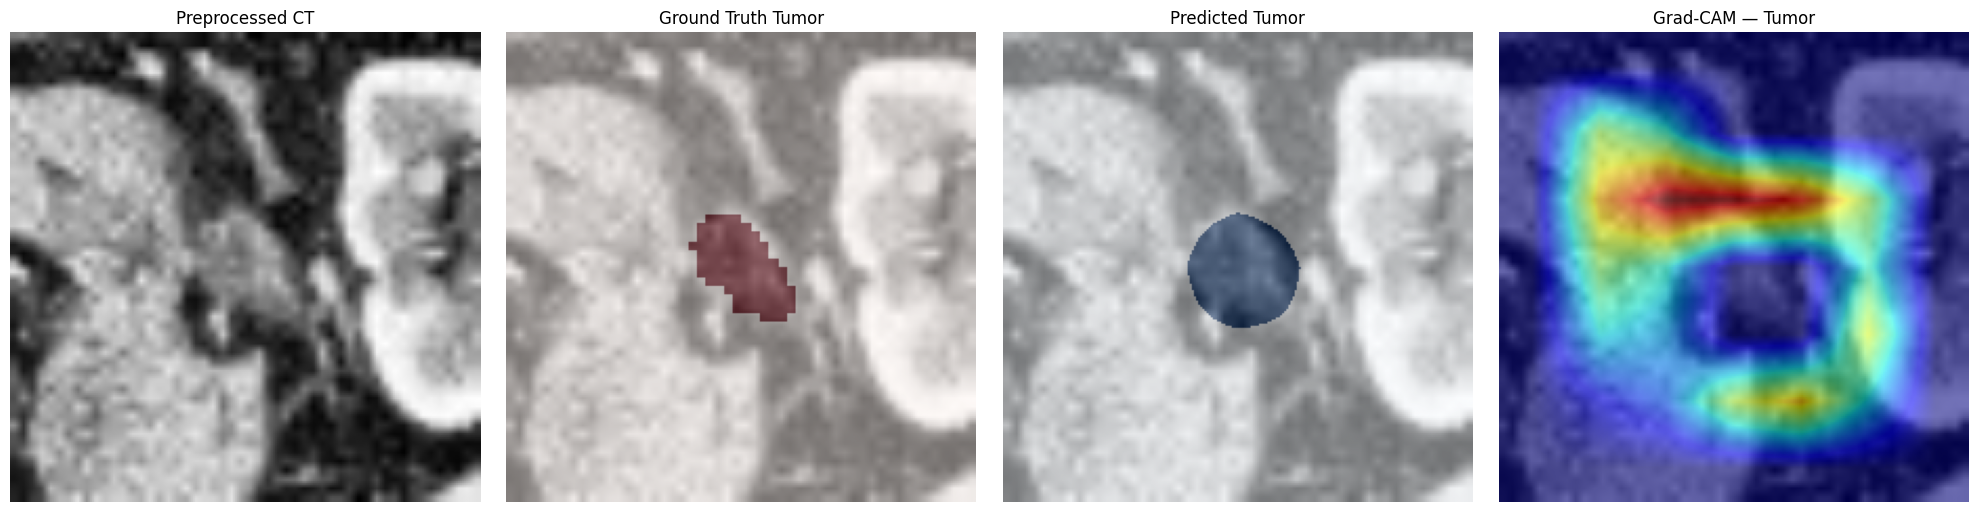


✓ GRAD-CAM VISUALIZATION SAVED
Patient       : c3l_00395
Slice         : 178
Slice Dice    : 0.7725
Saved to      : /kaggle/working/pancreatic_tumor_project/test_results/gradcam/gradcam_c3l_00395_slice_178.png


In [55]:
# ============================================================
# CELL 25B — FIXED GRAD-CAM VISUALIZATION
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

print("=" * 80)
print("VISUALIZING GRAD-CAM")
print("=" * 80)

# ------------------------------------------------------------
# Correct tensor-to-array conversion
# ------------------------------------------------------------

# Ground truth is already [H, W]
gt_mask = ground_truth.detach().cpu().numpy()

# Prediction is [1, H, W], so remove batch dimension
prediction = torch.argmax(
    output.detach(),
    dim=1
)[0].cpu().numpy()

# Input is [1, 1, H, W]
input_image = image[0, 0].detach().cpu().numpy()

gt_tumor = (gt_mask == 1)
predicted_tumor = (prediction == 1)

print(f"Input image shape : {input_image.shape}")
print(f"Ground truth shape: {gt_mask.shape}")
print(f"Prediction shape  : {prediction.shape}")
print(f"Grad-CAM shape    : {cam.shape}")

# ------------------------------------------------------------
# Calculate simple overlap for this displayed slice
# ------------------------------------------------------------
intersection = np.logical_and(
    gt_tumor,
    predicted_tumor
).sum()

gt_pixels = gt_tumor.sum()
pred_pixels = predicted_tumor.sum()

dice = (
    2.0 * intersection /
    (gt_pixels + pred_pixels)
    if (gt_pixels + pred_pixels) > 0
    else 0.0
)

print(f"Ground-truth tumor pixels: {gt_pixels}")
print(f"Predicted tumor pixels   : {pred_pixels}")
print(f"Slice Tumor Dice         : {dice:.4f}")

# ------------------------------------------------------------
# Save directory
# ------------------------------------------------------------
XAI_ROOT = os.path.join(
    PROJECT_ROOT,
    "test_results",
    "gradcam"
)

os.makedirs(XAI_ROOT, exist_ok=True)

patient_id = str(positive_sample["patient_id"])
slice_index = positive_sample["slice_index"]

output_path = os.path.join(
    XAI_ROOT,
    f"gradcam_{patient_id}_slice_{slice_index}.png"
)

# ------------------------------------------------------------
# Create visualization
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    4,
    figsize=(20, 5)
)

# 1. Original preprocessed CT
axes[0].imshow(
    input_image,
    cmap="gray"
)
axes[0].set_title("Preprocessed CT")
axes[0].axis("off")

# 2. Ground truth
axes[1].imshow(
    input_image,
    cmap="gray"
)
axes[1].imshow(
    gt_tumor,
    cmap="Reds",
    alpha=0.45
)
axes[1].set_title("Ground Truth Tumor")
axes[1].axis("off")

# 3. Model prediction
axes[2].imshow(
    input_image,
    cmap="gray"
)
axes[2].imshow(
    predicted_tumor,
    cmap="Blues",
    alpha=0.45
)
axes[2].set_title("Predicted Tumor")
axes[2].axis("off")

# 4. Grad-CAM
axes[3].imshow(
    input_image,
    cmap="gray"
)
axes[3].imshow(
    cam,
    cmap="jet",
    alpha=0.55
)
axes[3].set_title("Grad-CAM — Tumor")
axes[3].axis("off")

plt.tight_layout()

plt.savefig(
    output_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)

print("\n" + "=" * 80)
print("✓ GRAD-CAM VISUALIZATION SAVED")
print("=" * 80)
print(f"Patient       : {patient_id}")
print(f"Slice         : {slice_index}")
print(f"Slice Dice    : {dice:.4f}")
print(f"Saved to      : {output_path}")

In [56]:
# ============================================================
# CELL 26 — FINAL HELD-OUT TEST SET EVALUATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch

print("=" * 80)
print("FINAL HELD-OUT TEST SET EVALUATION")
print("=" * 80)

# ------------------------------------------------------------
# Ensure best Fold 5 model is in evaluation mode
# ------------------------------------------------------------
model.eval()

# ------------------------------------------------------------
# Evaluate on the completely untouched test set
# ------------------------------------------------------------
test_results = validate_model(
    model,
    test_loader,
    criterion,
    DEVICE
)

# ------------------------------------------------------------
# Extract metrics
# ------------------------------------------------------------
test_loss = float(test_results["loss"])

tumor_metrics = test_results["tumor"]
background_metrics = test_results["background"]

print("\n" + "=" * 80)
print("TEST SET RESULTS")
print("=" * 80)

print(f"Test Loss       : {test_loss:.6f}")

print("\n--- TUMOR CLASS (CLASS 1) ---")

for key, value in tumor_metrics.items():
    try:
        print(f"{key:15s}: {float(value):.6f}")
    except:
        print(f"{key:15s}: {value}")

print("\n--- BACKGROUND CLASS (CLASS 0) ---")

for key, value in background_metrics.items():
    try:
        print(f"{key:15s}: {float(value):.6f}")
    except:
        print(f"{key:15s}: {value}")

# ------------------------------------------------------------
# Save final test results
# ------------------------------------------------------------
RESULT_ROOT = os.path.join(
    PROJECT_ROOT,
    "test_results"
)

os.makedirs(RESULT_ROOT, exist_ok=True)

final_test_results = {
    "model": "CNN + GAT",
    "backbone": "EfficientNet-B3",
    "selected_fold": 5,
    "selected_fold_best_validation_dice": 0.842410,
    "test_loss": test_loss,
    "tumor_metrics": {
        k: float(v) if isinstance(v, (int, float, np.integer, np.floating))
        else str(v)
        for k, v in tumor_metrics.items()
    },
    "background_metrics": {
        k: float(v) if isinstance(v, (int, float, np.integer, np.floating))
        else str(v)
        for k, v in background_metrics.items()
    },
    "test_patients": 14,
    "test_patient_split": "patient-wise 15%",
}

test_json = os.path.join(
    RESULT_ROOT,
    "final_test_results_fold5.json"
)

with open(test_json, "w") as f:
    json.dump(final_test_results, f, indent=2)

# ------------------------------------------------------------
# Compact summary table
# ------------------------------------------------------------
summary = pd.DataFrame({
    "Metric": [
        "Loss",
        "Dice",
        "IoU",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "mAP",
        "MCC"
    ],
    "Test Result": [
        test_loss,
        tumor_metrics.get("dice", np.nan),
        tumor_metrics.get("iou", np.nan),
        tumor_metrics.get("precision", np.nan),
        tumor_metrics.get("recall", np.nan),
        tumor_metrics.get("f1", np.nan),
        tumor_metrics.get("roc_auc", np.nan),
        tumor_metrics.get("mAP", tumor_metrics.get("map", np.nan)),
        tumor_metrics.get("mcc", np.nan)
    ]
})

print("\n" + "=" * 80)
print("FINAL TEST SUMMARY")
print("=" * 80)
print(summary.to_string(index=False))

print("\n" + "=" * 80)
print("✓ FINAL HELD-OUT TEST EVALUATION COMPLETE")
print(f"✓ Results saved to: {test_json}")
print("=" * 80)

FINAL HELD-OUT TEST SET EVALUATION


Validation:   0%|          | 0/857 [00:00<?, ?it/s]


TEST SET RESULTS
Test Loss       : 0.326029

--- TUMOR CLASS (CLASS 1) ---
accuracy       : 0.998086
dice           : 0.827239
iou            : 0.705378
precision      : 0.848530
recall         : 0.806991
f1             : 0.827239
roc_auc        : 0.987904
map            : 0.906744
mcc            : 0.826540

--- BACKGROUND CLASS (CLASS 0) ---
accuracy       : 0.998086
dice           : 0.999037
iou            : 0.998077
precision      : 0.998898
recall         : 0.999177
f1             : 0.999037
roc_auc        : 0.987902
map            : 0.999781
mcc            : 0.826540

FINAL TEST SUMMARY
   Metric  Test Result
     Loss     0.326029
     Dice     0.827239
      IoU     0.705378
Precision     0.848530
   Recall     0.806991
       F1     0.827239
  ROC-AUC     0.987904
      mAP     0.906744
      MCC     0.826540

✓ FINAL HELD-OUT TEST EVALUATION COMPLETE
✓ Results saved to: /kaggle/working/pancreatic_tumor_project/test_results/final_test_results_fold5.json


In [58]:
# ============================================================
# CELL 27A — LOCATE c3l_00395.nii
# ============================================================

import os

print("=" * 80)
print("SEARCHING FOR c3l_00395.nii")
print("=" * 80)

matches = []

search_roots = [
    "/kaggle/input",
    "/kaggle/working"
]

for root in search_roots:
    if not os.path.exists(root):
        continue

    for current_root, dirs, files in os.walk(root):
        for file in files:
            if file.lower() == "c3l_00395.nii":
                matches.append(
                    os.path.join(current_root, file)
                )

if not matches:
    print("❌ c3l_00395.nii was not found.")
    print("\nSearching for files containing '00395' instead...\n")

    for root in search_roots:
        if not os.path.exists(root):
            continue

        for current_root, dirs, files in os.walk(root):
            for file in files:
                if "00395" in file.lower():
                    print(
                        os.path.join(current_root, file)
                    )
else:
    print("✓ FOUND:")
    for path in matches:
        print(path)

print("\n" + "=" * 80)
print("SEARCH COMPLETE")
print("=" * 80)

SEARCHING FOR c3l_00395.nii
✓ FOUND:
/kaggle/input/datasets/asham2006/volume-file/Volume files/C3L_00395.nii

SEARCH COMPLETE


TESTING C3L_00395.NII
CT path: /kaggle/input/datasets/asham2006/volume-file/Volume files/C3L_00395.nii
Volume shape : (512, 512, 251)
Minimum HU   : -3024.00
Maximum HU   : 3071.00

Scanning 251 slices...

TOP 10 PREDICTED TUMOR SLICES
 slice  tumor_pixels  tumor_percentage  mean_probability  max_probability
    64           861          1.715960          0.019275         0.997859
    49           639          1.273517          0.014536         0.996768
    50           541          1.078205          0.012737         0.992240
    38           541          1.078205          0.012911         0.989321
   181           534          1.064254          0.011831         0.997709
    61           506          1.008450          0.012452         0.987397
    62           488          0.972577          0.012203         0.982116
   243           483          0.962612          0.011597         0.987866
   169           472          0.940689          0.011111         0.991840
    54           455    

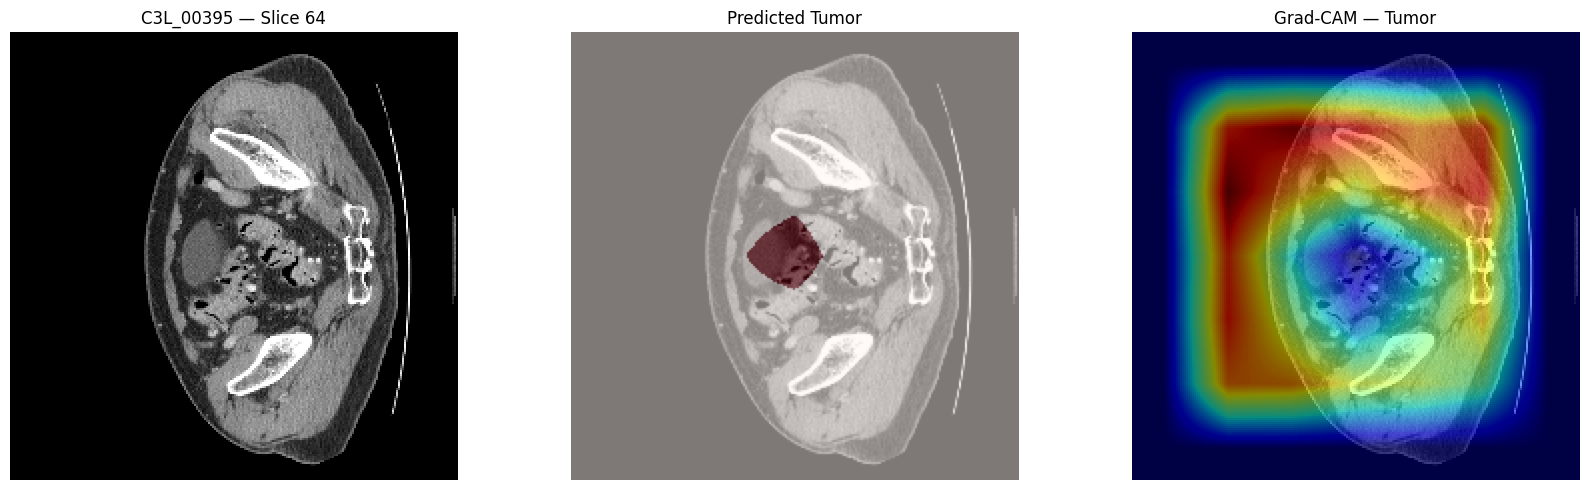


✓ NIFTI INFERENCE + GRAD-CAM COMPLETE
CT volume       : C3L_00395.nii
Best slice      : 64
Tumor detected  : True
Grad-CAM saved  : /kaggle/working/pancreatic_tumor_project/test_results/nii_inference/C3L_00395_slice_64_gradcam.png
CSV saved       : /kaggle/working/pancreatic_tumor_project/test_results/nii_inference/C3L_00395_slice_predictions.csv


In [59]:
# ============================================================
# CELL 27B — TEST C3L_00395.NII WITHOUT MASK
# ============================================================

# Correct path discovered in Cell 27A
CT_PATH = (
    "/kaggle/input/datasets/asham2006/"
    "volume-file/Volume files/C3L_00395.nii"
)

print("=" * 80)
print("TESTING C3L_00395.NII")
print("=" * 80)
print(f"CT path: {CT_PATH}")

# ------------------------------------------------------------
# Verify file
# ------------------------------------------------------------
if not os.path.exists(CT_PATH):
    raise FileNotFoundError(
        f"File not found:\n{CT_PATH}"
    )

# ------------------------------------------------------------
# Load NIfTI
# ------------------------------------------------------------
nii = nib.load(CT_PATH)

volume = nii.get_fdata(
    dtype=np.float32
)

print(f"Volume shape : {volume.shape}")
print(f"Minimum HU   : {volume.min():.2f}")
print(f"Maximum HU   : {volume.max():.2f}")

# ------------------------------------------------------------
# Preprocessing
# ------------------------------------------------------------
def preprocess_inference_slice(slice_2d):

    # CT window: center 40, width 400
    lower = 40 - 400 / 2
    upper = 40 + 400 / 2

    slice_2d = np.clip(
        slice_2d,
        lower,
        upper
    )

    # [0,1]
    slice_2d = (
        slice_2d - lower
    ) / (
        upper - lower
    )

    # Resize to 224 x 224
    tensor = torch.tensor(
        slice_2d,
        dtype=torch.float32
    ).unsqueeze(0).unsqueeze(0)

    tensor = torch.nn.functional.interpolate(
        tensor,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    tensor = tensor[0, 0]

    # Z-score
    mean = tensor.mean()
    std = tensor.std()

    if std > 1e-8:
        tensor = (
            tensor - mean
        ) / std

    return tensor


# ------------------------------------------------------------
# Scan all slices
# ------------------------------------------------------------
model.eval()

num_slices = volume.shape[2]

slice_results = []

print(f"\nScanning {num_slices} slices...")

for slice_idx in range(num_slices):

    processed = preprocess_inference_slice(
        volume[:, :, slice_idx]
    )

    input_tensor = (
        processed
        .unsqueeze(0)
        .unsqueeze(0)
        .to(DEVICE)
    )

    with torch.no_grad():

        output = model(
            input_tensor
        )

        probabilities = torch.softmax(
            output,
            dim=1
        )

        tumor_probability = (
            probabilities[:, 1]
        )

        prediction = torch.argmax(
            output,
            dim=1
        )[0]

    tumor_mask = (
        prediction == 1
    )

    tumor_pixels = int(
        tumor_mask.sum().item()
    )

    mean_probability = float(
        tumor_probability.mean().item()
    )

    max_probability = float(
        tumor_probability.max().item()
    )

    slice_results.append({
        "slice": slice_idx,
        "tumor_pixels": tumor_pixels,
        "tumor_percentage":
            tumor_pixels / (224 * 224) * 100,
        "mean_probability":
            mean_probability,
        "max_probability":
            max_probability
    })

# ------------------------------------------------------------
# Results table
# ------------------------------------------------------------
results_df = pd.DataFrame(
    slice_results
)

results_df = results_df.sort_values(
    by=[
        "tumor_pixels",
        "max_probability"
    ],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 80)
print("TOP 10 PREDICTED TUMOR SLICES")
print("=" * 80)

print(
    results_df.head(10).to_string(
        index=False
    )
)

# ------------------------------------------------------------
# Select strongest slice
# ------------------------------------------------------------
best_row = results_df.iloc[0]

best_slice_idx = int(
    best_row["slice"]
)

best_tumor_pixels = int(
    best_row["tumor_pixels"]
)

best_tumor_percentage = float(
    best_row["tumor_percentage"]
)

# ------------------------------------------------------------
# Tumor / no-tumor decision
# ------------------------------------------------------------
TUMOR_PIXEL_THRESHOLD = 100

tumor_detected = (
    best_tumor_pixels >=
    TUMOR_PIXEL_THRESHOLD
)

print("\n" + "=" * 80)

if tumor_detected:
    print("🟠 TUMOR DETECTED")
else:
    print("🟢 NO TUMOR DETECTED")

print("=" * 80)

print(f"Strongest slice       : {best_slice_idx}")
print(f"Predicted tumor pixels: {best_tumor_pixels}")
print(f"Tumor area            : {best_tumor_percentage:.4f}%")
print(
    f"Maximum probability   : "
    f"{best_row['max_probability']:.4f}"
)

# ------------------------------------------------------------
# Prepare best slice for Grad-CAM
# ------------------------------------------------------------
best_slice = volume[
    :, :,
    best_slice_idx
]

processed = preprocess_inference_slice(
    best_slice
)

input_tensor = (
    processed
    .unsqueeze(0)
    .unsqueeze(0)
    .to(DEVICE)
)

# ------------------------------------------------------------
# Grad-CAM
# ------------------------------------------------------------
activation = None

def gradcam_hook(
    module,
    inputs,
    output
):

    global activation

    if isinstance(
        output,
        (list, tuple)
    ):
        activation = [
            x for x in output
            if torch.is_tensor(x)
        ][-1]
    else:
        activation = output


hook = model.backbone.register_forward_hook(
    gradcam_hook
)

model.zero_grad(
    set_to_none=True
)

output = model(
    input_tensor
)

prediction = torch.argmax(
    output,
    dim=1
)[0]

predicted_tumor = (
    prediction == 1
)

tumor_logits = output[:, 1]

target_mask = (
    predicted_tumor
    .float()
    .unsqueeze(0)
)

if target_mask.sum() > 0:

    target_score = (
        tumor_logits *
        target_mask
    ).sum()

else:

    target_score = tumor_logits.max()

gradients = torch.autograd.grad(
    target_score,
    activation
)[0]

hook.remove()

weights = gradients.mean(
    dim=(2, 3),
    keepdim=True
)

cam = (
    weights * activation
).sum(
    dim=1,
    keepdim=True
)

cam = torch.relu(cam)

cam = torch.nn.functional.interpolate(
    cam,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

cam = cam[
    0, 0
].detach().cpu().numpy()

# Normalize CAM
cam_min = cam.min()
cam_max = cam.max()

if cam_max > cam_min:

    cam = (
        cam - cam_min
    ) / (
        cam_max - cam_min
    )
else:

    cam = np.zeros_like(cam)

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------
input_display = (
    processed
    .detach()
    .cpu()
    .numpy()
)

prediction_display = (
    predicted_tumor
    .detach()
    .cpu()
    .numpy()
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)

axes[0].imshow(
    input_display,
    cmap="gray"
)

axes[0].set_title(
    f"C3L_00395 — Slice {best_slice_idx}"
)

axes[0].axis("off")

axes[1].imshow(
    input_display,
    cmap="gray"
)

axes[1].imshow(
    prediction_display,
    cmap="Reds",
    alpha=0.50
)

axes[1].set_title(
    "Predicted Tumor"
)

axes[1].axis("off")

axes[2].imshow(
    input_display,
    cmap="gray"
)

axes[2].imshow(
    cam,
    cmap="jet",
    alpha=0.55
)

axes[2].set_title(
    "Grad-CAM — Tumor"
)

axes[2].axis("off")

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------
XAI_ROOT = os.path.join(
    PROJECT_ROOT,
    "test_results",
    "nii_inference"
)

os.makedirs(
    XAI_ROOT,
    exist_ok=True
)

result_path = os.path.join(
    XAI_ROOT,
    f"C3L_00395_slice_{best_slice_idx}_gradcam.png"
)

fig.savefig(
    result_path,
    dpi=150,
    bbox_inches="tight"
)

plt.close(fig)

csv_path = os.path.join(
    XAI_ROOT,
    "C3L_00395_slice_predictions.csv"
)

results_df.to_csv(
    csv_path,
    index=False
)

print("\n" + "=" * 80)
print("✓ NIFTI INFERENCE + GRAD-CAM COMPLETE")
print("=" * 80)

print(f"CT volume       : C3L_00395.nii")
print(f"Best slice      : {best_slice_idx}")
print(f"Tumor detected  : {tumor_detected}")
print(f"Grad-CAM saved  : {result_path}")
print(f"CSV saved       : {csv_path}")
print("=" * 80)

TUMOR SEGMENTATION BOUNDARY + GRAD-CAM
CT shape          : (224, 224)
Prediction shape  : (224, 224)
Tumor pixels      : 861
Tumor boundaries found: 1


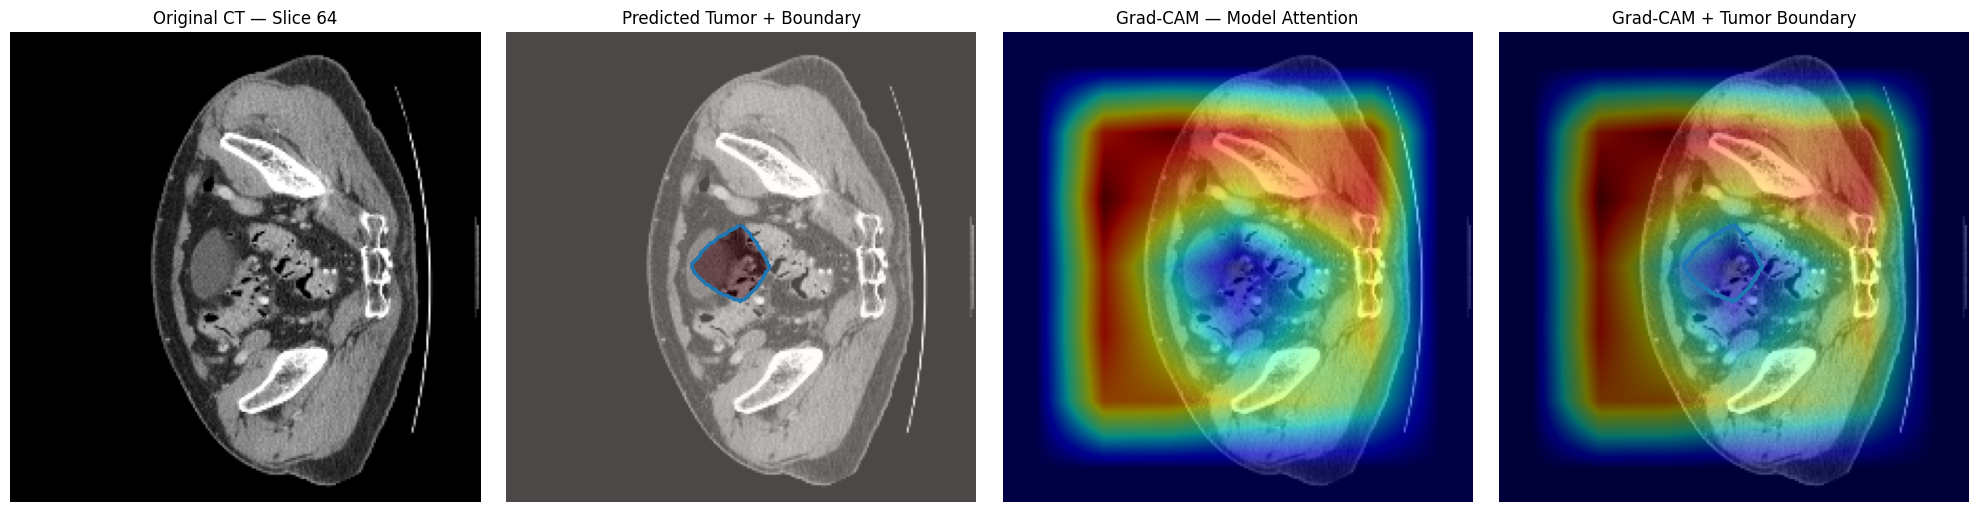


✓ BOUNDARY VISUALIZATION COMPLETE
Tumor pixels       : 861
Number of contours : 1
Saved to           : /kaggle/working/pancreatic_tumor_project/test_results/nii_inference/C3L_00395_slice_64_boundary_gradcam.png


In [60]:
# ============================================================
# CELL 28 — TUMOR BOUNDARY + GRAD-CAM VISUALIZATION
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import cv2

print("=" * 80)
print("TUMOR SEGMENTATION BOUNDARY + GRAD-CAM")
print("=" * 80)

# ------------------------------------------------------------
# Current prediction from C3L_00395
# ------------------------------------------------------------
image_display = (
    processed.detach()
    .cpu()
    .numpy()
)

prediction_mask = (
    predicted_tumor.detach()
    .cpu()
    .numpy()
    .astype(np.uint8)
)

print(f"CT shape          : {image_display.shape}")
print(f"Prediction shape  : {prediction_mask.shape}")
print(f"Tumor pixels      : {prediction_mask.sum()}")

# ------------------------------------------------------------
# Find tumor contours
# ------------------------------------------------------------
contours, hierarchy = cv2.findContours(
    prediction_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

print(f"Tumor boundaries found: {len(contours)}")

# ------------------------------------------------------------
# Create boundary overlay
# ------------------------------------------------------------
boundary_image = np.stack(
    [image_display] * 3,
    axis=-1
)

# Normalize CT for RGB display
img_min = boundary_image.min()
img_max = boundary_image.max()

if img_max > img_min:
    boundary_image = (
        boundary_image - img_min
    ) / (img_max - img_min)

# Draw predicted tumor boundary
cv2.drawContours(
    boundary_image,
    contours,
    -1,
    (1.0, 0.0, 0.0),   # RED boundary
    3
)

# ------------------------------------------------------------
# Create filled + boundary visualization
# ------------------------------------------------------------
filled_overlay = np.stack(
    [image_display] * 3,
    axis=-1
)

if img_max > img_min:
    filled_overlay = (
        filled_overlay - img_min
    ) / (img_max - img_min)

# Fill tumor region lightly
mask_bool = prediction_mask.astype(bool)

filled_overlay[mask_bool, 0] = 1.0
filled_overlay[mask_bool, 1] *= 0.45
filled_overlay[mask_bool, 2] *= 0.45

# Draw strong red boundary
cv2.drawContours(
    filled_overlay,
    contours,
    -1,
    (1.0, 0.0, 0.0),
    3
)

# ------------------------------------------------------------
# Combined Grad-CAM + boundary
# ------------------------------------------------------------
gradcam_overlay = np.stack(
    [image_display] * 3,
    axis=-1
)

if img_max > img_min:
    gradcam_overlay = (
        gradcam_overlay - img_min
    ) / (img_max - img_min)

# Create matplotlib figure
fig, axes = plt.subplots(
    1,
    4,
    figsize=(20, 5)
)

# ------------------------------------------------------------
# 1. Original CT
# ------------------------------------------------------------
axes[0].imshow(
    image_display,
    cmap="gray"
)

axes[0].set_title(
    f"Original CT — Slice {best_slice_idx}"
)

axes[0].axis("off")

# ------------------------------------------------------------
# 2. Segmentation boundary
# ------------------------------------------------------------
axes[1].imshow(
    image_display,
    cmap="gray"
)

# Filled predicted tumor
axes[1].imshow(
    prediction_mask,
    cmap="Reds",
    alpha=0.30
)

# Explicit tumor contour
for contour in contours:
    contour = contour.squeeze()

    if contour.ndim == 2:
        axes[1].plot(
            contour[:, 0],
            contour[:, 1],
            linewidth=2.5
        )

axes[1].set_title(
    "Predicted Tumor + Boundary"
)

axes[1].axis("off")

# ------------------------------------------------------------
# 3. Grad-CAM
# ------------------------------------------------------------
axes[2].imshow(
    image_display,
    cmap="gray"
)

axes[2].imshow(
    cam,
    cmap="jet",
    alpha=0.55
)

axes[2].set_title(
    "Grad-CAM — Model Attention"
)

axes[2].axis("off")

# ------------------------------------------------------------
# 4. Grad-CAM + Tumor Boundary
# ------------------------------------------------------------
axes[3].imshow(
    image_display,
    cmap="gray"
)

axes[3].imshow(
    cam,
    cmap="jet",
    alpha=0.45
)

# Draw tumor boundary in red
for contour in contours:
    contour = contour.squeeze()

    if contour.ndim == 2:
        axes[3].plot(
            contour[:, 0],
            contour[:, 1],
            linewidth=3
        )

axes[3].set_title(
    "Grad-CAM + Tumor Boundary"
)

axes[3].axis("off")

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# Save visualization
# ------------------------------------------------------------
XAI_ROOT = os.path.join(
    PROJECT_ROOT,
    "test_results",
    "nii_inference"
)

os.makedirs(
    XAI_ROOT,
    exist_ok=True
)

boundary_path = os.path.join(
    XAI_ROOT,
    f"C3L_00395_slice_{best_slice_idx}_boundary_gradcam.png"
)

fig.savefig(
    boundary_path,
    dpi=200,
    bbox_inches="tight"
)

plt.close(fig)

print("\n" + "=" * 80)
print("✓ BOUNDARY VISUALIZATION COMPLETE")
print("=" * 80)

print(
    f"Tumor pixels       : "
    f"{prediction_mask.sum()}"
)

print(
    f"Number of contours : "
    f"{len(contours)}"
)

print(
    f"Saved to           : "
    f"{boundary_path}"
)

print("=" * 80)

CLEAR TUMOR BOUNDARY + GRAD-CAM VISUALIZATION
Tumor pixels : 861
Contours     : 1


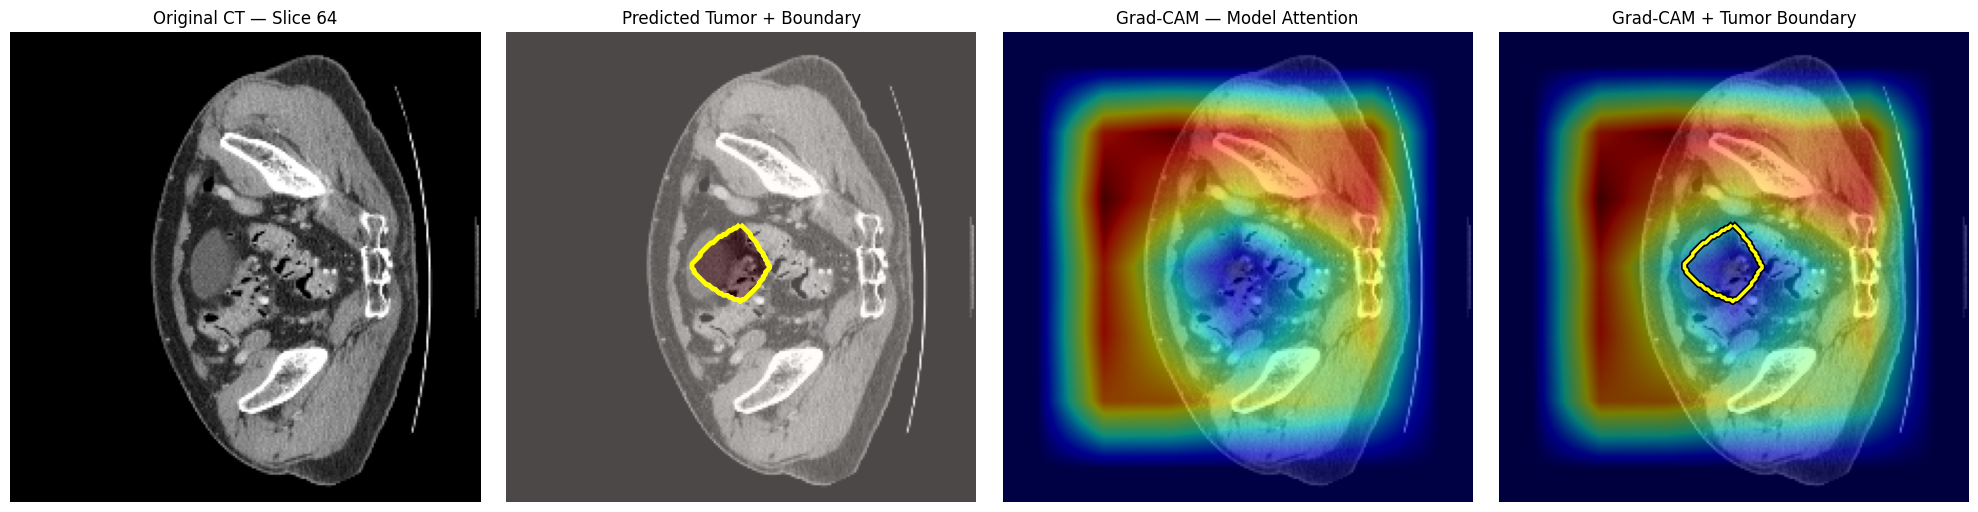


✓ FINAL XAI VISUALIZATION SAVED
Boundary color : YELLOW
Grad-CAM       : JET heatmap
Saved to       : /kaggle/working/pancreatic_tumor_project/test_results/nii_inference/C3L_00395_slice_64_FINAL_XAI.png


In [61]:
# ============================================================
# CELL 28B — CLEAR, DISTINCT TUMOR BOUNDARY
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import cv2

print("=" * 80)
print("CLEAR TUMOR BOUNDARY + GRAD-CAM VISUALIZATION")
print("=" * 80)

# ------------------------------------------------------------
# Prepare prediction mask
# ------------------------------------------------------------
image_display = (
    processed.detach()
    .cpu()
    .numpy()
)

prediction_mask = (
    predicted_tumor.detach()
    .cpu()
    .numpy()
    .astype(np.uint8)
)

# ------------------------------------------------------------
# Find tumor contours
# ------------------------------------------------------------
contours, _ = cv2.findContours(
    prediction_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

print(f"Tumor pixels : {prediction_mask.sum()}")
print(f"Contours     : {len(contours)}")

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    4,
    figsize=(20, 5)
)

# ============================================================
# 1. ORIGINAL CT
# ============================================================
axes[0].imshow(
    image_display,
    cmap="gray"
)

axes[0].set_title(
    f"Original CT — Slice {best_slice_idx}"
)

axes[0].axis("off")


# ============================================================
# 2. PREDICTED TUMOR + CLEAR BOUNDARY
# ============================================================
axes[1].imshow(
    image_display,
    cmap="gray"
)

# Transparent tumor segmentation
axes[1].imshow(
    prediction_mask,
    cmap="Reds",
    alpha=0.30
)

# Draw boundary in BRIGHT YELLOW
for contour in contours:

    contour = contour.squeeze()

    if contour.ndim == 2:

        axes[1].plot(
            contour[:, 0],
            contour[:, 1],
            color="yellow",
            linewidth=3.5
        )

axes[1].set_title(
    "Predicted Tumor + Boundary"
)

axes[1].axis("off")


# ============================================================
# 3. GRAD-CAM
# ============================================================
axes[2].imshow(
    image_display,
    cmap="gray"
)

axes[2].imshow(
    cam,
    cmap="jet",
    alpha=0.55
)

axes[2].set_title(
    "Grad-CAM — Model Attention"
)

axes[2].axis("off")


# ============================================================
# 4. GRAD-CAM + CLEAR TUMOR BOUNDARY
# ============================================================
axes[3].imshow(
    image_display,
    cmap="gray"
)

# Grad-CAM heatmap
axes[3].imshow(
    cam,
    cmap="jet",
    alpha=0.50
)

# ------------------------------------------------------------
# Draw boundary with BLACK OUTER EDGE + YELLOW INNER EDGE
# This makes it visible over every Grad-CAM color.
# ------------------------------------------------------------
for contour in contours:

    contour = contour.squeeze()

    if contour.ndim == 2:

        # Outer black border
        axes[3].plot(
            contour[:, 0],
            contour[:, 1],
            color="black",
            linewidth=5
        )

        # Bright yellow tumor boundary
        axes[3].plot(
            contour[:, 0],
            contour[:, 1],
            color="yellow",
            linewidth=2.5
        )

axes[3].set_title(
    "Grad-CAM + Tumor Boundary"
)

axes[3].axis("off")

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# Save final XAI visualization
# ------------------------------------------------------------
XAI_ROOT = os.path.join(
    PROJECT_ROOT,
    "test_results",
    "nii_inference"
)

os.makedirs(
    XAI_ROOT,
    exist_ok=True
)

final_path = os.path.join(
    XAI_ROOT,
    f"C3L_00395_slice_{best_slice_idx}_FINAL_XAI.png"
)

fig.savefig(
    final_path,
    dpi=200,
    bbox_inches="tight"
)

plt.close(fig)

print("\n" + "=" * 80)
print("✓ FINAL XAI VISUALIZATION SAVED")
print("=" * 80)

print(f"Boundary color : YELLOW")
print(f"Grad-CAM       : JET heatmap")
print(f"Saved to       : {final_path}")
print("=" * 80)

In [63]:
# ============================================================
# CELL 29 — UPLOAD CT IMAGE FROM YOUR COMPUTER
# ============================================================

from IPython.display import display
import ipywidgets as widgets
import os

print("=" * 80)
print("UPLOAD CT IMAGE")
print("=" * 80)
print("Click 'Select files' and choose your CT JPEG/PNG from your PC.")

upload = widgets.FileUpload(
    accept=".jpg,.jpeg,.png,.tif,.tiff",
    multiple=False
)

display(upload)

UPLOAD CT IMAGE
Click 'Select files' and choose your CT JPEG/PNG from your PC.


FileUpload(value=(), accept='.jpg,.jpeg,.png,.tif,.tiff', description='Upload')

In [65]:
# ============================================================
# CELL 30B — SAVE SELECTED CT IMAGE TO KAGGLE
# ============================================================

import os

print("=" * 80)
print("SAVING SELECTED CT IMAGE")
print("=" * 80)

# Check upload
if not upload.value:
    raise RuntimeError(
        "No file selected. Click Upload (1) and select the CT image."
    )

# ------------------------------------------------------------
# Handle Kaggle's ipywidgets FileUpload format
# ------------------------------------------------------------
if isinstance(upload.value, tuple):
    uploaded_file = upload.value[0]

elif isinstance(upload.value, dict):
    uploaded_file = next(iter(upload.value.values()))

else:
    raise TypeError(
        f"Unexpected upload.value type: "
        f"{type(upload.value)}"
    )

# ------------------------------------------------------------
# Get filename and content
# ------------------------------------------------------------
filename = uploaded_file["name"]
file_data = uploaded_file["content"]

# Convert memoryview if necessary
if hasattr(file_data, "tobytes"):
    file_data = file_data.tobytes()

# ------------------------------------------------------------
# Save file
# ------------------------------------------------------------
saved_path = os.path.join(
    "/kaggle/working",
    filename
)

with open(saved_path, "wb") as f:
    f.write(file_data)

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------
if not os.path.exists(saved_path):
    raise RuntimeError(
        "File was not saved successfully."
    )

file_size_mb = (
    os.path.getsize(saved_path)
    / (1024 ** 2)
)

print(f"✓ File name : {filename}")
print(f"✓ Saved to  : {saved_path}")
print(f"✓ Size      : {file_size_mb:.2f} MB")

print("\n" + "=" * 80)
print("✓ CT IMAGE SAVED SUCCESSFULLY")
print("=" * 80)

SAVING SELECTED CT IMAGE
✓ File name : WhatsApp Image 2026-10-05 at 11.36.53 AM.jpeg
✓ Saved to  : /kaggle/working/WhatsApp Image 2026-10-05 at 11.36.53 AM.jpeg
✓ Size      : 0.10 MB

✓ CT IMAGE SAVED SUCCESSFULLY


TESTING UPLOADED CT IMAGE
Image: /kaggle/working/WhatsApp Image 2026-10-05 at 11.36.53 AM.jpeg
Original image shape: (559, 1024)
Model input shape: (1, 1, 224, 224)

🟢 NO TUMOR DETECTED
Predicted tumor pixels : 0
Tumor area             : 0.0000%
Mean tumor probability : 0.0001
Maximum probability    : 0.0013
Predicted tumor boundaries: 0


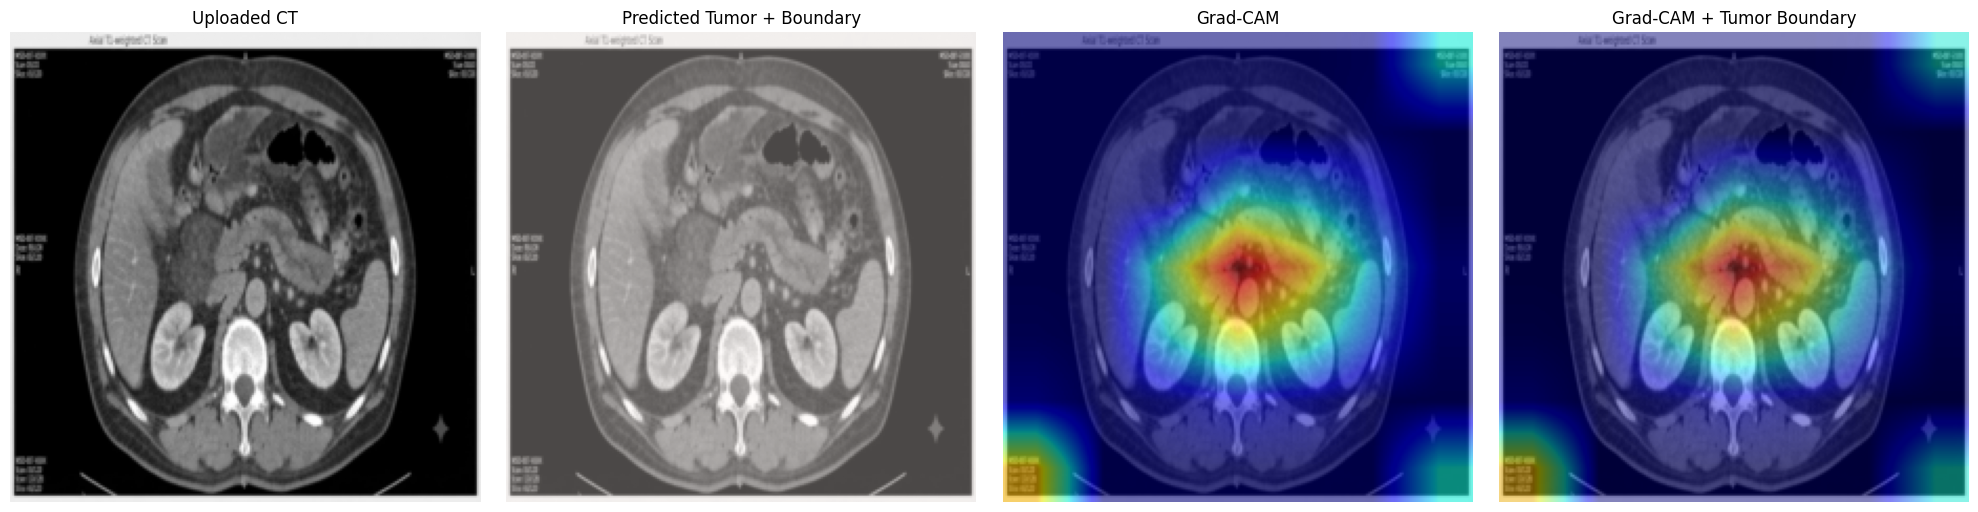


✓ UPLOADED IMAGE TEST COMPLETE
Result saved: /kaggle/working/pancreatic_tumor_project/test_results/uploaded_image/uploaded_ct_gradcam_boundary.png


In [66]:
# ============================================================
# CELL 31 — TEST UPLOADED CT IMAGE
# ============================================================

from PIL import Image
import numpy as np
import torch
import matplotlib.pyplot as plt
import cv2

print("=" * 80)
print("TESTING UPLOADED CT IMAGE")
print("=" * 80)

# ------------------------------------------------------------
# Find the uploaded image
# ------------------------------------------------------------
uploaded_images = []

for file in os.listdir("/kaggle/working"):
    if file.lower().endswith(
        (".jpg", ".jpeg", ".png", ".tif", ".tiff")
    ):
        uploaded_images.append(
            os.path.join("/kaggle/working", file)
        )

if not uploaded_images:
    raise FileNotFoundError(
        "No uploaded CT image found in /kaggle/working."
    )

# Use the most recently created image
IMAGE_PATH = max(
    uploaded_images,
    key=os.path.getmtime
)

print(f"Image: {IMAGE_PATH}")

# ------------------------------------------------------------
# Load image
# ------------------------------------------------------------
pil_image = Image.open(
    IMAGE_PATH
).convert("L")

original_image = np.array(
    pil_image
).astype(np.float32)

print(
    f"Original image shape: "
    f"{original_image.shape}"
)

# ------------------------------------------------------------
# Resize to model input
# ------------------------------------------------------------
resized_image = Image.fromarray(
    original_image
).resize(
    (224, 224),
    Image.BILINEAR
)

image_array = np.array(
    resized_image
).astype(np.float32)

# ------------------------------------------------------------
# Normalize
# ------------------------------------------------------------
img_min = image_array.min()
img_max = image_array.max()

if img_max > img_min:

    image_array = (
        image_array - img_min
    ) / (
        img_max - img_min
    )

# Z-score
mean = image_array.mean()
std = image_array.std()

if std > 1e-8:

    image_array = (
        image_array - mean
    ) / std

# ------------------------------------------------------------
# Convert to tensor
# ------------------------------------------------------------
input_tensor = torch.tensor(
    image_array,
    dtype=torch.float32
).unsqueeze(0).unsqueeze(0).to(DEVICE)

print(
    f"Model input shape: "
    f"{tuple(input_tensor.shape)}"
)

# ------------------------------------------------------------
# Grad-CAM activation hook
# ------------------------------------------------------------
activation = None

def gradcam_hook(
    module,
    inputs,
    output
):

    global activation

    if isinstance(
        output,
        (list, tuple)
    ):

        activation = [
            x for x in output
            if torch.is_tensor(x)
        ][-1]

    else:

        activation = output


hook = model.backbone.register_forward_hook(
    gradcam_hook
)

# ------------------------------------------------------------
# Forward pass
# ------------------------------------------------------------
model.eval()

model.zero_grad(
    set_to_none=True
)

output = model(
    input_tensor
)

probabilities = torch.softmax(
    output,
    dim=1
)

tumor_probability = probabilities[
    0, 1
]

prediction = torch.argmax(
    output,
    dim=1
)[0]

predicted_tumor = (
    prediction == 1
)

tumor_pixels = int(
    predicted_tumor.sum().item()
)

tumor_percentage = (
    tumor_pixels /
    (224 * 224)
) * 100

max_probability = float(
    tumor_probability.max().item()
)

mean_probability = float(
    tumor_probability.mean().item()
)

# ------------------------------------------------------------
# Tumor detection
# ------------------------------------------------------------
TUMOR_PIXEL_THRESHOLD = 100

tumor_detected = (
    tumor_pixels >=
    TUMOR_PIXEL_THRESHOLD
)

print("\n" + "=" * 80)

if tumor_detected:
    print("🟠 TUMOR DETECTED")
else:
    print("🟢 NO TUMOR DETECTED")

print("=" * 80)

print(
    f"Predicted tumor pixels : "
    f"{tumor_pixels}"
)

print(
    f"Tumor area             : "
    f"{tumor_percentage:.4f}%"
)

print(
    f"Mean tumor probability : "
    f"{mean_probability:.4f}"
)

print(
    f"Maximum probability    : "
    f"{max_probability:.4f}"
)

# ------------------------------------------------------------
# Grad-CAM target
# ------------------------------------------------------------
tumor_logits = output[:, 1]

target_mask = (
    predicted_tumor
    .float()
    .unsqueeze(0)
)

if target_mask.sum() > 0:

    target_score = (
        tumor_logits *
        target_mask
    ).sum()

else:

    target_score = (
        tumor_logits.max()
    )

# ------------------------------------------------------------
# Gradients
# ------------------------------------------------------------
gradients = torch.autograd.grad(
    target_score,
    activation,
    retain_graph=False,
    create_graph=False
)[0]

hook.remove()

# ------------------------------------------------------------
# Grad-CAM
# ------------------------------------------------------------
weights = gradients.mean(
    dim=(2, 3),
    keepdim=True
)

cam = (
    weights * activation
).sum(
    dim=1,
    keepdim=True
)

cam = torch.relu(cam)

cam = torch.nn.functional.interpolate(
    cam,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

cam = cam[
    0, 0
].detach().cpu().numpy()

# Normalize
cam_min = cam.min()
cam_max = cam.max()

if cam_max > cam_min:

    cam = (
        cam - cam_min
    ) / (
        cam_max - cam_min
    )

else:

    cam = np.zeros_like(cam)

# ------------------------------------------------------------
# Find predicted tumor boundary
# ------------------------------------------------------------
prediction_mask = (
    predicted_tumor
    .detach()
    .cpu()
    .numpy()
    .astype(np.uint8)
)

contours, _ = cv2.findContours(
    prediction_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

print(
    f"Predicted tumor boundaries: "
    f"{len(contours)}"
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    4,
    figsize=(20, 5)
)

# Original
axes[0].imshow(
    image_array,
    cmap="gray"
)

axes[0].set_title(
    "Uploaded CT"
)

axes[0].axis("off")

# Segmentation + boundary
axes[1].imshow(
    image_array,
    cmap="gray"
)

axes[1].imshow(
    prediction_mask,
    cmap="Reds",
    alpha=0.30
)

for contour in contours:

    contour = contour.squeeze()

    if contour.ndim == 2:

        axes[1].plot(
            contour[:, 0],
            contour[:, 1],
            color="yellow",
            linewidth=3
        )

axes[1].set_title(
    "Predicted Tumor + Boundary"
)

axes[1].axis("off")

# Grad-CAM
axes[2].imshow(
    image_array,
    cmap="gray"
)

axes[2].imshow(
    cam,
    cmap="jet",
    alpha=0.55
)

axes[2].set_title(
    "Grad-CAM"
)

axes[2].axis("off")

# Combined
axes[3].imshow(
    image_array,
    cmap="gray"
)

axes[3].imshow(
    cam,
    cmap="jet",
    alpha=0.45
)

for contour in contours:

    contour = contour.squeeze()

    if contour.ndim == 2:

        # Black outer border
        axes[3].plot(
            contour[:, 0],
            contour[:, 1],
            color="black",
            linewidth=5
        )

        # Yellow tumor boundary
        axes[3].plot(
            contour[:, 0],
            contour[:, 1],
            color="yellow",
            linewidth=2.5
        )

axes[3].set_title(
    "Grad-CAM + Tumor Boundary"
)

axes[3].axis("off")

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
XAI_ROOT = os.path.join(
    PROJECT_ROOT,
    "test_results",
    "uploaded_image"
)

os.makedirs(
    XAI_ROOT,
    exist_ok=True
)

save_path = os.path.join(
    XAI_ROOT,
    "uploaded_ct_gradcam_boundary.png"
)

fig.savefig(
    save_path,
    dpi=200,
    bbox_inches="tight"
)

plt.close(fig)

print("\n" + "=" * 80)
print("✓ UPLOADED IMAGE TEST COMPLETE")
print("=" * 80)
print(f"Result saved: {save_path}")
print("=" * 80)

In [74]:
# ============================================================
# CELL 32 — VERIFY EXTERNAL KAGGLE NIfTI INPUT
# ============================================================

import os
import glob
import nibabel as nib
import numpy as np

# Search all Kaggle input directories for the external NIfTI
nii_files = sorted(
    glob.glob("/kaggle/input/**/*.nii", recursive=True) +
    glob.glob("/kaggle/input/**/*.nii.gz", recursive=True)
)

# Show only files containing pancreas_421
target_files = [
    f for f in nii_files
    if "pancreas_421" in os.path.basename(f).lower()
]

if not target_files:
    print("❌ pancreas_421.nii was not found.")
    print("\nAvailable NIfTI files containing 'pancreas':")

    for f in nii_files:
        if "pancreas" in f.lower():
            print(f)

    raise FileNotFoundError(
        "Kaggle could not find pancreas_421.nii in /kaggle/input/"
    )

EXTERNAL_NII_PATH = target_files[0]

print("=" * 65)
print("✅ EXTERNAL NIfTI FOUND")
print("=" * 65)
print("Path:", EXTERNAL_NII_PATH)

# ------------------------------------------------------------
# Load and verify
# ------------------------------------------------------------
nii = nib.load(EXTERNAL_NII_PATH)
volume = nii.get_fdata(dtype=np.float32)

print("\nNIfTI information")
print("-" * 65)
print("Filename       :", os.path.basename(EXTERNAL_NII_PATH))
print("Shape          :", volume.shape)
print("Data type      :", volume.dtype)
print("Voxel spacing  :", nii.header.get_zooms()[:3])
print("Minimum        :", float(np.min(volume)))
print("Maximum        :", float(np.max(volume)))
print("Mean           :", float(np.mean(volume)))
print("Std            :", float(np.std(volume)))
print("NaN values     :", int(np.isnan(volume).sum()))
print("Inf values     :", int(np.isinf(volume).sum()))

# ------------------------------------------------------------
# Basic validity check
# ------------------------------------------------------------
assert volume.ndim == 3, "❌ CT is not a 3D volume."
assert np.isfinite(volume).all(), "❌ CT contains NaN/Inf values."

print("\n" + "=" * 65)
print("✅ PANCREAS_421 IS READY FOR EXTERNAL INFERENCE")
print("=" * 65)

✅ EXTERNAL NIfTI FOUND
Path: /kaggle/input/datasets/asham2006/pancreas-external-test/pancreas_421.nii

NIfTI information
-----------------------------------------------------------------
Filename       : pancreas_421.nii
Shape          : (512, 512, 131)
Data type      : float32
Voxel spacing  : (np.float32(0.972656), np.float32(0.972656), np.float32(2.0))
Minimum        : -1024.0
Maximum        : 1401.0
Mean           : -590.36962890625
Std            : 477.3095397949219
NaN values     : 0
Inf values     : 0

✅ PANCREAS_421 IS READY FOR EXTERNAL INFERENCE


External CT: pancreas_421.nii
Volume shape: (512, 512, 131)


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.



✅ Fold 5 best model loaded
Best validation Dice: 0.842409972359505

Running inference...
Total slices: 131

EXTERNAL INFERENCE RESULT
File                : pancreas_421.nii
Total slices        : 131
Strongest slice     : 96
Tumor detected      : YES
Predicted tumor px  : 890
Tumor area          : 1.7738%
Maximum tumor prob. : 0.9686


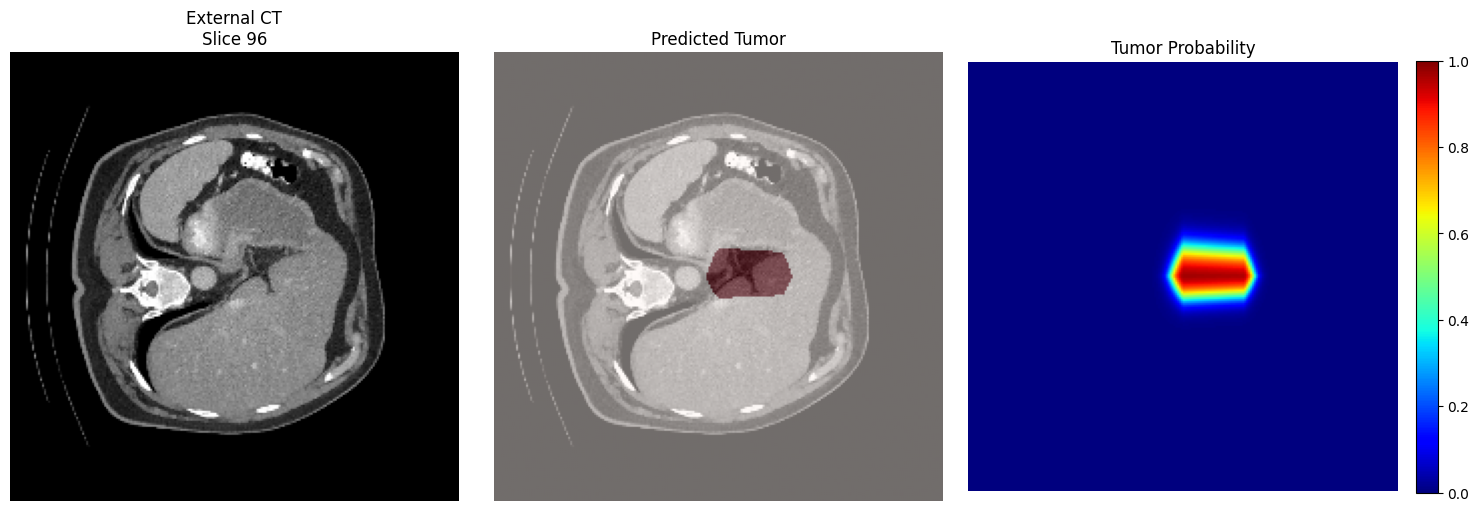


✅ External inference completed.


In [75]:
# ============================================================
# CELL 33 — EXTERNAL NIfTI INFERENCE
# pancreas_421.nii
# ============================================================

import os
import numpy as np
import nibabel as nib
import cv2
import torch
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. External CT path from Cell 32
# ------------------------------------------------------------
EXTERNAL_NII_PATH = (
    "/kaggle/input/datasets/asham2006/"
    "pancreas-external-test/pancreas_421.nii"
)

# ------------------------------------------------------------
# 2. Load CT volume
# ------------------------------------------------------------
nii = nib.load(EXTERNAL_NII_PATH)

volume = nii.get_fdata(dtype=np.float32)

print("External CT:", os.path.basename(EXTERNAL_NII_PATH))
print("Volume shape:", volume.shape)

# ------------------------------------------------------------
# 3. Load Fold 5 BEST MODEL
# ------------------------------------------------------------
MODEL_PATH = (
    "/kaggle/working/pancreatic_tumor_project/"
    "checkpoints/fold_5/best_model.pth"
)

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        f"Fold 5 model not found:\n{MODEL_PATH}"
    )

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

external_model = CNNGATSegmentation(
    num_classes=2,
    gat_hidden=128,
    gat_heads=4,
    gat_layers=4,
    dropout=0.2
)

external_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

external_model.to(DEVICE)
external_model.eval()

print("\n✅ Fold 5 best model loaded")
print(
    "Best validation Dice:",
    checkpoint.get("best_metric", "N/A")
)

# ------------------------------------------------------------
# 4. SAME CT preprocessing used by training
# ------------------------------------------------------------
def preprocess_external_slice(slice_2d):

    img = slice_2d.astype(np.float32)

    img = np.nan_to_num(
        img,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    # CT window: center 40, width 400
    lower = 40 - 400 / 2
    upper = 40 + 400 / 2

    img = np.clip(
        img,
        lower,
        upper
    )

    # Normalize to [0,1]
    img = (
        img - lower
    ) / (
        upper - lower
    )

    # Z-score
    mean = img.mean()
    std = img.std()

    if std > 1e-6:
        img = (img - mean) / std
    else:
        img = img - mean

    # Resize to model input
    img = cv2.resize(
        img,
        (224, 224),
        interpolation=cv2.INTER_LINEAR
    )

    return img.astype(np.float32)

# ------------------------------------------------------------
# 5. Scan ALL slices
# ------------------------------------------------------------
num_slices = volume.shape[2]

tumor_pixel_counts = []
max_tumor_probabilities = []

print("\nRunning inference...")
print(f"Total slices: {num_slices}")

with torch.no_grad():

    for slice_idx in range(num_slices):

        slice_2d = volume[:, :, slice_idx]

        processed = preprocess_external_slice(
            slice_2d
        )

        tensor = torch.from_numpy(
            processed
        ).unsqueeze(0).unsqueeze(0)

        tensor = tensor.to(DEVICE)

        output = external_model(tensor)

        probability = torch.softmax(
            output,
            dim=1
        )[0, 1]

        prediction = (
            probability >= 0.5
        ).float()

        tumor_pixels = int(
            prediction.sum().item()
        )

        max_probability = float(
            probability.max().item()
        )

        tumor_pixel_counts.append(
            tumor_pixels
        )

        max_tumor_probabilities.append(
            max_probability
        )

# ------------------------------------------------------------
# 6. Find strongest slice
# ------------------------------------------------------------
tumor_pixel_counts = np.array(
    tumor_pixel_counts
)

max_tumor_probabilities = np.array(
    max_tumor_probabilities
)

best_slice = int(
    np.argmax(tumor_pixel_counts)
)

best_tumor_pixels = int(
    tumor_pixel_counts[best_slice]
)

best_max_probability = float(
    max_tumor_probabilities[best_slice]
)

tumor_area_percent = (
    best_tumor_pixels /
    (224 * 224)
) * 100

# ------------------------------------------------------------
# 7. Re-run strongest slice
# ------------------------------------------------------------
best_original = volume[
    :, :,
    best_slice
]

best_processed = preprocess_external_slice(
    best_original
)

best_tensor = torch.from_numpy(
    best_processed
).unsqueeze(0).unsqueeze(0).to(DEVICE)

with torch.no_grad():

    best_output = external_model(
        best_tensor
    )

    best_probability = torch.softmax(
        best_output,
        dim=1
    )[0, 1].cpu().numpy()

best_prediction = (
    best_probability >= 0.5
).astype(np.uint8)

# ------------------------------------------------------------
# 8. Results
# ------------------------------------------------------------
print("\n" + "=" * 65)
print("EXTERNAL INFERENCE RESULT")
print("=" * 65)

print("File                :", os.path.basename(EXTERNAL_NII_PATH))
print("Total slices        :", num_slices)
print("Strongest slice     :", best_slice)

print(
    "Tumor detected      :",
    "YES" if best_tumor_pixels > 0 else "NO"
)

print(
    "Predicted tumor px  :",
    best_tumor_pixels
)

print(
    "Tumor area          :",
    f"{tumor_area_percent:.4f}%"
)

print(
    "Maximum tumor prob. :",
    f"{best_max_probability:.4f}"
)

# ------------------------------------------------------------
# 9. Visualization
# ------------------------------------------------------------
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)

plt.imshow(
    best_processed,
    cmap="gray"
)

plt.title(
    f"External CT\nSlice {best_slice}"
)

plt.axis("off")


plt.subplot(1, 3, 2)

plt.imshow(
    best_processed,
    cmap="gray"
)

plt.imshow(
    best_prediction,
    cmap="Reds",
    alpha=0.45
)

plt.title(
    "Predicted Tumor"
)

plt.axis("off")


plt.subplot(1, 3, 3)

plt.imshow(
    best_probability,
    cmap="jet",
    vmin=0,
    vmax=1
)

plt.colorbar(
    fraction=0.046,
    pad=0.04
)

plt.title(
    "Tumor Probability"
)

plt.axis("off")

plt.tight_layout()

plt.show()

print("\n✅ External inference completed.")

External file : pancreas_421.nii
Slice         : 96


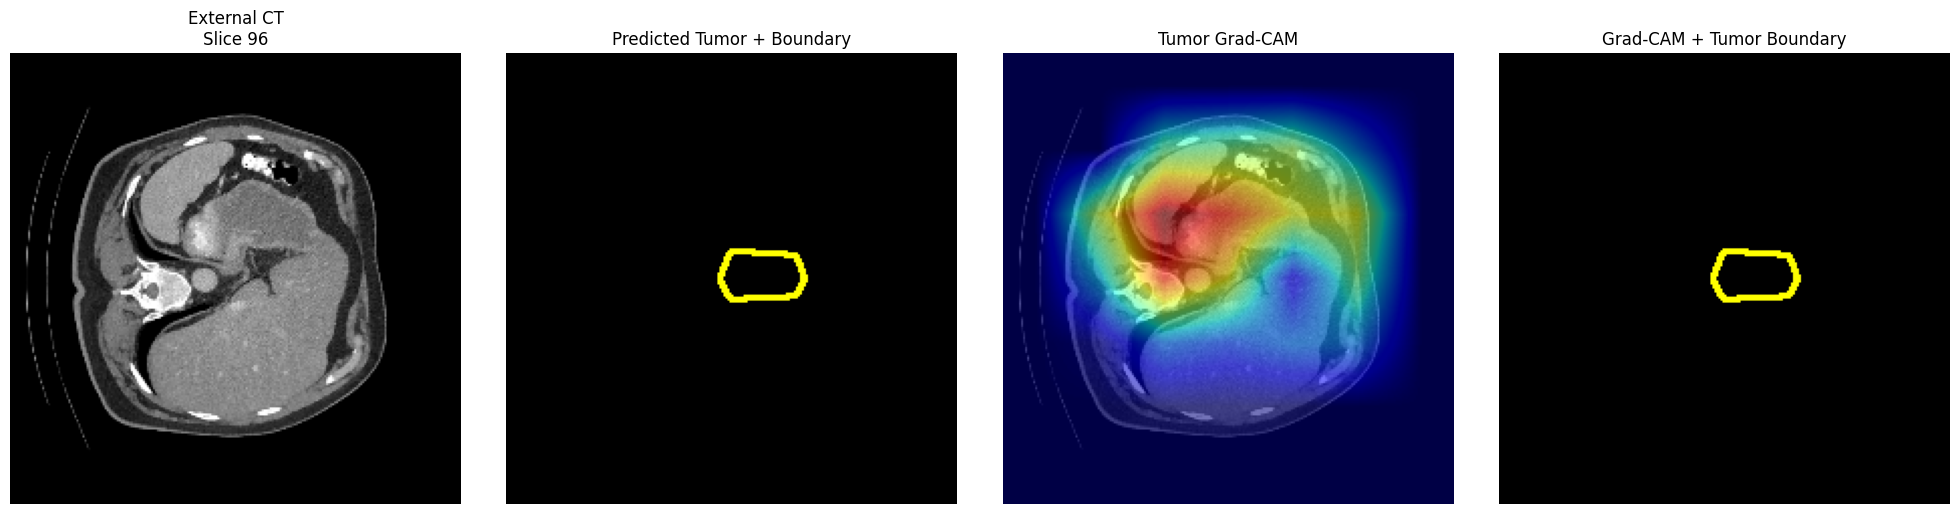


✅ EXTERNAL GRAD-CAM + BOUNDARY COMPLETED
File       : pancreas_421.nii
Slice      : 96
Tumor px   : 890
Max prob.  : 0.9686
Saved to   : /kaggle/working/pancreatic_tumor_project/test_results/external_inference/pancreas_421_external_gradcam_boundary.png


In [76]:
# ============================================================
# CELL 34 — EXTERNAL TUMOR BOUNDARY + GRAD-CAM
# Uses pancreas_421.nii strongest slice from Cell 33
# ============================================================

import os
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Make sure the variables from Cell 33 exist
# ------------------------------------------------------------
if "best_processed" not in globals():
    raise RuntimeError(
        "Run Cell 33 first so that the external inference "
        "variables are available."
    )

print("External file :", "pancreas_421.nii")
print("Slice         :", best_slice)

# ------------------------------------------------------------
# 2. Prepare model for Grad-CAM
# ------------------------------------------------------------
external_model.eval()

activations = {}
gradients = {}

# We hook the EfficientNet feature extractor.
# The model uses the final backbone feature map before GAT.
def forward_hook(module, inputs, output):

    # features_only=True returns a list of feature maps
    if isinstance(output, (list, tuple)):
        feature = output[-1]
    else:
        feature = output

    activations["feature"] = feature
    feature.retain_grad()

# Register hook
hook_handle = external_model.backbone.register_forward_hook(
    forward_hook
)

# ------------------------------------------------------------
# 3. Forward pass WITH gradients
# ------------------------------------------------------------
external_model.zero_grad(set_to_none=True)

gradcam_input = torch.from_numpy(
    best_processed.astype(np.float32)
).unsqueeze(0).unsqueeze(0).to(DEVICE)

gradcam_input.requires_grad_(True)

output = external_model(
    gradcam_input
)

# Tumor class = class 1
tumor_score = output[:, 1].sum()

# Backpropagate tumor score
tumor_score.backward()

# ------------------------------------------------------------
# 4. Get feature activations and gradients
# ------------------------------------------------------------
feature = activations["feature"]
gradient = feature.grad

if gradient is None:
    hook_handle.remove()
    raise RuntimeError(
        "Grad-CAM gradient was not captured."
    )

# Remove hook
hook_handle.remove()

# ------------------------------------------------------------
# 5. Calculate Grad-CAM
# ------------------------------------------------------------
# Global-average-pool gradients
weights = gradient.mean(
    dim=(2, 3),
    keepdim=True
)

cam = (
    weights * feature
).sum(dim=1, keepdim=False)

cam = torch.relu(cam)

cam = cam[0].detach().cpu().numpy()

# Normalize
cam_min = cam.min()
cam_max = cam.max()

if cam_max > cam_min:
    cam = (
        cam - cam_min
    ) / (
        cam_max - cam_min
    )
else:
    cam = np.zeros_like(cam)

# Resize Grad-CAM to 224 x 224
cam = cv2.resize(
    cam,
    (224, 224),
    interpolation=cv2.INTER_LINEAR
)

# ------------------------------------------------------------
# 6. Predicted tumor mask
# ------------------------------------------------------------
pred_mask = (
    best_prediction.astype(np.uint8)
)

# ------------------------------------------------------------
# 7. Extract tumor boundary
# ------------------------------------------------------------
contours, _ = cv2.findContours(
    pred_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

boundary = np.zeros_like(
    pred_mask,
    dtype=np.uint8
)

cv2.drawContours(
    boundary,
    contours,
    -1,
    1,
    thickness=2
)

# ------------------------------------------------------------
# 8. Create boundary overlay
# ------------------------------------------------------------
boundary_rgb = np.zeros(
    (224, 224, 3),
    dtype=np.uint8
)

# Yellow boundary
boundary_rgb[boundary == 1] = [
    255, 255, 0
]

# ------------------------------------------------------------
# 9. Visualization
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    4,
    figsize=(20, 5)
)

# ------------------------------------------------------------
# Panel 1 — Original CT
# ------------------------------------------------------------
axes[0].imshow(
    best_processed,
    cmap="gray"
)

axes[0].set_title(
    f"External CT\nSlice {best_slice}"
)

axes[0].axis("off")


# ------------------------------------------------------------
# Panel 2 — Tumor + Boundary
# ------------------------------------------------------------
axes[1].imshow(
    best_processed,
    cmap="gray"
)

axes[1].imshow(
    pred_mask,
    cmap="Reds",
    alpha=0.35
)

axes[1].imshow(
    boundary_rgb,
    alpha=1.0
)

axes[1].set_title(
    "Predicted Tumor + Boundary"
)

axes[1].axis("off")


# ------------------------------------------------------------
# Panel 3 — Grad-CAM
# ------------------------------------------------------------
axes[2].imshow(
    best_processed,
    cmap="gray"
)

axes[2].imshow(
    cam,
    cmap="jet",
    alpha=0.55,
    vmin=0,
    vmax=1
)

axes[2].set_title(
    "Tumor Grad-CAM"
)

axes[2].axis("off")


# ------------------------------------------------------------
# Panel 4 — Grad-CAM + Boundary
# ------------------------------------------------------------
axes[3].imshow(
    best_processed,
    cmap="gray"
)

axes[3].imshow(
    cam,
    cmap="jet",
    alpha=0.50,
    vmin=0,
    vmax=1
)

axes[3].imshow(
    boundary_rgb,
    alpha=1.0
)

axes[3].set_title(
    "Grad-CAM + Tumor Boundary"
)

axes[3].axis("off")

plt.tight_layout()

# ------------------------------------------------------------
# 10. Save result
# ------------------------------------------------------------
GRADCAM_DIR = (
    "/kaggle/working/pancreatic_tumor_project/"
    "test_results/external_inference"
)

os.makedirs(
    GRADCAM_DIR,
    exist_ok=True
)

save_path = os.path.join(
    GRADCAM_DIR,
    "pancreas_421_external_gradcam_boundary.png"
)

plt.savefig(
    save_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 65)
print("✅ EXTERNAL GRAD-CAM + BOUNDARY COMPLETED")
print("=" * 65)
print("File       : pancreas_421.nii")
print("Slice      :", best_slice)
print("Tumor px   :", best_tumor_pixels)
print("Max prob.  :", f"{best_max_probability:.4f}")
print("Saved to   :", save_path)

CLEAR TUMOR BOUNDARY + GRAD-CAM VISUALIZATION
Tumor pixels : 890
Contours     : 1


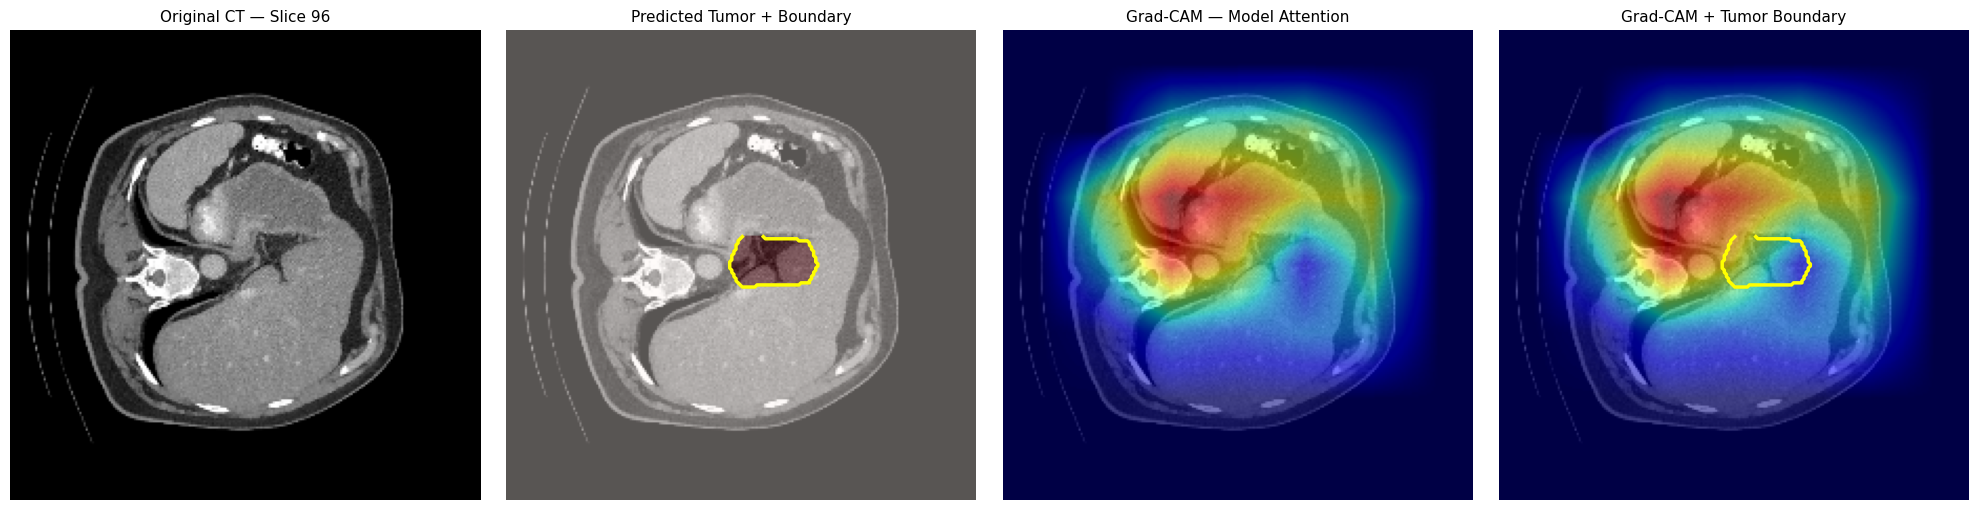


✓ FINAL XAI VISUALIZATION SAVED
File        : pancreas_421.nii
Slice       : 96
Tumor pixels: 890
Contours    : 1
Saved to    : /kaggle/working/pancreatic_tumor_project/test_results/external_inference/pancreas_421_FINAL_XAI_visualization.png


In [77]:
# ============================================================
# CELL 34B — CLEAR TUMOR BOUNDARY + GRAD-CAM VISUALIZATION
# Same style as the reference image
# ============================================================

import os
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Check required variables from Cell 33
# ------------------------------------------------------------
required_vars = [
    "best_processed",
    "best_prediction",
    "best_probability",
    "best_slice",
    "best_tumor_pixels"
]

missing = [
    v for v in required_vars
    if v not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing variables: {missing}. "
        "Run Cell 33 first."
    )

print("=" * 85)
print("CLEAR TUMOR BOUNDARY + GRAD-CAM VISUALIZATION")
print("=" * 85)

print("Tumor pixels :", best_tumor_pixels)

# ------------------------------------------------------------
# 1. Prepare model for Grad-CAM
# ------------------------------------------------------------
external_model.eval()

activations = {}

def forward_hook(module, inputs, output):

    if isinstance(output, (list, tuple)):
        feature = output[-1]
    else:
        feature = output

    activations["feature"] = feature
    feature.retain_grad()

hook_handle = external_model.backbone.register_forward_hook(
    forward_hook
)

# ------------------------------------------------------------
# 2. Forward pass
# ------------------------------------------------------------
external_model.zero_grad(set_to_none=True)

gradcam_input = torch.from_numpy(
    best_processed.astype(np.float32)
).unsqueeze(0).unsqueeze(0).to(DEVICE)

gradcam_input.requires_grad_(True)

output = external_model(gradcam_input)

# Tumor class = 1
tumor_score = output[:, 1].sum()

tumor_score.backward()

# ------------------------------------------------------------
# 3. Get Grad-CAM
# ------------------------------------------------------------
feature = activations["feature"]
gradient = feature.grad

hook_handle.remove()

if gradient is None:
    raise RuntimeError(
        "Grad-CAM gradient was not captured."
    )

# Gradient weights
weights = gradient.mean(
    dim=(2, 3),
    keepdim=True
)

cam = (
    weights * feature
).sum(
    dim=1
)

cam = torch.relu(cam)

cam = cam[0].detach().cpu().numpy()

# Normalize Grad-CAM
cam_min = cam.min()
cam_max = cam.max()

if cam_max > cam_min:
    cam = (
        cam - cam_min
    ) / (
        cam_max - cam_min
    )
else:
    cam = np.zeros_like(cam)

# Resize to 224 x 224
cam = cv2.resize(
    cam,
    (224, 224),
    interpolation=cv2.INTER_LINEAR
)

# ------------------------------------------------------------
# 4. Predicted tumor mask
# ------------------------------------------------------------
pred_mask = (
    best_prediction > 0
).astype(np.uint8)

# ------------------------------------------------------------
# 5. Extract tumor contours
# ------------------------------------------------------------
contours, _ = cv2.findContours(
    pred_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

print("Contours     :", len(contours))

# ------------------------------------------------------------
# 6. Create 4-panel visualization
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    4,
    figsize=(20, 5)
)

# ============================================================
# PANEL 1 — ORIGINAL CT
# ============================================================
axes[0].imshow(
    best_processed,
    cmap="gray"
)

axes[0].set_title(
    f"Original CT — Slice {best_slice}",
    fontsize=11
)

axes[0].axis("off")


# ============================================================
# PANEL 2 — PREDICTED TUMOR + YELLOW BOUNDARY
# ============================================================
axes[1].imshow(
    best_processed,
    cmap="gray"
)

# Tumor fill
axes[1].imshow(
    pred_mask,
    cmap="Reds",
    alpha=0.35,
    vmin=0,
    vmax=1
)

# Yellow boundary
for contour in contours:

    contour = contour.squeeze()

    if contour.ndim == 2 and len(contour) >= 2:

        axes[1].plot(
            contour[:, 0],
            contour[:, 1],
            color="yellow",
            linewidth=2.5
        )

axes[1].set_title(
    "Predicted Tumor + Boundary",
    fontsize=11
)

axes[1].axis("off")


# ============================================================
# PANEL 3 — GRAD-CAM
# ============================================================
axes[2].imshow(
    best_processed,
    cmap="gray"
)

axes[2].imshow(
    cam,
    cmap="jet",
    alpha=0.55,
    vmin=0,
    vmax=1
)

axes[2].set_title(
    "Grad-CAM — Model Attention",
    fontsize=11
)

axes[2].axis("off")


# ============================================================
# PANEL 4 — GRAD-CAM + TUMOR BOUNDARY
# ============================================================
axes[3].imshow(
    best_processed,
    cmap="gray"
)

axes[3].imshow(
    cam,
    cmap="jet",
    alpha=0.55,
    vmin=0,
    vmax=1
)

# Yellow tumor boundary
for contour in contours:

    contour = contour.squeeze()

    if contour.ndim == 2 and len(contour) >= 2:

        axes[3].plot(
            contour[:, 0],
            contour[:, 1],
            color="yellow",
            linewidth=2.5
        )

axes[3].set_title(
    "Grad-CAM + Tumor Boundary",
    fontsize=11
)

axes[3].axis("off")


# ------------------------------------------------------------
# Overall layout
# ------------------------------------------------------------
plt.tight_layout()

# ------------------------------------------------------------
# 7. Save final visualization
# ------------------------------------------------------------
GRADCAM_DIR = (
    "/kaggle/working/pancreatic_tumor_project/"
    "test_results/external_inference"
)

os.makedirs(
    GRADCAM_DIR,
    exist_ok=True
)

save_path = os.path.join(
    GRADCAM_DIR,
    "pancreas_421_FINAL_XAI_visualization.png"
)

plt.savefig(
    save_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 85)
print("✓ FINAL XAI VISUALIZATION SAVED")
print("=" * 85)

print("File        : pancreas_421.nii")
print("Slice       :", best_slice)
print("Tumor pixels:", best_tumor_pixels)
print("Contours    :", len(contours))
print("Saved to    :", save_path)